# Formula 1 Podium Prediction — Milestone 1

**Task.** For every driver in every race, predict whether the driver finishes on the podium (`positionOrder <= 3`).

**Prediction cutoff.** After qualifying, before the race starts. Anything decided in or after the race (result, points, status, laps, pit stops, post-race standings) cannot be a feature.

**Unit of analysis.** One driver entering one race, so `(raceId, driverId)` must be unique in the modeling table.

| # | Section | Status |
| --- | --- | --- |
| 1 | Setup | done |
| 2 | Raw data audit (EDA before cleaning) | done |
| 3 | Data cleaning | done |
| 4 | EDA after cleaning | done |
| 5 | Data-engineering questions | done |
| 6 | Feature engineering | done |
| 7 | Data split | done |
| 8 | Feature selection | done |
| 9 | Preprocessing | done |
| 10 | Hand-off to modeling | done |
| 11 | Baseline and statistical models | to do |
| 12 | Shallow neural network | to do |
| 13 | Model comparison | to do |
| 14 | Feature-group ablation | to do |
| 15 | Explainability (XAI) | to do |
| 16 | Inference function | to do |
| 17 | Assumptions and limitations | started |

The notebook runs top to bottom with Run All, locally or on Kaggle. It uses the CSVs in `data/` or the dataset attached on Kaggle, and downloads the dataset into `data/` if neither is there. Every run overwrites the figures in `report/figures/` and the modeling table in `outputs/`.

## 1. Setup

In [1]:
import json
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.experimental import enable_iterative_imputer  # must come before importing IterativeImputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

SEED = 42
KEY = ['raceId', 'driverId']       # the grain: one row per driver per race
FIG_DIR = Path('report/figures')   # figures reused in the report
OUT_DIR = Path('outputs')          # modeling table written in section 10
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

TABLES = ['circuits', 'constructor_results', 'constructor_standings', 'constructors', 'driver_standings', 'drivers',
          'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']
# latest version of the Kaggle dataset (29 Jan 2025, the author's final update): seasons 1950-2024
DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/rohanrao/formula-1-world-championship-1950-2020'


def get_data_dir():
    # 1. local copy in data/, 2. dataset attached to the Kaggle notebook, 3. download into data/
    local = Path('data')
    if (local / 'results.csv').exists():
        return local
    attached = sorted(Path('/kaggle/input').glob('**/results.csv'))
    if attached:
        return attached[0].parent
    print('Dataset not found, downloading it into data/ ...')
    local.mkdir(exist_ok=True)
    archive = local / 'f1.zip'
    urllib.request.urlretrieve(DATA_URL, archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(local)
    archive.unlink()
    return local


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=120, bbox_inches='tight')


DATA_DIR = get_data_dir()
print('Data folder:', DATA_DIR)
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

Data folder: data
pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1


## 2. Raw data audit (EDA before cleaning)

Every file is read as text with no missing-value parsing, so we see the values exactly as they are stored. These `raw` tables are never modified.

In [2]:
raw = {t: pd.read_csv(DATA_DIR / f'{t}.csv', dtype=str, keep_default_na=False) for t in TABLES}

race_year = raw['races'].set_index('raceId')['year'].astype(int)


def season_of_rows(t):
    # season of every row, for the tables linked to a race or a season (empty for drivers, circuits, ...)
    if 'raceId' in t:
        return t['raceId'].map(race_year)
    if 'year' in t:
        return t['year'].astype(int)
    return pd.Series(dtype=float)


inventory_rows = []
for name, t in raw.items():
    years = season_of_rows(t)
    inventory_rows.append({'table': name, 'rows': len(t), 'columns': t.shape[1],
                           'first season': years.min(), 'last season': years.max()})
inventory = pd.DataFrame(inventory_rows).set_index('table')
inventory

,rows,columns,first season,last season
table,,,,
circuits,77,9,NaN,NaN
constructor_results,12625,5,1958.0,2024.0
constructor_standings,13391,7,1958.0,2024.0
constructors,212,5,NaN,NaN
driver_standings,34863,7,1950.0,2024.0
drivers,861,9,NaN,NaN
lap_times,589081,6,1996.0,2024.0
pit_stops,11371,7,2011.0,2024.0
qualifying,10494,9,1994.0,2024.0


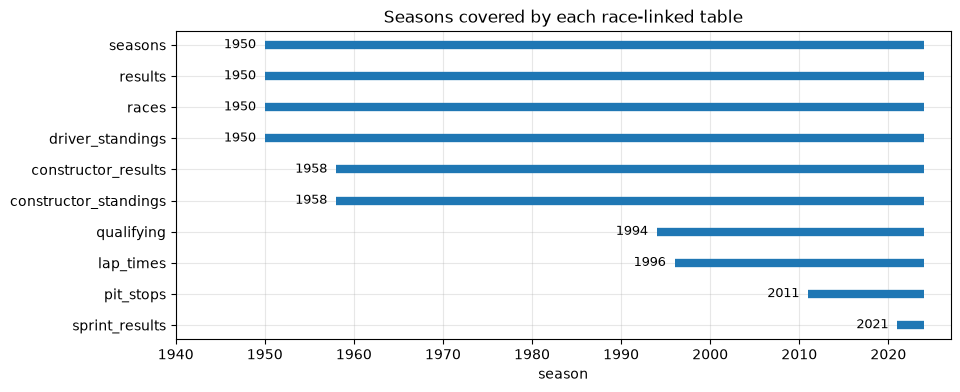

In [3]:
covered = inventory.dropna().sort_values('first season', ascending=False)
y = np.arange(len(covered))
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(y, covered['first season'], covered['last season'], lw=6)
for i, first in enumerate(covered['first season']):
    ax.text(first - 1, i, str(int(first)), ha='right', va='center', fontsize=9)
ax.set_yticks(y, covered.index.tolist())
ax.set_xlim(1940, 2027)
ax.set_title('Seasons covered by each race-linked table')
ax.set_xlabel('season')
save_fig('table_coverage')
plt.show()

`results`, `races` and the driver standings cover 1950–2024, but `qualifying` only starts in 1994, `lap_times` in 1996, `pit_stops` in 2011 and `sprint_results` in 2021. Any feature taken from a late-starting table will be missing for the earlier seasons.

### 2.1 Column profile

For every column of every table: how many distinct values, the share stored as a missing-value marker (`\N` or empty, see 2.2), the range (for numbers and ISO dates) and three example values. Everything is still text here, so this shows the data exactly as stored, before any decision.

In [4]:
def column_profile(t):
    rows = []
    for col in t.columns:
        values = t.loc[~t[col].isin(['\\N', '']), col]
        numbers = pd.to_numeric(values, errors='coerce')
        if len(values) and numbers.notna().all():
            low, high = numbers.min(), numbers.max()
        elif len(values) and values.str.fullmatch(r'\d{4}-\d{2}-\d{2}').all():
            low, high = values.min(), values.max()
        else:
            low, high = '', ''
        rows.append({'column': col, 'distinct': values.nunique(), 'missing': round(1 - len(values) / len(t), 3),
                     'min': low, 'max': high, 'examples': ' | '.join(values.drop_duplicates().head(3))})
    return pd.DataFrame(rows).set_index('column')


for name, t in raw.items():
    print(f'{name}: {len(t):,} rows')
    display(column_profile(t))

circuits: 77 rows


,distinct,missing,min,max,examples
column,,,,,
circuitId,77,0.0,1,80,1 | 2 | 3
circuitRef,77,0.0,,,albert_park | sepang | bahrain
name,77,0.0,,,Albert Park Grand Prix Circuit | Sepang Intern...
location,75,0.0,,,Melbourne | Kuala Lumpur | Sakhir
country,35,0.0,,,Australia | Malaysia | Bahrain
lat,77,0.0,-37.8497,57.2653,-37.8497 | 2.76083 | 26.0325
lng,77,0.0,-118.189,144.968,144.968 | 101.738 | 50.5106
alt,66,0.0,-7,2227,10 | 18 | 7
url,77,0.0,,,http://en.wikipedia.org/wiki/Melbourne_Grand_P...


constructor_results: 12,625 rows


,distinct,missing,min,max,examples
column,,,,,
constructorResultsId,12625,0.000,1,17129,1 | 2 | 3
raceId,1060,0.000,1,1144,18 | 19 | 20
constructorId,175,0.000,1,215,1 | 2 | 3
points,61,0.000,0.0,66.0,14 | 8 | 9
status,1,0.999,,,D


constructor_standings: 13,391 rows


...

,distinct,missing,min,max,examples
column,,,,,
year,75,0.0,1950,2024,2009 | 2008 | 2007
url,75,0.0,,,http://en.wikipedia.org/wiki/2009_Formula_One_...


sprint_results: 360 rows


,distinct,missing,min,max,examples
column,,,,,
resultId,360,0.000,1,360,1 | 2 | 3
raceId,18,0.000,1061,1143,1061 | 1065 | 1071
driverId,31,0.000,1,861,830 | 1 | 822
constructorId,12,0.000,1,215,9 | 131 | 6
number,33,0.000,1,99,33 | 44 | 77
grid,21,0.000,0,20,2 | 1 | 3
position,20,0.042,1,20,1 | 2 | 3
positionText,23,0.000,,,1 | 2 | 3
positionOrder,20,0.000,1,20,1 | 2 | 3


status: 139 rows


,distinct,missing,min,max,examples
column,,,,,
statusId,139,0.0,1,141,1 | 2 | 3
status,139,0.0,,,Finished | Disqualified | Accident


What the profile shows, before any change:

- **Keys** are whole numbers with gaps (1,125 races, `raceId` up to 1144): ids are labels, not counts, so a gap is not a missing row. Section 3.2 checks that they are unique and that every reference points to an existing row.
- **Ranges are plausible** and match F1 history: `results.points` reaches 50 (double points at the 2014 finale), `laps` 200 (the Indianapolis 500), `driver_standings.position` 108 (the huge fields of the 1950s), dates of birth 1896–2005.
- **Two values are not plausible:** a race time (`results.milliseconds`) of 526 ms and a pit-stop number (`pit_stops.stop`) of 70. Both columns are post-race and never used, so they are left as they are.
- **Team identity is not stable:** 212 constructor ids but only 175 distinct Wikipedia links. 50 ids share 13 links, mostly chassis–engine combinations of the 1950s–70s (Brabham-Ford, Brabham-Climax, ...), which the championship counted as separate constructors. Team history therefore splits by engine as well as by rename (section 17).
- **Formats:** dates are ISO text and times and durations are text in several formats (2.4); both are typed in 3.1.

### 2.2 Missing-value sentinels

The files write a missing value as the literal text `\N`. We count it in every column, together with empty strings.

In [5]:
sentinel_rows = []
for name, t in raw.items():
    years = season_of_rows(t)
    for col in t.columns:
        is_backslash = t[col] == '\\N'
        is_empty = t[col].str.strip() == ''
        missing = is_backslash | is_empty
        if missing.any():
            seasons = f'{years[missing].min()}-{years[missing].max()}' if len(years) else '-'
            sentinel_rows.append({'table': name, 'column': col, r'\N': is_backslash.sum(), 'empty': is_empty.sum(),
                              'share missing': round(missing.mean(), 3), 'seasons with missing values': seasons})
sentinels = pd.DataFrame(sentinel_rows)
print(f'{len(sentinels)} columns contain a sentinel')

# the words pandas turns into NaN by default; if a real value looked like one, default parsing would lose it
PANDAS_NA_WORDS = ['#N/A', '#N/A N/A', '#NA', '-1.#IND', '-1.#QNAN', '-NaN', '-nan', '1.#IND', '1.#QNAN', '<NA>',
                   'N/A', 'NA', 'NULL', 'NaN', 'None', 'n/a', 'nan', 'null']
print('Values equal to one of these words, all tables:', sum(t.isin(PANDAS_NA_WORDS).sum().sum() for t in raw.values()))
sentinels

30 columns contain a sentinel
Values equal to one of these words, all tables: 0


,table,column,\N,empty,share missing,seasons with missing values
0,constructor_results,status,12608,0,0.999,1958-2024
1,drivers,number,802,0,0.931,-
2,drivers,code,757,0,0.879,-
3,qualifying,q1,156,0,0.015,1994-2024
4,qualifying,q2,4625,22,0.443,1994-2024
5,qualifying,q3,6819,46,0.654,1994-2024
6,races,time,731,0,0.650,1950-2004
7,races,fp1_date,1035,0,0.920,1950-2020
8,races,fp1_time,1057,0,0.940,1950-2021
9,races,fp2_date,1035,0,0.920,1950-2020


In [6]:
quali_raw = raw['qualifying']
empty_q2_q3 = (quali_raw['q2'] == '') | (quali_raw['q3'] == '')
print('Seasons with empty q2/q3 strings:', sorted(quali_raw.loc[empty_q2_q3, 'raceId'].map(race_year).unique().tolist()))

results_raw = raw['results']
no_grid_slot = results_raw['grid'] == '0'
no_lap = results_raw['laps'] == '0'
print("results.grid == '0':", no_grid_slot.sum())
print("results.grid == '0' and laps == '0':", (no_grid_slot & no_lap).sum())

for name, t in raw.items():
    for col in t.columns:
        padded = t[col] != t[col].str.strip()
        if padded.any():
            print(f'{name}.{col} has values with extra spaces:', t.loc[padded, col].unique().tolist())

Seasons with empty q2/q3 strings: [2023, 2024]
results.grid == '0': 1638
results.grid == '0' and laps == '0': 1566
drivers.nationality has values with extra spaces: ['Argentinian ']


The sentinels have three different meanings, which matters for how each column is used later:

- **Structurally empty**: `qualifying.q2`/`q3` are empty for drivers knocked out in an earlier session, and `results.position` is empty when a driver was not classified (the letter in `positionText` says why).
- **Not recorded in that era**: session dates and times in `races`, car numbers and codes of historical drivers.
- **Post-race fields**: `time`, `milliseconds`, `fastestLap`, `rank`. These are never features.

Two other forms of missing data are not `\N`: `q2`/`q3` use empty strings in 2023–2024 (a change in how the newest seasons were exported), and `grid = 0` marks a driver with no grid slot. One nationality also has a trailing space (`'Argentinian '`).

### 2.3 Categorical values

The text columns that name a category, with their value counts. The automatic check below flags pairs of values that start with the same five letters, which catches spelling variants of the same thing; each flagged pair is then read and judged.

In [7]:
CATEGORIES = {
    'drivers.nationality': raw['drivers']['nationality'].str.strip(),
    'constructors.nationality': raw['constructors']['nationality'].str.strip(),
    'circuits.country': raw['circuits']['country'].str.strip(),
    'results.positionText (letters only)': results_raw['positionText'][~results_raw['positionText'].str.isdigit()],
}
for name, values in CATEGORIES.items():
    counts = values.value_counts().sort_index()
    print(f'{name}: {len(counts)} values')
    print('  ', counts.to_dict())
    prefixes = pd.Series(counts.index, index=counts.index).str.lower().str[:5]
    flagged = prefixes[prefixes.duplicated(keep=False)]
    for _, same_prefix in flagged.groupby(flagged):
        print('   flagged:', list(same_prefix.index))

drivers.nationality: 43 values
   {'American': 158, 'American-Italian': 1, 'Argentine': 24, 'Argentine-Italian': 1, 'Argentinian': 1, 'Australian': 19, 'Austrian': 15, 'Belgian': 23, 'Brazilian': 32, 'British': 166, 'Canadian': 14, 'Chilean': 1, 'Chinese': 1, 'Colombian': 3, 'Czech': 1, 'Danish': 5, 'Dutch': 18, 'East German': 3, 'Finnish': 9, 'French': 73, 'German': 50, 'Hungarian': 1, 'Indian': 2, 'Indonesian': 1, 'Irish': 5, 'Italian': 99, 'Japanese': 20, 'Liechtensteiner': 1, 'Malaysian': 1, 'Mexican': 6, 'Monegasque': 4, 'New Zealander': 10, 'Polish': 1, 'Portuguese': 4, 'Rhodesian': 4, 'Russian': 4, 'South African': 23, 'Spanish': 15, 'Swedish': 10, 'Swiss': 23, 'Thai': 2, 'Uruguayan': 4, 'Venezuelan': 3}
   flagged: ['American', 'American-Italian']
   flagged: ['Argentine', 'Argentine-Italian', 'Argentinian']
   flagged: ['Australian', 'Austrian']
constructors.nationality: 24 values
   {'American': 39, 'Australian': 1, 'Austrian': 1, 'Belgian': 1, 'Brazilian': 1, 'British': 86, 

- `Argentine` and `Argentinian` are the same nationality (one driver uses the second): flagged by the check.
- `USA` and `United States` are the same country (the Las Vegas circuit uses the second): not flagged, because the words differ, but visible in the value list.
- `Australian`/`Austrian` and `Australia`/`Austria` are flagged but are different countries; `American-Italian` and `Argentine-Italian` are dual nationalities, not variants.
- The status letters are exactly the six the F1 introduction describes (`R`, `D`, `E`, `W`, `F`, `N`).

**Decision:** the two variant pairs get one name each in 3.1 (`Argentine`, `USA`), with an assert that no variant remains.

### 2.4 Durations stored as text

Lap times, qualifying times and pit-stop durations are strings, and not always in the same format.

In [8]:
formats = {
    'qualifying.q1': quali_raw['q1'],
    'lap_times.time': raw['lap_times']['time'],
    'pit_stops.duration': raw['pit_stops']['duration'],
}
for name, s in formats.items():
    s = s[~s.isin(['\\N', ''])]
    pattern = s.str.replace(r'\d', '9', regex=True).value_counts()
    print(name, pattern.head(4).to_dict())

qualifying.q1 {'9:99.999': 10337, '99:99.999': 1}


lap_times.time {'9:99.999': 588455, '99:99.999': 583, '9:99:99.999': 43}
pit_stops.duration {'99.999': 10854, '99:99.999': 460, '9:99.999': 57}


Qualifying times look like `1:26.572` (minutes:seconds), most pit stops like `23.456` (seconds), long pit stops (red flags) like `16:44.718`, and a few race laps under a red flag like `2:05:05.152` (hours). A single parser has to handle all three.

### 2.5 The target and the grid before cleaning

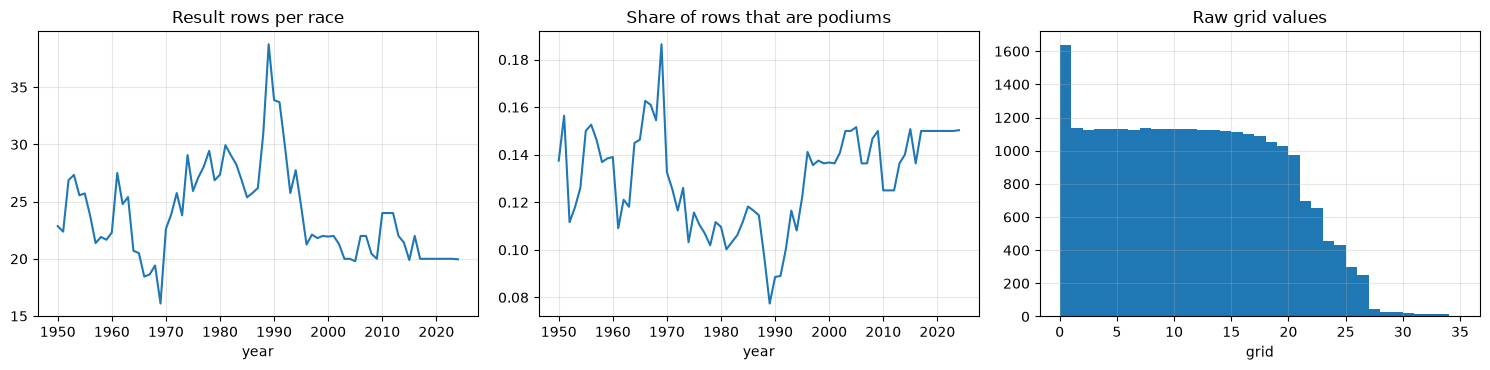

Overall podium share in the raw results: 0.127


In [9]:
raw_rows = pd.DataFrame({'raceId': results_raw['raceId'],
                         'year': results_raw['raceId'].map(race_year),
                         'podium': results_raw['positionOrder'].astype(int) <= 3,
                         'grid': results_raw['grid'].astype(int)})
per_season = raw_rows.groupby('year').agg(rows=('podium', 'size'), races=('raceId', 'nunique'), podium_share=('podium', 'mean'))
per_season['rows per race'] = per_season['rows'] / per_season['races']

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
per_season['rows per race'].plot(ax=axes[0], title='Result rows per race')
per_season['podium_share'].plot(ax=axes[1], title='Share of rows that are podiums')
axes[2].hist(raw_rows['grid'], bins=range(0, 36))
axes[2].set_title('Raw grid values')
axes[2].set_xlabel('grid')
plt.tight_layout()
save_fig('raw_target_grid')
plt.show()
print(f"Overall podium share in the raw results: {raw_rows['podium'].mean():.3f}")

- Fields were much larger before 1995 (up to ~39 entries per race), so the podium share per row was lower: three podium places shared by more entries.
- The podium share dips in the late 1970s–early 1990s, exactly when the number of rows per race peaks. Section 3.4 shows that these extra rows are entries that never started.
- `grid = 0` is a large spike (1,638 rows). It mixes drivers who never started with drivers who started from the pit lane.

**Findings of the raw audit**

| Problem | How it was detected | Decision | Section |
| --- | --- | --- | --- |
| `\N` and empty strings mark missing values | count per column (2.2) | read as missing; no other word is (checked in 2.2) | 3.1 |
| dates and durations stored as text, durations in three formats | column profile (2.1), format patterns (2.4) | one parser to seconds, dates to `datetime` | 3.1 |
| stray spaces and spelling variants (`Argentinian`, `United States`) | 2.2, value counts (2.3) | strip spaces; one canonical name, asserted | 3.1 |
| duplicate `(raceId, driverId)` rows | natural-key check | rule D, chosen from four rules | 3.3 |
| `grid = 0` mixes non-starters and pit-lane starts | grid histogram (2.5), `laps` | keep a row with a grid slot or a completed lap | 3.4 |
| entries that never started inflate the negative class | rows per race and podium share per season (2.5) | removed; checked with the model in 8.3 | 3.4 |
| implausible values in two post-race columns | column profile (2.1) | left as they are: never used | — |
| team identity splits by engine and by rename | shared Wikipedia links (2.1) | follow `constructorId`, documented | 17 |

## 3. Data cleaning

All cleaning happens on a second, typed copy of the tables (`clean`). The CSV files and the `raw` tables stay untouched.

### 3.1 Sentinels and semantic typing

- `\N` and empty strings become `NaN` while reading. `keep_default_na=False` makes sure nothing else is treated as missing; no value in the files is one of the words pandas would otherwise read as missing (`NA`, `None`, `null`, ..., counted in 2.2).
- Dates become `datetime`, durations become seconds (`float`).
- Text is stripped of extra spaces, and the spelling variants found in 2.3 get one canonical name.

In [10]:
SENTINELS = ['\\N', '']
DATES = {'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'], 'drivers': ['dob']}
DURATIONS = {'qualifying': ['q1', 'q2', 'q3'], 'lap_times': ['time'], 'pit_stops': ['duration'],
             'results': ['fastestLapTime'], 'sprint_results': ['fastestLapTime']}


def to_seconds(s):
    # '23.456' -> 23.456, '1:26.572' -> 86.572, '2:05:05.152' -> 7505.152
    parts = s.str.split(':')
    return parts.map(lambda p: sum(float(x) * 60 ** i for i, x in enumerate(reversed(p))), na_action='ignore')


clean = {t: pd.read_csv(DATA_DIR / f'{t}.csv', na_values=SENTINELS, keep_default_na=False) for t in TABLES}
for table, cols in DATES.items():
    for col in cols:
        clean[table][col] = pd.to_datetime(clean[table][col])
for table, cols in DURATIONS.items():
    for col in cols:
        clean[table][col] = to_seconds(clean[table][col])
for t in clean.values():
    for col in t.select_dtypes(include=['object', 'string']).columns:
        t[col] = t[col].str.strip()

# one name per category: the spelling variants found in 2.3
CANONICAL_NAMES = {('drivers', 'nationality'): {'Argentinian': 'Argentine'},
                   ('circuits', 'country'): {'United States': 'USA'}}
for (table, col), variants in CANONICAL_NAMES.items():
    clean[table][col] = clean[table][col].replace(variants)
    assert not clean[table][col].isin(list(variants)).any()

# checks
assert not any((t.astype(str) == '\\N').any().any() for t in clean.values())
laps = clean['lap_times']
print('Largest difference between parsed lap time and milliseconds column:',
      round((laps['time'] - laps['milliseconds'] / 1000).abs().max(), 6), 's')
pd.DataFrame({'raw dtype': raw['results'].dtypes.astype(str), 'clean dtype': clean['results'].dtypes.astype(str)}).T

Largest difference between parsed lap time and milliseconds column: 0.0 s


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
raw dtype,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
clean dtype,int64,int64,int64,int64,float64,int64,float64,str,int64,float64,int64,str,float64,float64,float64,float64,float64,int64


The parser is checked against the `milliseconds` column that `lap_times` already has: they agree to the millisecond on all 589,081 laps.

Not converted, on purpose: `results.time` and `sprint_results.time` hold the winner's total time but a gap (`+5.478`) for everyone else, are post-race, and `milliseconds` already has the numeric version. The clock times (`races.time`, the session times, `pit_stops.time`) are times of day, not durations, and nothing uses them.

**An impossible qualifying time.** After typing, one `q1` time is 1002.6 s (`16:42.640`) at the 1995 Japanese GP, where the fastest `q1` (here also the pole time) was about 98 s. No lap of Suzuka takes 16 minutes, so this is a data-entry error. We divide every `q1` time by the fastest `q1` of its race (the pole time before 2006; from 2006 pole is set in Q3). Only this one time is more than 50% slower than the fastest (the next worst is 45%, a driver with a problem in 2023), so we set times above 150% of the fastest to missing. Any cutoff between 1.45 and 10.2 times the fastest removes this one time and nothing else, so the exact value does not matter.

In [11]:
quali = clean['qualifying']
q1_vs_fastest = quali['q1'] / quali.groupby('raceId')['q1'].transform('min')
print(q1_vs_fastest.describe(percentiles=[0.5, 0.99, 0.999]).round(3).to_dict())
slowest = quali.assign(q1_vs_fastest=q1_vs_fastest.round(2)).nlargest(3, 'q1_vs_fastest')
display(slowest.merge(clean['races'][['raceId', 'year', 'name']], on='raceId')[['year', 'name', 'driverId', 'q1', 'q1_vs_fastest']])
too_slow = q1_vs_fastest > 1.5
quali.loc[too_slow, 'q1'] = np.nan

{'count': 10338.0, 'mean': 1.019, 'std': 0.093, 'min': 1.0, '50%': 1.013, '99%': 1.087, '99.9%': 1.194, 'max': 10.229}


,year,name,driverId,q1,q1_vs_fastest
0,1995,Japanese Grand Prix,87,1002.640,10.23
1,2023,Saudi Arabian Grand Prix,858,128.510,1.45
2,2004,San Marino Grand Prix,47,106.299,1.33


### 3.2 Keys, validity rules and reconciliation

A primary key must be unique and never missing. A foreign key must point to a row that exists in the parent table.

In [12]:
PRIMARY_KEYS = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'], 'races': ['raceId'],
    'results': ['resultId'], 'qualifying': ['qualifyId'], 'status': ['statusId'], 'seasons': ['year'],
    'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
    'constructor_results': ['constructorResultsId'], 'sprint_results': ['resultId'],
    'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop'],
}
FOREIGN_KEYS = [
    ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'), ('results', 'constructorId', 'constructors'),
    ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'), ('qualifying', 'constructorId', 'constructors'),
    ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
    ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
    ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
    ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
]


def check_primary_keys(tables, keys):
    rows = []
    for name, cols in keys.items():
        t = tables[name]
        rows.append({'table': name, 'key': ' + '.join(cols), 'rows': len(t),
                     'missing': t[cols].isna().any(axis=1).sum(), 'duplicated': t.duplicated(cols).sum()})
    return pd.DataFrame(rows)


def check_foreign_keys(tables, fks):
    rows = []
    for child, col, parent in fks:
        values = tables[child][col]
        orphans = values.notna() & ~values.isin(tables[parent][col])
        rows.append({'foreign key': f'{child}.{col} -> {parent}', 'missing': values.isna().sum(), 'orphans': orphans.sum()})
    return pd.DataFrame(rows)


pk_check = check_primary_keys(clean, PRIMARY_KEYS)
fk_check = check_foreign_keys(clean, FOREIGN_KEYS)
print('Primary-key problems:', pk_check[['missing', 'duplicated']].to_numpy().sum())
print('Foreign-key problems:', fk_check[['missing', 'orphans']].to_numpy().sum())
display(pk_check)
display(fk_check)

Primary-key problems: 0
Foreign-key problems: 0


,table,key,rows,missing,duplicated
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,results,resultId,26759,0,0
5,qualifying,qualifyId,10494,0,0
6,status,statusId,139,0,0
7,seasons,year,75,0,0
8,driver_standings,driverStandingsId,34863,0,0
9,constructor_standings,constructorStandingsId,13391,0,0


,foreign key,missing,orphans
0,races.circuitId -> circuits,0,0
1,races.year -> seasons,0,0
2,results.raceId -> races,0,0
3,results.driverId -> drivers,0,0
4,results.constructorId -> constructors,0,0
5,results.statusId -> status,0,0
6,qualifying.raceId -> races,0,0
7,qualifying.driverId -> drivers,0,0
8,qualifying.constructorId -> constructors,0,0
9,sprint_results.raceId -> races,0,0


Every primary key is unique and complete, and every foreign key reconciles. The surrogate keys are fine; the problem is the grain we need. Each table also has a *natural* key, the combination that should be unique by meaning:

In [13]:
natural_check = check_primary_keys(clean, {
    'results': KEY, 'qualifying': KEY, 'sprint_results': KEY, 'driver_standings': KEY,
    'constructor_standings': ['raceId', 'constructorId'], 'races': ['year', 'round'],
})
display(natural_check)

rounds = clean['races'].sort_values(['year', 'round']).groupby('year')['round']
assert (rounds.min() == 1).all() and (rounds.diff().dropna() == 1).all()
print('Rounds are numbered 1, 2, 3, ... without gaps in every season')


def driver_race_pairs(t):
    return set(zip(t['raceId'], t['driverId']))


result_pairs = driver_race_pairs(clean['results'])
for name in ['qualifying', 'sprint_results', 'driver_standings']:
    print(f'{name}: (raceId, driverId) pairs with no row in results = {len(driver_race_pairs(clean[name]) - result_pairs)}')

,table,key,rows,missing,duplicated
0,results,raceId + driverId,26759,0,91
1,qualifying,raceId + driverId,10494,0,0
2,sprint_results,raceId + driverId,360,0,0
3,driver_standings,raceId + driverId,34863,0,0
4,constructor_standings,raceId + constructorId,13391,0,0
5,races,year + round,1125,0,0


Rounds are numbered 1, 2, 3, ... without gaps in every season
qualifying: (raceId, driverId) pairs with no row in results = 0
sprint_results: (raceId, driverId) pairs with no row in results = 0
driver_standings: (raceId, driverId) pairs with no row in results = 8664


Round numbers have no gaps, so "the previous round" always exists after round 1 (used for the standings in 6.2). Only `results` breaks its natural key: 91 extra rows on `(raceId, driverId)`. Every qualifying and sprint row belongs to a driver who has a result in that race. `driver_standings` has 8,664 pairs with no result: the standings after a race list every driver of that season so far, including drivers who missed that race. This is how a cumulative table works, not an error; we always join it onto the driver-race rows with a left join, so it cannot add rows.

**Validity rules.** Keys only say that rows can be joined. These rules check that the values make sense, each counted on the typed tables:

In [14]:
res, quali, races_t = clean['results'], clean['qualifying'], clean['races']
race_date = races_t.set_index('raceId')['date']


def not_one_to_n(values):
    # True when the values are not exactly 1, 2, ..., n
    return not np.array_equal(np.sort(values.to_numpy()), np.arange(1, len(values) + 1))


age_on_race_day = (res['raceId'].map(race_date) - res['driverId'].map(clean['drivers'].set_index('driverId')['dob'])).dt.days / 365.25
quali_team = quali[KEY + ['constructorId']].merge(res[KEY + ['constructorId']], on=KEY, suffixes=('_quali', '_result'))
most_laps = res.groupby('raceId')['laps'].max()
winner_laps = res[res['positionOrder'] == 1].groupby('raceId')['laps'].max()
ds_sorted = clean['driver_standings'].merge(races_t[['raceId', 'year', 'round']], on='raceId').sort_values(['year', 'round'])
validity = pd.DataFrame([
    ('results', 'positionOrder is exactly 1..n in every race', 'races',
     res.groupby('raceId')['positionOrder'].agg(not_one_to_n).sum()),
    ('results', 'position equals positionOrder whenever position is filled', 'rows',
     (res['position'].notna() & (res['position'] != res['positionOrder'])).sum()),
    ('results', 'grid is between 0 and the number of entries in the race', 'rows',
     (~res['grid'].between(0, res.groupby('raceId')['grid'].transform('size'))).sum()),
    ('results', 'points and laps are not negative', 'rows', ((res['points'] < 0) | (res['laps'] < 0)).sum()),
    ('results', 'nobody completed more laps than the winner', 'races',
     (most_laps > winner_laps.reindex(most_laps.index)).sum()),
    ('qualifying', 'position is exactly 1..n in every race', 'races', quali.groupby('raceId')['position'].agg(not_one_to_n).sum()),
    ('qualifying', 'a q2 time only with a q1 time, a q3 time only with a q2 time', 'rows',
     ((quali['q2'].notna() & quali['q1'].isna()) | (quali['q3'].notna() & quali['q2'].isna())).sum()),
    ('qualifying', 'the driver qualified for the same constructor as in the result', 'rows',
     (quali_team['constructorId_quali'] != quali_team['constructorId_result']).sum()),
    ('races', 'the race date falls in the season', 'races', (races_t['date'].dt.year != races_t['year']).sum()),
    ('races', 'race dates increase with the round number', 'seasons',
     races_t.sort_values(['year', 'round']).groupby('year')['date'].agg(lambda d: (d.diff().dt.days <= 0).any()).sum()),
    ('drivers', 'age on race day between 16 and 60', 'rows', (~age_on_race_day.between(16, 60)).sum()),
    ('driver_standings', 'a driver never loses points during a season', 'driver-seasons',
     ds_sorted.groupby(['year', 'driverId'])['points'].agg(lambda p: (p.diff() < 0).any()).sum()),
    ('lap_times, pit_stops', 'lap times and stop durations are positive', 'rows',
     (clean['lap_times']['milliseconds'] <= 0).sum() + (clean['pit_stops']['milliseconds'] <= 0).sum()),
], columns=['table', 'rule', 'counted in', 'violations'])
validity

,table,rule,counted in,violations
0,results,positionOrder is exactly 1..n in every race,races,46
1,results,position equals positionOrder whenever positio...,rows,13
2,results,grid is between 0 and the number of entries in...,rows,13
3,results,points and laps are not negative,rows,0
4,results,nobody completed more laps than the winner,races,1
5,qualifying,position is exactly 1..n in every race,races,0
6,qualifying,"a q2 time only with a q1 time, a q3 time only ...",rows,0
7,qualifying,the driver qualified for the same constructor ...,rows,10
8,races,the race date falls in the season,races,0
9,races,race dates increase with the round number,seasons,0


Every violation was traced to its cause:

| Rule | Violations | Cause | Decision |
| --- | --- | --- | --- |
| `positionOrder` is 1..n | 46 races, all 1950–1964 | two rows share a position: a driver who drove two cars (the shared drives of 3.3), two drivers credited with one car's result (same car number and laps), or the Indianapolis 500 | grain fixed in 3.3, Indianapolis 500 dropped in 3.4. In 18 races more than three drivers hold a position ≤ 3, which is why the cleaned 1950s podium share sits above `3 / starters` (4.1) |
| `position` equals `positionOrder` | 13 rows, all the 1983 Brazilian GP | the second-placed car was disqualified and the place left vacant: `position` keeps 3, 4, ... while `positionOrder` ranks 2, 3, ... | the target follows the brief (`positionOrder <= 3`); this labels one row a podium although that driver was officially 4th |
| grid ≤ entries | 13 rows | grid slots of cars that are not in the results table (Formula 2 cars started in the 1969 German GP) | kept: the value is still the real starting slot |
| nobody beats the winner's laps | 1 race, 1960 Dutch GP | one row says 78 laps with status `+5 Laps` while the winner did 75: an entry error | kept: `laps` only decides whether a lap was completed (3.4) |
| same constructor in qualifying and results | 10 rows, late 2015 | qualifying still uses Marussia's old id, results already use Manor Marussia's | kept: features take the constructor from `results` |

Every other rule holds for every row.

**Reconciliation of points.** The standings are a second source for the same facts: summing a driver's points from `results` and `sprint_results` up to a round should give the points in `driver_standings` after that round. Because our standings features come from this table, we check how far the two agree, per decade:

In [15]:
race_points = res.groupby(KEY)['points'].sum().add(clean['sprint_results'].groupby(KEY)['points'].sum(), fill_value=0)
summed = (race_points.rename('summed').reset_index().merge(races_t[['raceId', 'year', 'round']], on='raceId')
          .sort_values(['year', 'round']))
summed['summed'] = summed.groupby(['year', 'driverId'])['summed'].cumsum()
standings_points = ds_sorted[['year', 'round', 'driverId', 'points']].sort_values('round')
reconciled = pd.merge_asof(standings_points, summed[['year', 'round', 'driverId', 'summed']].sort_values('round'),
                           on='round', by=['year', 'driverId'])
reconciled['agrees'] = (reconciled['points'] - reconciled['summed'].fillna(0)).abs() < 0.01
reconciled['sum higher'] = reconciled['summed'].fillna(0) > reconciled['points'] + 0.01
reconciled.groupby(reconciled['year'] // 10 * 10)[['agrees', 'sum higher']].mean().round(3).rename_axis('decade')

,agrees,sum higher
decade,,
1950,0.993,0.007
1960,0.993,0.007
1970,0.993,0.007
1980,0.996,0.004
1990,1.000,0.000
2000,1.000,0.000
2010,1.000,0.000
2020,1.000,0.000


The standings agree with the summed points for 99.3% or more of the rows in every decade, and for all of them since 1990. Where they differ (0.4–0.7% of rows, all before 1990), the summed points are always higher: until 1990 only a driver's best results counted towards the championship (dropped scores), so the official standings are below the plain sum. The standings table is therefore the official championship and consistent with the results, which is why the standings features use its positions rather than points we would sum ourselves (8.3 also shows positions work better than raw points).

### 3.3 Duplicate driver–race rows (shared drives)

In [16]:
race_info = clean['races'][['raceId', 'year', 'round', 'date', 'name', 'circuitId']]
results = (clean['results']
           .merge(race_info, on='raceId', how='left', validate='m:1')
           .merge(clean['status'], on='statusId', how='left', validate='m:1')
           .merge(clean['drivers'][['driverId', 'surname']], on='driverId', how='left', validate='m:1'))

dups = results[results.duplicated(KEY, keep=False)].sort_values(KEY + ['resultId'])
print(f'Rows in duplicated pairs: {len(dups)} | pairs: {dups.groupby(KEY).ngroups} | extra rows: {results.duplicated(KEY).sum()}')
print('Pairs per season:', dups.drop_duplicates(KEY)['year'].value_counts().sort_index().to_dict())

cols = ['year', 'name', 'surname', 'resultId', 'number', 'grid', 'positionOrder', 'laps', 'status']
british_gp_1957 = (dups['year'] == 1957) & (dups['name'] == 'British Grand Prix') & dups['surname'].isin(['Moss', 'Brooks'])
dups.loc[british_gp_1957, cols]

Rows in duplicated pairs: 176 | pairs: 85 | extra rows: 91
Pairs per season: {1950: 4, 1951: 4, 1952: 3, 1953: 14, 1954: 16, 1955: 15, 1956: 12, 1957: 8, 1958: 3, 1960: 1, 1961: 2, 1962: 1, 1964: 1, 1978: 1}


,year,name,surname,resultId,number,grid,positionOrder,laps,status
18816,1957,British Grand Prix,Moss,18817,18.0,1,12,51,Engine
20288,1957,British Grand Prix,Moss,20291,20.0,3,1,90,Finished
18805,1957,British Grand Prix,Brooks,18806,20.0,3,1,90,Finished
20290,1957,British Grand Prix,Brooks,20293,18.0,1,12,51,Engine


All 85 pairs are from 1950–1978, almost all before 1965. They are shared drives: a driver took over a teammate's car during the race, so the driver has one row per car. The 1957 British GP above is the typical case: Moss started car #18 from pole and retired, then took over Brooks's car #20 and won. Brooks started #20 and later drove Moss's car #18. Both are officially credited with the win.

There is no column that says which car a driver started in. Two facts identify it:

1. A driver only takes over a car that someone else started, so a car that nobody else drove in that race is the driver's own car.
2. When every car the driver drove was shared, the first listed row (lowest `resultId`) is the own car: the extra shared-drive rows were appended to the table later.

We check the result: every row we do *not* keep should be a car that another driver started.

In [17]:
ordered = results.sort_values('resultId')
ordered['shared_car'] = ordered.groupby(['raceId', 'number'])['driverId'].transform('nunique') > 1
own_car = ordered.sort_values(['shared_car', 'resultId']).drop_duplicates(KEY)    # fact 1, then fact 2
other_cars = ordered.drop(own_car.index)

# check: each dropped row should be a car that another driver started
car_starters = own_car.groupby(['raceId', 'number'])['driverId'].agg(set)
started_by_other = other_cars.apply(
    lambda r: len(car_starters.get((r['raceId'], r['number']), set()) - {r['driverId']}) > 0, axis=1)
print(f'Rows not kept whose car another driver started in the same race: {started_by_other.sum()} of {len(other_cars)}')

own_ids = own_car.set_index(KEY)['resultId']
first_listed = ordered.drop_duplicates(KEY).set_index(KEY)['resultId'].reindex(own_ids.index)
fact_1_pairs = own_ids[own_ids != first_listed].index
print('Pairs where fact 1 keeps a different row than the first listed:', len(fact_1_pairs))
in_fact_1_pair = results.set_index(KEY).index.isin(fact_1_pairs)
display(results.loc[in_fact_1_pair].sort_values(KEY + ['resultId'])[cols])
other_cars.loc[~started_by_other, cols]

Rows not kept whose car another driver started in the same race: 88 of 91
Pairs where fact 1 keeps a different row than the first listed: 4


,year,name,surname,resultId,number,grid,positionOrder,laps,status
17740,1962,British Grand Prix,Greene,17741,48.0,0,22,0,Withdrew
17743,1962,British Grand Prix,Greene,17744,50.0,0,25,0,Withdrew
17961,1961,British Grand Prix,Moss,17962,26.0,20,19,56,Disqualified
17963,1961,British Grand Prix,Moss,17964,28.0,5,21,44,Brakes
19267,1954,Belgian Grand Prix,González,19268,10.0,5,4,35,+1 Lap
19275,1954,Belgian Grand Prix,González,19276,6.0,2,12,1,Engine
19918,1951,French Grand Prix,Ascari,19919,14.0,6,2,77,Finished
19934,1951,French Grand Prix,Ascari,19935,12.0,3,18,10,Gearbox


,year,name,surname,resultId,number,grid,positionOrder,laps,status
13191,1978,Italian Grand Prix,Ertl,13192,23.0,0,29,0,Did not prequalify
18519,1958,Monaco Grand Prix,Flockhart,18520,10.0,0,27,0,Did not qualify
18973,1956,French Grand Prix,da Silva Ramos,18974,8.0,16,13,40,Engine


88 of the 91 rows we do not keep are cars that another driver started in the same race. The 3 exceptions are two drivers who entered two cars and started neither (removed in 3.4) and da Silva Ramos at the 1956 French GP, who appears in two cars that nobody else drove; there we keep the first listed.

Fact 1 changes the choice in 4 pairs. In three of them (Ascari 1951, González 1954, Moss 1961) the other driver's row was appended later, so the first listed row is the car taken over; the fourth is a driver who withdrew both cars. Example: González at the 1954 Belgian GP started car #6 from grid 2, retired on lap 1 and then took over Hawthorn's car #10.

**Which row to keep?** We compared four rules on the 85 pairs:

In [18]:
dups = dups.assign(any_podium=dups.groupby(KEY)['positionOrder'].transform('min') <= 3,
                   own=dups.index.isin(own_car.index))
rules = {
    'A: own car': dups.sort_values('own', ascending=False),
    'B: best positionOrder': dups.sort_values(['positionOrder', 'resultId']),
    'C: most laps': dups.sort_values(['laps', 'resultId'], ascending=[False, True]),
}
compare_rules = []
for rule, rows in rules.items():
    kept_rows = rows.drop_duplicates(KEY).set_index(KEY)
    compare_rules.append({'rule': rule,
                          'podium labels': (kept_rows['positionOrder'] <= 3).sum(),
                          'credited podiums lost': (kept_rows['any_podium'] & (kept_rows['positionOrder'] > 3)).sum(),
                          'grid not from the own car': (kept_rows['resultId'] != own_ids.loc[kept_rows.index]).sum()})
compare_rules.append({'rule': 'D: own car, label = podium in any car',
                      'podium labels': dups.groupby(KEY)['any_podium'].first().sum(), 'credited podiums lost': 0,
                      'grid not from the own car': 0})
pd.DataFrame(compare_rules).set_index('rule')

,podium labels,credited podiums lost,grid not from the own car
rule,,,
A: own car,5,17,0
B: best positionOrder,22,0,68
C: most laps,22,0,68
"D: own car, label = podium in any car",22,0,0


- **A** keeps the right pre-race information (the car and grid slot the driver started with) but loses 17 podiums the driver is officially credited with.
- **B** and **C** keep the credited podiums but, in 68 of the 85 pairs, keep the grid slot of a car the driver did not start in. They also pick the row by looking at the race outcome.
- **D** keeps the row of the driver's own car, and labels it a podium if the driver finished on the podium in any car.

**Decision: rule D.** The features describe what was known before the start, and the label matches the official classification. In practice we keep the own-car row and replace its `positionOrder` with the driver's best `positionOrder` in that race. The choice only affects 1950–1978 races, and changes the label of 17 rows compared with rule A.

Who drove which car is only recorded after the race. We use it once, to recover a fact that was known before the start (the driver's own car and grid slot), and never as a feature; the same reasoning applies to `laps` in 3.4.

In [19]:
best_in_any_car = results.groupby(KEY)['positionOrder'].transform('min')
entries = own_car.drop(columns='shared_car')
entries['positionOrder'] = best_in_any_car.loc[entries.index]
entries['podium'] = (entries['positionOrder'] <= 3).astype(int)
assert not entries.duplicated(KEY).any()
print(f'results rows: {len(results):,} -> driver-race rows: {len(entries):,}')

results rows: 26,759 -> driver-race rows: 26,668


### 3.4 Which rows belong in the modeling table

**Entries that never started.** `grid = 0` has two meanings, which we separate with `laps`:

In [20]:
has_grid_slot = entries['grid'] > 0
completed_lap = entries['laps'] > 0
grid0 = entries[~has_grid_slot]
code = grid0['positionText'].where(~grid0['positionText'].str.isdigit(), 'number')
print(pd.crosstab(code, grid0['laps'] > 0, colnames=['completed a lap'], rownames=['positionText']))
print('Podiums among grid = 0 rows:', grid0['podium'].sum())
pit_lane_starts = entries[~has_grid_slot & completed_lap]
print(f"grid = 0 with laps > 0: {len(pit_lane_starts)} rows, seasons {pit_lane_starts['year'].min()}-{pit_lane_starts['year'].max()}")
took_part_in_quali = entries.set_index(KEY).index.isin(clean['qualifying'].set_index(KEY).index)
print('grid = 0 and no lap, but a qualifying result, by positionText:',
      entries.loc[~has_grid_slot & ~completed_lap & took_part_in_quali, 'positionText'].value_counts().to_dict())

completed a lap  False  True 
positionText                 
D                    6      0
E                    7      0
F                 1346      0
R                    2     12
W                  202      0
number               0     60
Podiums among grid = 0 rows: 0
grid = 0 with laps > 0: 72 rows, seasons 2015-2024
grid = 0 and no lap, but a qualifying result, by positionText: {'W': 9, 'F': 6, 'R': 1}


- `grid = 0` and no lap completed (1,563 rows): mostly `F` (failed to qualify) and `W` (withdrawn), plus a few `E`, `D`, `R`. These drivers never took the start, and none of them has a podium.
- `grid = 0` and at least one lap (72 rows, 2015–2024): pit-lane starts. They raced; most finished.
- 16 of the non-starters have a qualifying result: 6 `F` that set a time but missed the 107% cutoff, and 10 that qualified and then did not start (withdrawal, injury, or a failure before the start).

Candidate rules for the population:

In [21]:
candidates = {
    'keep everything': pd.Series(True, index=entries.index),
    'drop positionText F': entries['positionText'] != 'F',
    'drop positionText F or W': ~entries['positionText'].isin(['F', 'W']),
    'drop grid = 0': has_grid_slot,
    'drop grid = 0 and laps = 0': has_grid_slot | completed_lap,
}
population_rules = []
for rule, keep in candidates.items():
    population_rules.append({'rule': rule, 'rows dropped': (~keep).sum(), 'podiums dropped': entries.loc[~keep, 'podium'].sum(),
                             'pit-lane starters dropped': (~has_grid_slot & completed_lap & ~keep).sum(),
                             'drivers with a grid slot dropped': (has_grid_slot & ~keep).sum(),
                             'non-starters kept': (~has_grid_slot & ~completed_lap & keep).sum()})
pd.DataFrame(population_rules).set_index('rule')

,rows dropped,podiums dropped,pit-lane starters dropped,drivers with a grid slot dropped,non-starters kept
rule,,,,,
keep everything,0,0,0,0,1563
drop positionText F,1366,0,0,20,217
drop positionText F or W,1701,0,0,153,15
drop grid = 0,1635,0,72,0,0
drop grid = 0 and laps = 0,1563,0,0,0,0


**Decision: keep a row if the driver had a grid slot or completed at least one lap.** It removes all 1,563 non-starters and no pit-lane starter. Dropping by letter code would keep 15 drivers who never started and drop 153 who had a grid slot; dropping every `grid = 0` would lose the 72 pit-lane starts, all in recent seasons.

Why drop non-starters at all: a driver who does not take the start has no race to predict, and none of them has a podium. Whether a driver starts is known before the lights go out, which is the cutoff (the F1 introduction: everything up to the starting grid, pit-lane starts included, may be used). Section 4.1 shows these rows caused the dip in the podium share before 1995. Of the status letters only `F` (failed to qualify) is decided before the race, so we do not filter on letters: the rule uses the grid slot and `laps`. Section 8.3 checks it with the model against removing only `F` and removing nothing.

`laps` is a post-race column, but it is only used to recover a fact that is known before the race (whether the driver is on the starting list). It never becomes a feature.

**The Indianapolis 500 (1950–1960).** It counted for the championship, but it was a separate event with its own drivers:

In [22]:
is_indy = entries['name'] == 'Indianapolis 500'
indy_drivers = set(entries.loc[is_indy, 'driverId'])
other_drivers = set(entries.loc[~is_indy, 'driverId'])
only_indy = indy_drivers - other_drivers
nationality = clean['drivers'].set_index('driverId')['nationality']
print(f"Indianapolis 500: {is_indy.sum()} rows in {entries.loc[is_indy, 'raceId'].nunique()} races")
print(f'Drivers who raced it: {len(indy_drivers)}, of whom never raced another championship race: '
      f'{len(only_indy)} ({len(only_indy) / len(indy_drivers):.0%})')
print(f"Share of American drivers: {(entries.loc[is_indy, 'driverId'].map(nationality) == 'American').mean():.0%}")

Indianapolis 500: 381 rows in 11 races
Drivers who raced it: 107, of whom never raced another championship race: 103 (96%)
Share of American drivers: 100%


**Decision: drop the Indianapolis 500.** Almost all of its drivers never raced anywhere else, so it is a separate population inside the data, and it would add about 380 American "home" starts to question 2 (question 2 shows the answer with and without it). It is identified by race name, because the same circuit later hosted the United States GP (2000–2007).

### 3.5 Cleaning summary

In [23]:
started = has_grid_slot | completed_lap
starters = entries[started & ~is_indy].sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)

summary = pd.DataFrame([
    {'step': 'raw results', 'rows': len(results), 'podium rows': (results['positionOrder'] <= 3).sum()},
    {'step': 'one row per (raceId, driverId)', 'rows': len(entries), 'podium rows': entries['podium'].sum()},
    {'step': 'drop non-starters', 'rows': started.sum(), 'podium rows': entries.loc[started, 'podium'].sum()},
    {'step': 'drop Indianapolis 500', 'rows': len(starters), 'podium rows': starters['podium'].sum()},
]).set_index('step')
summary['podium share'] = (summary['podium rows'] / summary['rows']).round(3)
summary

,rows,podium rows,podium share
step,,,
raw results,26759,3397,0.127
"one row per (raceId, driverId)",26668,3395,0.127
drop non-starters,25105,3395,0.135
drop Indianapolis 500,24724,3359,0.136


### 3.6 Missing values: where they are and what we do

Every column with missing values (counted in 2.2), why it is missing, the seasons affected, and what we do with it. *Not used* means the column never enters the analysis, so its missing values are simply left as they are. No row and no column is dropped *because* of a missing value: the rows removed in 3.3–3.4 are duplicates, non-starters and the Indianapolis 500, and section 9.1 shows that dropping incomplete rows would be worse.

In [24]:
MISSING_TREATMENT = [
    # (columns, why they are missing, what we do)
    (['results.position'], 'driver not classified (positionText holds a letter instead)',
     'left as is: the target uses positionOrder, complete for every row'),
    (['results.time', 'results.milliseconds'], 'a race time exists only for classified finishers', 'not used (post-race)'),
    (['results.fastestLap', 'results.rank', 'results.fastestLapTime', 'results.fastestLapSpeed'],
     'fastest laps recorded from 2004 on, and only for drivers who set a timed lap', 'not used (post-race)'),
    (['results.number'], 'car number not recorded', 'left as is: only used to find shared cars (3.3); none of these rows is in a duplicated pair'),
    (['qualifying.q1'], 'no time set in qualifying, plus the impossible time removed in 3.1',
     'used for q1_gap_pct; missing values imputed with the training median plus an indicator (9.1)'),
    (['qualifying.q2', 'qualifying.q3'], 'driver knocked out earlier, or a single-session format (before 2006)',
     'only in the candidate best_gap_pct (fastest of q1/q2/q3, not selected in 8.3); the minimum skips a missing session'),
    (['races.time'], 'race start time recorded from 2005 on', 'not used'),
    (['races.fp1_date', 'races.fp1_time', 'races.fp2_date', 'races.fp2_time', 'races.fp3_date', 'races.fp3_time',
      'races.quali_date', 'races.quali_time'], 'session schedule recorded only for recent seasons (no FP3 on sprint weekends)', 'not used'),
    (['races.sprint_date', 'races.sprint_time'], 'only sprint weekends (2021 on) have a sprint', 'not used'),
    (['drivers.number', 'drivers.code'], 'permanent numbers (2014 on) and three-letter codes exist only for recent drivers', 'not used'),
    (['constructor_results.status'], 'filled only for the rare disqualification', 'not used'),
    (['sprint_results.position', 'sprint_results.time', 'sprint_results.milliseconds', 'sprint_results.fastestLap',
      'sprint_results.fastestLapTime'], 'same as in results, for the sprint', 'not used: the sprint is not a feature (6.4)'),
]
treatment = pd.DataFrame([{'column': c, 'why missing': why, 'what we do': what} for cols, why, what in MISSING_TREATMENT for c in cols])
missing_map = (sentinels.assign(column=sentinels['table'] + '.' + sentinels['column'])
               [['column', 'share missing', 'seasons with missing values']]
               .merge(treatment, on='column', how='outer', validate='1:1', indicator=True))
assert (missing_map['_merge'] == 'both').all(), 'a column with missing values has no treatment, or a treatment names a column without any'
in_shared_drive = results.loc[results['number'].isna(), KEY].merge(dups[KEY], on=KEY).shape[0]
print('Rows without a car number that are part of a duplicated pair:', in_shared_drive)
missing_map.drop(columns='_merge').set_index('column')

Rows without a car number that are part of a duplicated pair: 0


,share missing,seasons with missing values,why missing,what we do
column,,,,
constructor_results.status,0.999,1958-2024,filled only for the rare disqualification,not used
drivers.code,0.879,-,permanent numbers (2014 on) and three-letter c...,not used
drivers.number,0.931,-,permanent numbers (2014 on) and three-letter c...,not used
qualifying.q1,0.015,1994-2024,"no time set in qualifying, plus the impossible...",used for q1_gap_pct; missing values imputed wi...
qualifying.q2,0.443,1994-2024,"driver knocked out earlier, or a single-sessio...",only in the candidate best_gap_pct (fastest of...
qualifying.q3,0.654,1994-2024,"driver knocked out earlier, or a single-sessio...",only in the candidate best_gap_pct (fastest of...
races.fp1_date,0.920,1950-2020,session schedule recorded only for recent seas...,not used
races.fp1_time,0.940,1950-2021,session schedule recorded only for recent seas...,not used
races.fp2_date,0.920,1950-2020,session schedule recorded only for recent seas...,not used


Missing values that are not empty cells but **missing rows**: a table simply has no row for some drivers or seasons. These matter more, because four of them leave selected features missing:

| What has no row | Seasons | Effect | What we do |
| --- | --- | --- | --- |
| qualifying result | none before 1994; 94% of starters in 1994, all in 1995, 6–59% in 1996–2002, all from 2003 (4.3) | `quali_pos`, `q1_gap_pct` missing for 63% of training rows | imputed (training median) plus a missing indicator, 9.1; restricting training to seasons with qualifying data was tested and is worse, 8.3 |
| constructor standings | none before 1958 (the Constructors' Championship began in 1958) | `con_standing` missing for every 1950–1957 row | same imputation, 9.1 |
| standings after the previous round | round 1 of every season; a driver's or team's first race of a season | `drv_standing`, `con_standing` missing there | same imputation, 9.1 |
| earlier starts of the driver | a driver's first start | form features missing | same imputation, 9.1 |
| lap times, pit stops, sprint results | before 1996, 2011 and 2021 | none: recorded during the race or not a feature | not used |

## 4. EDA after cleaning

`starters` is the cleaned driver–race table: one row per `(raceId, driverId)`, only drivers who started, no Indianapolis 500.

### 4.1 What the cleaning changed

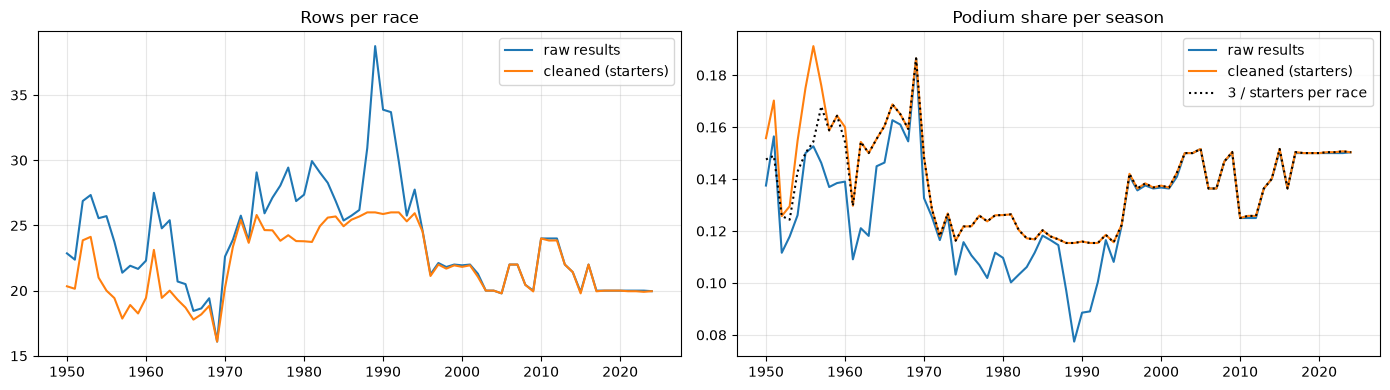

Most rows per race before / after cleaning: 38.8 / 26.0


In [25]:
raw_season = results.groupby('year').agg(rows=('raceId', 'size'), races=('raceId', 'nunique'),
                                         podium_share=('positionOrder', lambda s: (s <= 3).mean()))
clean_season = starters.groupby('year').agg(rows=('raceId', 'size'), races=('raceId', 'nunique'), podium_share=('podium', 'mean'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(raw_season.index, raw_season['rows'] / raw_season['races'], label='raw results')
axes[0].plot(clean_season.index, clean_season['rows'] / clean_season['races'], label='cleaned (starters)')
axes[0].set_title('Rows per race')
axes[0].legend()
axes[1].plot(raw_season.index, raw_season['podium_share'], label='raw results')
axes[1].plot(clean_season.index, clean_season['podium_share'], label='cleaned (starters)')
axes[1].plot(clean_season.index, 3 / (clean_season['rows'] / clean_season['races']), ls=':', c='k', label='3 / starters per race')
axes[1].set_title('Podium share per season')
axes[1].legend()
plt.tight_layout()
save_fig('cleaning_effect')
plt.show()
print('Most rows per race before / after cleaning:',
      round((raw_season['rows'] / raw_season['races']).max(), 1), '/', round((clean_season['rows'] / clean_season['races']).max(), 1))

Before cleaning, the late-1970s to early-1990s seasons had up to 38.8 rows per race; after cleaning the maximum is 26 cars, the size of a starting grid. The dip in the podium share came from the entries that never started: after cleaning, the podium share follows `3 / starters per race` in every season. In the 1950s it sits slightly above the line because a podium in a shared car credits more than one driver (rule D, 3.3). The remaining change over time is real: grids are smaller today, so a podium is a larger share of the field (about 15% now). This is why the podium rate is reported per split (section 7).

### 4.2 Starting position and podium

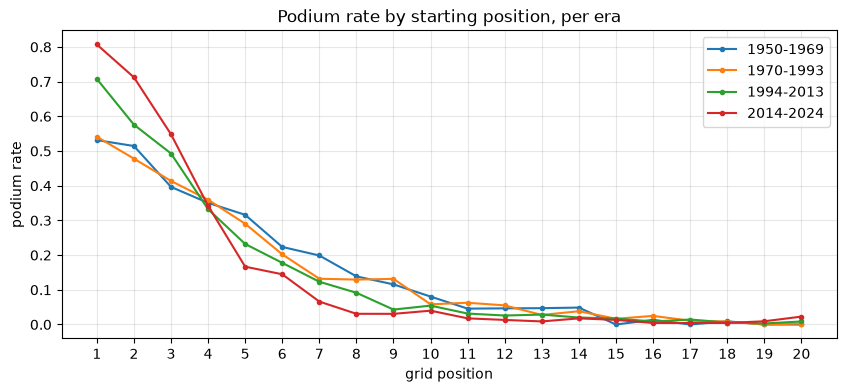

{'1950-1969': 0.53, '1970-1993': 0.54, '1994-2013': 0.71, '2014-2024': 0.81}


In [26]:
ERAS = {'1950-1969': (1950, 1969), '1970-1993': (1970, 1993), '1994-2013': (1994, 2013), '2014-2024': (2014, 2024)}
on_grid = starters[starters['grid'].between(1, 20)]
plt.figure(figsize=(10, 4))
for era, (lo, hi) in ERAS.items():
    rate = on_grid[on_grid['year'].between(lo, hi)].groupby('grid')['podium'].mean()
    plt.plot(rate.index, rate.to_numpy(), marker='o', ms=3, label=era)
plt.xticks(range(1, 21))
plt.xlabel('grid position')
plt.ylabel('podium rate')
plt.title('Podium rate by starting position, per era')
plt.legend()
save_fig('podium_by_grid')
plt.show()
pole = starters[starters['grid'] == 1]
print(pole.groupby(pd.cut(pole['year'], [1949, 1969, 1993, 2013, 2024], labels=list(ERAS)), observed=True)['podium']
      .mean().round(2).rename('podium rate from pole').to_dict())

The four periods above are broad, for a readable plot. The same measures per technical era, as the F1 introduction defines them (2009–2013 split at 2011, when DRS was introduced):

In [27]:
TECH_ERAS = {'1950-1957': (1950, 1957), '1958-1965': (1958, 1965), '1966-1976': (1966, 1976), '1977-1988': (1977, 1988),
             '1989-1994': (1989, 1994), '1995-2008': (1995, 2008), '2009-2010': (2009, 2010), '2011-2013 (DRS)': (2011, 2013),
             '2014-2021': (2014, 2021), '2022-2024': (2022, 2024)}
grid_back = starters['grid'].where(starters['grid'] > 0, 99)    # pit-lane starts at the back
era_rows = []
for era, (lo, hi) in TECH_ERAS.items():
    in_era = starters['year'].between(lo, hi)
    podium = starters.loc[in_era, 'podium']
    era_rows.append({'era': era, 'races': starters.loc[in_era, 'raceId'].nunique(),
                     'grid ROC-AUC': roc_auc_score(podium, -grid_back[in_era]),
                     'pole -> podium': podium[grid_back[in_era] == 1].mean(),
                     'podiums from grid 1-3': (grid_back[in_era][podium == 1] <= 3).mean()})
pd.DataFrame(era_rows).set_index('era').round(3)

,races,grid ROC-AUC,pole -> podium,podiums from grid 1-3
era,,,,
1950-1957,56,0.875,0.596,0.538
1958-1965,74,0.841,0.560,0.462
1966-1976,139,0.849,0.511,0.439
1977-1988,188,0.859,0.479,0.443
1989-1994,96,0.915,0.656,0.569
1995-2008,239,0.893,0.686,0.593
2009-2010,36,0.925,0.722,0.639
2011-2013 (DRS),58,0.902,0.810,0.575
2014-2021,160,0.923,0.812,0.704


The grid is the strongest single signal in every era: the podium rate falls steeply over the first positions and is close to zero after 10. The curve has become steeper: pole converted to a podium 53% of the time in 1950–69 and 81% since 2014, while positions 5–9 convert less often today than in the past. Cars became more reliable (4.4) and the gaps between teams more stable, so modern races follow the grid more closely. The era table shows the trend is not smooth: the introduction notes that DRS (2011) made the grid slightly less decisive, and compared with 2009–2010, 2011–2013 shows a lower grid ROC-AUC (0.902 vs 0.925) and fewer podiums from the first three grid slots (58% vs 64%), although pole converted more often (81% vs 72%; with 36 and 58 races these are differences of a few races). The hybrid era then made the grid more decisive again (0.923, 70%). A model trained on all seasons has to cope with this drift, which is one reason the split is by time (section 7).

### 4.3 Qualifying coverage and grid vs qualifying

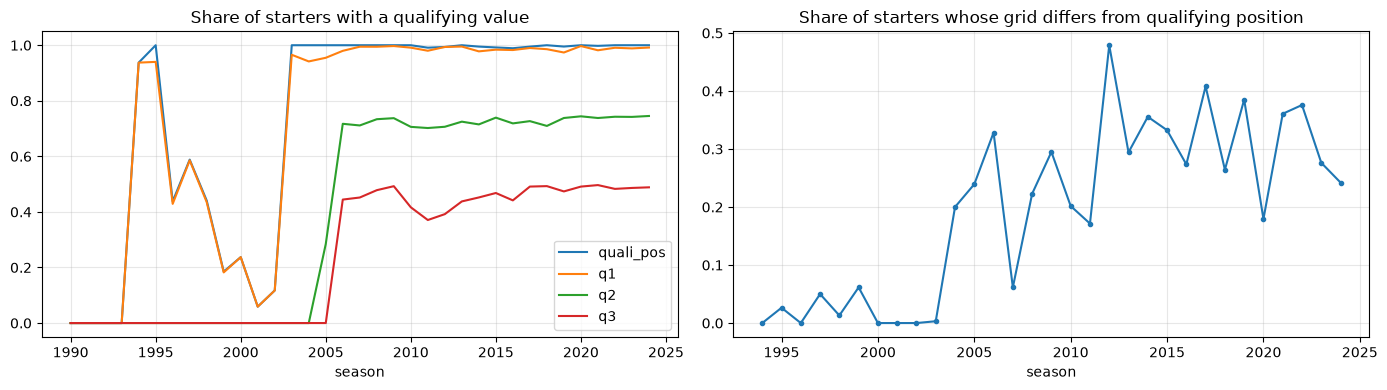

Qualifying-row coverage 1994-2005: {1994: 0.94, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0}
Grid differs from qualifying position, 2008-2024: 17% to 48% of starters


In [28]:
quali_cols = clean['qualifying'][KEY + ['position', 'q1', 'q2', 'q3']].rename(columns={'position': 'quali_pos'})
with_quali = starters.merge(quali_cols, on=KEY, how='left', validate='1:1')
coverage = with_quali.groupby('year')[['quali_pos', 'q1', 'q2', 'q3']].agg(lambda s: s.notna().mean())
both = with_quali.dropna(subset=['quali_pos'])
grid_differs = (both['grid'] != both['quali_pos']).groupby(both['year']).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
coverage.loc[1990:].plot(ax=axes[0], title='Share of starters with a qualifying value')
axes[0].set_xlabel('season')
grid_differs.plot(ax=axes[1], marker='o', ms=3, title='Share of starters whose grid differs from qualifying position')
axes[1].set_xlabel('season')
plt.tight_layout()
save_fig('qualifying_coverage')
plt.show()
print('Qualifying-row coverage 1994-2005:', coverage.loc[1994:2005, 'quali_pos'].round(2).to_dict())
print(f'Grid differs from qualifying position, 2008-2024: {grid_differs.loc[2008:].min():.0%} to {grid_differs.loc[2008:].max():.0%} of starters')

- **Coverage is not a single step.** There is no qualifying data before 1994. 94% of starters have a row in 1994, all of them in 1995 and from 2003 on, but only 6–59% in 1996–2002. Qualifying features will be missing for every row before 1994 and for most of 1996–2002 (handled in 8.3 and 9.1).
- `q2`/`q3` only exist from 2006 (knockout format). Before that the single session is stored in `q1`. Even after 2006, `q2`/`q3` are missing for drivers knocked out early, so the only time every driver has is `q1`.
- **Grid ≠ qualifying** for 17–48% of starters each season since 2008: penalties, and the places other drivers gain when someone ahead is moved back. The two are different features (question 1 and section 6).

### 4.4 Reliability over time

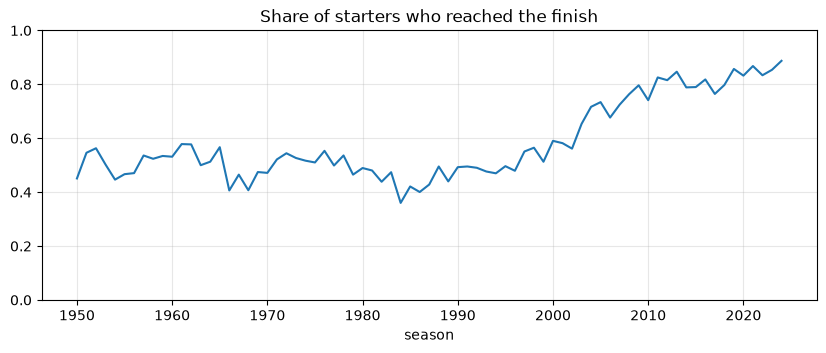

{1950: 0.5, 1960: 0.5, 1970: 0.51, 1980: 0.44, 1990: 0.5, 2000: 0.68, 2010: 0.8, 2020: 0.86}


In [29]:
FINISHED = r'^(Finished|\+\d+ Laps?)$'    # 'Finished', or classified one or more laps down
finish_rate = starters['status'].str.match(FINISHED).groupby(starters['year']).mean()
plt.figure(figsize=(10, 3.5))
plt.plot(finish_rate.index, finish_rate.to_numpy())
plt.title('Share of starters who reached the finish')
plt.xlabel('season')
plt.ylim(0, 1)
save_fig('finish_rate')
plt.show()
print(finish_rate.groupby(finish_rate.index // 10 * 10).mean().round(2).to_dict())

From the 1950s to the 1990s only about half of the starters reached the finish; in the 2010s it was 80% and in the 2020s 86%. This is why a good grid slot converted to a podium less often in the early decades (4.2). Retirement causes are grouped in question 3.

## 5. Data-engineering questions

All three answers use the cleaned `starters` table: one row per driver per race, starters only, no Indianapolis 500.

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Joins.** `results → races → circuits` for the circuit, plus `qualifying` for the qualifying position.
**Grain.** One row = one driver starting from the front row at one race.
**Definitions.** The question is about where the car starts, so the answer uses the grid: a *front-row start* is `grid` 1 or 2 (after penalties). To keep the two apart, we also show the *front-row qualifier* (qualifying `position` 1 or 2, only from 1994), how often the two differ and what that changes. Periods: 1950–2013 and 2014–2024. We read "after the 2014 hybrid era" as "from 2014 on", when the hybrid era began. 2022–2024 cannot be a third period: no circuit hosted more than 3 races in it (6 front-row starts, below the minimum of 10 used below). As a check, the hybrid era alone (2014–2021) is also compared.
**Missingness.** `grid` is complete for all starters. The qualifying view only uses seasons with qualifying data, so it is shown separately.
**Cutoff.** Grid and qualifying are both known before the race; the podium is the outcome being described.

In [30]:
circuit_info = clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})
q1_rows = with_quali.merge(circuit_info, on='circuitId', how='left', validate='m:1')
q1_rows['period'] = np.where(q1_rows['year'] >= 2014, '2014-2024', '1950-2013')
front_row = q1_rows[q1_rows['grid'].isin([1, 2])]
MIN_FRONT_ROW = 10


def front_row_conversion(rows, min_starts=MIN_FRONT_ROW):
    # podiums per front-row start and number of starts: one row per circuit, one column per period;
    # cells with fewer than min_starts starts are left empty
    t = rows.groupby(['circuit', 'period']).agg(starts=('podium', 'size'), podiums=('podium', 'sum'))
    t = t[t['starts'] >= min_starts]
    return (t['podiums'] / t['starts']).unstack('period'), t['starts'].unstack('period')


conversion, starts = front_row_conversion(front_row)
in_both = conversion.dropna()
print(f'Circuits with at least {MIN_FRONT_ROW} front-row starts: 1950-2013 = {conversion["1950-2013"].notna().sum()}, '
      f'2014-2024 = {conversion["2014-2024"].notna().sum()}, both periods = {len(in_both)}')
rank_corr = in_both['1950-2013'].corr(in_both['2014-2024'], method='spearman')
print(f'Spearman rank correlation between the two periods (circuits in both): {rank_corr:.2f}')
print('Overall front-row conversion:', front_row.groupby('period')['podium'].mean().round(3).to_dict())

# same comparison with a shorter "before" window, to check the answer does not come from the 1950s-80s
conversion_since_1994, _ = front_row_conversion(front_row[front_row['year'] >= 1994])
since_1994 = conversion_since_1994.dropna()
print(f'Rank correlation 1994-2013 vs 2014-2024 ({len(since_1994)} circuits): '
      f'{since_1994["1950-2013"].corr(since_1994["2014-2024"], method="spearman"):.2f}')

# the hybrid era alone (2014-2021), to check the answer does not depend on including 2022-2024
hybrid_only, _ = front_row_conversion(front_row[front_row['year'] <= 2021])
hybrid_only = hybrid_only.dropna()
print(f'Rank correlation 1950-2013 vs 2014-2021 ({len(hybrid_only)} circuits): '
      f'{hybrid_only["1950-2013"].corr(hybrid_only["2014-2024"], method="spearman"):.2f}')
races_2022_24 = front_row[front_row['year'] >= 2022].groupby('circuit')['raceId'].nunique()
print('Most races at one circuit in 2022-2024:', races_2022_24.max())

# does the answer depend on the minimum number of front-row starts?
threshold_check = []
for min_starts in [6, 8, 10, 12, 15]:
    rates, _ = front_row_conversion(front_row, min_starts=min_starts)
    rates = rates.dropna()
    threshold_check.append({'minimum front-row starts': min_starts, 'circuits in both periods': len(rates),
                            'Spearman': round(rates['1950-2013'].corr(rates['2014-2024'], method='spearman'), 2),
                            'top 3 since 2014': ', '.join(rates['2014-2024'].nlargest(3).index)})
display(pd.DataFrame(threshold_check).set_index('minimum front-row starts'))

ranking = in_both.round(2)
for period in ['1950-2013', '2014-2024']:
    ranking[f'starts {period}'] = starts.loc[in_both.index, period].astype(int)
for period in ['1950-2013', '2014-2024']:
    ranking[f'rank {period}'] = ranking[period].rank(ascending=False, method='min').astype(int)
ranking.sort_values('rank 2014-2024')

Circuits with at least 10 front-row starts: 1950-2013 = 45, 2014-2024 = 19, both periods = 16
Spearman rank correlation between the two periods (circuits in both): -0.03
Overall front-row conversion: {'1950-2013': 0.564, '2014-2024': 0.76}
Rank correlation 1994-2013 vs 2014-2024 (15 circuits): -0.07
Rank correlation 1950-2013 vs 2014-2021 (16 circuits): 0.01
Most races at one circuit in 2022-2024: 3


,circuits in both periods,Spearman,top 3 since 2014
minimum front-row starts,,,
6,21,0.06,"Suzuka Circuit, Circuit Park Zandvoort, Yas Ma..."
8,20,-0.07,"Suzuka Circuit, Circuit Park Zandvoort, Yas Ma..."
10,16,-0.03,"Suzuka Circuit, Yas Marina Circuit, Circuit de..."
12,15,-0.11,"Suzuka Circuit, Circuit de Monaco, Circuit de ..."
15,13,-0.13,"Suzuka Circuit, Circuit de Monaco, Circuit de ..."


period,1950-2013,2014-2024,starts 1950-2013,starts 2014-2024,rank 1950-2013,rank 2014-2024
circuit,,,,,,
Suzuka Circuit,0.70,0.89,50,18,1,1
Yas Marina Circuit,0.60,0.86,10,22,6,2
Circuit de Monaco,0.50,0.85,120,20,15,3
Circuit de Barcelona-Catalunya,0.65,0.82,46,22,4,4
Circuit de Spa-Francorchamps,0.54,0.82,92,22,12,4
Shanghai International Circuit,0.65,0.79,20,14,4,6
Autódromo José Carlos Pace,0.60,0.79,62,19,6,6
Circuit Gilles Villeneuve,0.53,0.78,68,18,13,8
Silverstone Circuit,0.56,0.75,94,24,10,9


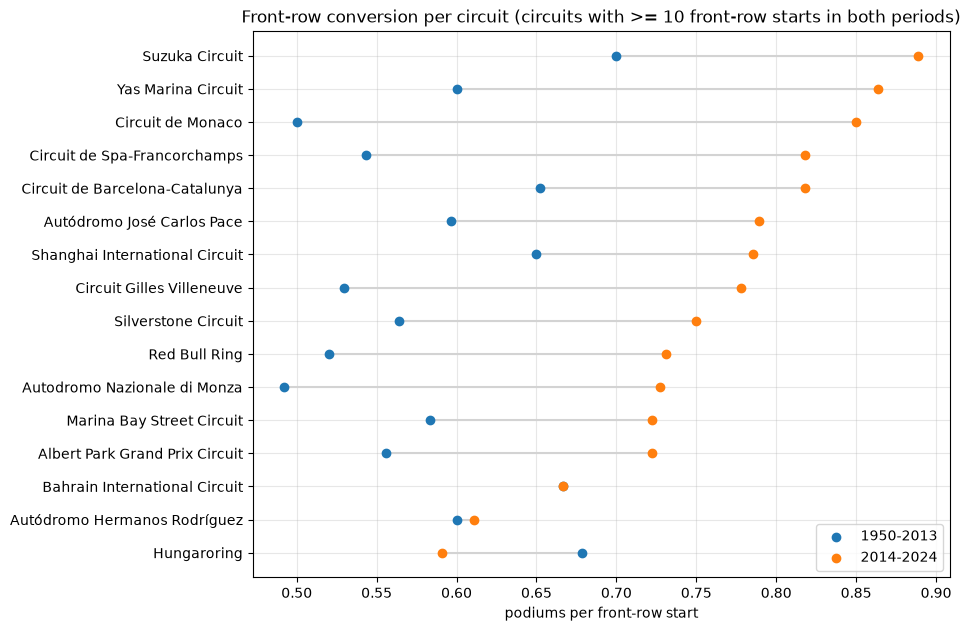

In [31]:
plot_t = in_both.sort_values('2014-2024')
y = np.arange(len(plot_t))
plt.figure(figsize=(9, 0.35 * len(plot_t) + 1.5))
plt.hlines(y, plot_t['1950-2013'], plot_t['2014-2024'], color='lightgray')
plt.scatter(plot_t['1950-2013'], y, label='1950-2013', zorder=3)
plt.scatter(plot_t['2014-2024'], y, label='2014-2024', zorder=3)
plt.yticks(y, plot_t.index)
plt.xlabel('podiums per front-row start')
plt.title('Front-row conversion per circuit (circuits with >= 10 front-row starts in both periods)')
plt.legend(loc='lower right')
save_fig('q1_front_row_conversion')
plt.show()

**Qualifying position vs grid.** From 1994, where both exist, we compare the two definitions:

In [32]:
modern = q1_rows[q1_rows['year'] >= 1994]
grid_front = modern['grid'].isin([1, 2])
quali_front = modern['quali_pos'].isin([1, 2])
definitions = []
for period, label in [('1950-2013', '1994-2013'), ('2014-2024', '2014-2024')]:
    same_period = modern['period'] == period
    for name, rows in [('front-row start (grid)', modern[same_period & grid_front]),
                       ('front-row qualifier (qualifying)', modern[same_period & quali_front])]:
        definitions.append({'period': label, 'definition': name, 'rows': len(rows), 'podium rate': round(rows['podium'].mean(), 3)})
display(pd.DataFrame(definitions))

moved_back = modern[quali_front & ~grid_front]
print(f'Front-row qualifiers who did not start from the front row: {len(moved_back)} of {quali_front.sum()}, '
      f'podium rate {moved_back["podium"].mean():.2f}')
quali_conversion, _ = front_row_conversion(modern[quali_front])
by_quali = quali_conversion['2014-2024'].dropna()
by_grid_modern = conversion['2014-2024'].reindex(by_quali.index)
print(f'2014-2024 circuit ranking, grid vs qualifying definition: Spearman {by_quali.corr(by_grid_modern, method="spearman"):.2f}')

,period,definition,rows,podium rate
0,1994-2013,front-row start (grid),698,0.642
1,1994-2013,front-row qualifier (qualifying),532,0.647
2,2014-2024,front-row start (grid),454,0.760
3,2014-2024,front-row qualifier (qualifying),454,0.740


Front-row qualifiers who did not start from the front row: 36 of 986, podium rate 0.31
2014-2024 circuit ranking, grid vs qualifying definition: Spearman 0.90


**Answer Q1.**

- **Best converters since 2014** (circuits with ≥ 10 front-row starts in both periods): Suzuka 89%, Yas Marina 86%, Monaco 85%, Barcelona and Spa 82%. **Before 2014** the same circuits were led by Suzuka 70%, Hungaroring 68%, Bahrain 67%, Barcelona and Shanghai 65%.
- **The ranking changed completely.** The rank correlation between the two periods is −0.03, i.e. knowing a circuit's rank before 2014 tells you nothing about its rank after. Hungaroring fell from 2nd to last (16th) and Monaco rose from 15th to 3rd. With the "before" period limited to 1994–2013 the correlation is −0.07, and with the "after" period limited to the hybrid era (2014–2021) it is 0.01, so neither the 1950s–80s nor the 2022–2024 seasons drive the answer. Nor does the minimum of 10 front-row starts: with any minimum from 6 to 15 the correlation stays between −0.13 and 0.06, and Suzuka is the best converter since 2014 every time.
- **Almost every circuit converts more often after 2014** (56% → 76% overall), in line with the better reliability in 4.4. Only Bahrain and Mexico stayed flat, and Hungaroring went down.
- **Qualifying vs grid.** Since 1994, 36 of 986 front-row qualifiers did not start from the front row (grid penalties), and only 31% of them reached the podium, against 64–76% for the front row overall. Averaged over all circuits the two definitions give almost the same rate (65% vs 64% before 2014, 74% vs 76% after), and the 2014–2024 circuit ranking hardly changes with the definition (rank correlation 0.90).
- **Caveat.** After 2014 each circuit has only 14–26 front-row starts, so one podium moves its rate by 4–7 points. Neighbouring ranks are not meaningfully different; the large moves (Hungaroring, Monaco) are.

### Q2. Do drivers podium more often at home, after controlling for starting position?

**Joins.** `results → drivers` (nationality) and `results → races → circuits` (country). The two use different vocabularies (`British` vs `UK`), so we map each nationality to a country by hand (table below).
**Grain.** One row = one starter at one race. *Home* = the circuit is in the driver's country.
**Control for starting position.** We compare home and away drivers *within the same grid band*, then pool the bands with the Cochran–Mantel–Haenszel (CMH) test. Each band gives a 2×2 table (home/away × podium/no podium); CMH combines them into one odds ratio and tests whether it differs from 1. An odds ratio of 1 means no home effect.
**Missingness.** Every starter has a nationality, a circuit country and a grid position.

Mapping assumptions: drivers with two nationalities (`American-Italian`, `Argentine-Italian`) take the first; `East German` maps to Germany; `Rhodesian` and `Liechtensteiner` have no circuit, so they are never home. The spelling variants `Argentinian` and `United States` were already given one name in 3.1.

,home starts,home rate,away starts,away rate
grid_band,,,,
P1,82,0.622,1034,0.648
P2-3,149,0.550,2079,0.510
P4-6,227,0.269,3115,0.261
P7-10,336,0.071,4118,0.092
P11-15,415,0.024,5126,0.030
P16+,735,0.003,7308,0.007


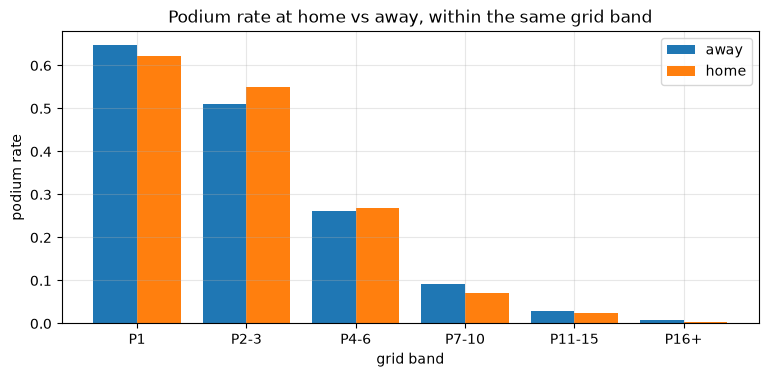

In [33]:
NATIONALITY_TO_COUNTRY = {
    'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium',
    'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada', 'Chilean': 'Chile', 'Chinese': 'China',
    'Colombian': 'Colombia', 'Czech': 'Czech Republic', 'Danish': 'Denmark', 'Dutch': 'Netherlands',
    'East German': 'Germany', 'Finnish': 'Finland', 'French': 'France', 'German': 'Germany', 'Hungarian': 'Hungary',
    'Indian': 'India', 'Indonesian': 'Indonesia', 'Irish': 'Ireland', 'Italian': 'Italy', 'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand', 'Polish': 'Poland', 'Portuguese': 'Portugal', 'Rhodesian': 'Rhodesia',
    'Russian': 'Russia', 'South African': 'South Africa', 'Spanish': 'Spain', 'Swedish': 'Sweden', 'Swiss': 'Switzerland',
    'Thai': 'Thailand', 'Uruguayan': 'Uruguay', 'Venezuelan': 'Venezuela',
}
assert set(nationality) <= set(NATIONALITY_TO_COUNTRY)

driver_country = nationality.map(NATIONALITY_TO_COUNTRY)
circuit_country = clean['circuits'].set_index('circuitId')['country']


def add_home(rows):
    return rows.assign(home=(rows['driverId'].map(driver_country) == rows['circuitId'].map(circuit_country)).astype(int))


GRID_BANDS = [0, 1, 3, 6, 10, 15, 99]
GRID_LABELS = ['P1', 'P2-3', 'P4-6', 'P7-10', 'P11-15', 'P16+']


def add_home_and_grid_band(rows):
    out = add_home(rows)
    out['grid_pos'] = out['grid'].where(out['grid'] > 0, 99)     # pit-lane starts go to the back
    out['grid_band'] = pd.cut(out['grid_pos'], GRID_BANDS, labels=GRID_LABELS)
    return out


def home_effect(rows, strata):
    # pooled odds ratio of podium for home vs away, within strata of starting position
    tables = []
    for _, g in rows.groupby(strata, observed=True):
        t = pd.crosstab(g['home'], g['podium']).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
        if t[0].sum() > 0 and t[1].sum() > 0:
            tables.append(t)
    st = StratifiedTable(tables)
    low, high = st.oddsratio_pooled_confint()
    p_value = vars(st.test_null_odds())['pvalue']   # Mantel-Haenszel test of "pooled odds ratio = 1"
    return {'home starts': rows['home'].sum(), 'home podium rate': rows.loc[rows['home'] == 1, 'podium'].mean(),
            'away podium rate': rows.loc[rows['home'] == 0, 'podium'].mean(),
            'pooled odds ratio': st.oddsratio_pooled, 'CI low': low, 'CI high': high, 'p-value': p_value}


q2_rows = add_home_and_grid_band(starters)
bands = q2_rows.groupby(['grid_band', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
bands.columns = ['away rate', 'home rate', 'away starts', 'home starts']
bands = bands[['home starts', 'home rate', 'away starts', 'away rate']]
display(bands.round(3))

band_pos = np.arange(len(bands))
plt.figure(figsize=(9, 3.8))
plt.bar(band_pos - 0.2, bands['away rate'], width=0.4, label='away')
plt.bar(band_pos + 0.2, bands['home rate'], width=0.4, label='home')
plt.xticks(band_pos, bands.index)
plt.xlabel('grid band')
plt.ylabel('podium rate')
plt.title('Podium rate at home vs away, within the same grid band')
plt.legend()
save_fig('q2_home_by_grid_band')
plt.show()

The answer should not depend on how the grid is grouped or on the Indianapolis 500, so we run the same test four ways:

In [34]:
with_indy = add_home_and_grid_band(entries[started])
q2_trials = pd.DataFrame({
    'grid bands, no Indy 500 (main)': home_effect(q2_rows, 'grid_band'),
    'exact grid position, no Indy 500': home_effect(q2_rows, 'grid_pos'),
    'grid bands, with Indy 500': home_effect(with_indy, 'grid_band'),
    'grid bands, 1994-2024 only': home_effect(q2_rows[q2_rows['year'] >= 1994], 'grid_band'),
}).T
q2_trials.round(3)

,home starts,home podium rate,away podium rate,pooled odds ratio,CI low,CI high,p-value
"grid bands, no Indy 500 (main)",1944.0,0.118,0.137,0.952,0.801,1.131,0.579
"exact grid position, no Indy 500",1944.0,0.118,0.137,0.957,0.804,1.139,0.624
"grid bands, with Indy 500",2324.0,0.114,0.137,0.959,0.818,1.124,0.606
"grid bands, 1994-2024 only",594.0,0.126,0.141,0.695,0.507,0.952,0.025


**Answer Q2.**

- **No home advantage.** Without any control, home drivers podium *less* often (11.8% vs 13.7%, 1,944 home starts). Within each grid band the home and away rates are close (P1: 62% vs 65%, P2–3: 55% vs 51%, P4–6: 27% vs 26%).
- **Controlling for starting position** (CMH over grid bands): pooled odds ratio 0.95, 95% CI 0.80–1.13, p = 0.58. The interval contains 1, so there is no evidence that racing at home changes the odds of a podium for drivers who start from similar positions.
- **The answer is stable**: exact grid position instead of bands gives 0.96 (p = 0.62), and adding the Indianapolis 500 back gives 0.96 (p = 0.61).
- **1994–2024 only**: odds ratio 0.70 (CI 0.51–0.95, p = 0.025), i.e. home drivers did *worse* than away drivers from the same grid band. This is one of four variants we ran, so a p-value of 0.025 is weak evidence; we report it but do not build on it.
- The `home` flag is still tested as a model feature in 8.3.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Joins.** `results → status` (why the race ended) `→ constructors`, and `→ races` for the season.
**Grain.** One row = one car that started one race. **Rate** = mechanical retirements ÷ race starts.
**Mechanical** means a component of the car failed. Crashes, driver causes and regulation decisions are not mechanical. The `status` table has 139 values, so we group them by hand below. Following the course staff's clarification, tyre failures and punctures (`Tyre`, `Puncture`, `Tyre puncture`), `Fire` and `Safety belt` count as mechanical, and `Refuelling` does not. Statuses that can be either a failure or the result of contact or a team error (wing, wheel, wheel nut, damage, debris, the bare `Retired`) go to an *unclear* group, and we check whether counting them as mechanical changes the answer.
**Missingness.** Every result has a status. Rows whose status says the driver did not take the start (`Withdrew` with a grid slot) are not race starts, so they are left out of the denominator.
**Ranking.** Every constructor is ranked, small teams included. The 95% Wilson interval shows how uncertain each rate is (a rate from 34 starts is far less certain than one from 320), instead of hiding small teams behind a minimum number of starts.
**Note.** Constructors are identified by `constructorId`, so a renamed team is a different constructor (Renault became Alpine, Toro Rosso became AlphaTauri then RB, Force India became Racing Point then Aston Martin).

In [35]:
STATUS_GROUPS = {
    'mechanical': ['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Electronics', 'Brakes',
                   'Suspension', 'Power Unit', 'ERS', 'Turbo', 'Power loss', 'Battery', 'Spark plugs', 'Ignition', 'Injection',
                   'Magneto', 'Distributor', 'Alternator', 'Engine misfire', 'Engine fire', 'Supercharger', 'Crankshaft',
                   'Differential', 'Driveshaft', 'Halfshaft', 'Drivetrain', 'CV joint', 'Axle', 'Oil leak', 'Oil pressure',
                   'Oil pump', 'Oil pipe', 'Oil line', 'Water leak', 'Water pressure', 'Water pump', 'Water pipe', 'Overheating',
                   'Radiator', 'Cooling system', 'Fuel system', 'Fuel pressure', 'Fuel pump', 'Fuel leak', 'Fuel pipe', 'Throttle',
                   'Exhaust', 'Steering', 'Track rod', 'Wheel bearing', 'Wheel rim', 'Chassis', 'Undertray', 'Brake duct',
                   'Pneumatics', 'Heat shield fire', 'Mechanical', 'Technical', 'Launch control', 'Seat', 'Driver Seat', 'Safety belt',
                   'Tyre', 'Puncture', 'Tyre puncture', 'Fire'],
    'accident': ['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident'],
    'driver': ['Physical', 'Illness', 'Driver unwell', 'Injury', 'Injured', 'Eye injury', 'Stalled'],
    'regulation': ['Disqualified', 'Excluded', 'Underweight', '107% Rule', 'Did not qualify', 'Did not prequalify'],
    'did not start': ['Withdrew', 'Safety concerns', 'Safety', 'Not restarted'],
    'unclear': ['Retired', 'Wheel', 'Wheel nut', 'Front wing', 'Rear wing', 'Broken wing', 'Damage', 'Debris', 'Vibrations',
                'Handling', 'Fuel', 'Out of fuel', 'Fuel rig', 'Refuelling', 'Not classified'],
}
STATUS_TO_GROUP = {s: group for group, statuses in STATUS_GROUPS.items() for s in statuses}

status_text = clean['status'].set_index('statusId')['status']
status_group = status_text.map(STATUS_TO_GROUP).mask(status_text.str.match(FINISHED), 'finished')
assert status_group.notna().all(), 'a status is not mapped'

q3_rows = starters[starters['year'].between(2014, 2024)].copy()
q3_rows['status_group'] = q3_rows['statusId'].map(status_group)
did_not_start = q3_rows['status_group'] == 'did not start'
print('Rows with a grid slot that did not take the start:', did_not_start.sum())
q3_rows = q3_rows[~did_not_start].copy()
q3_rows['period'] = np.where(q3_rows['year'] <= 2021, '2014-2021', '2022-2024')
print(q3_rows['status_group'].value_counts().to_dict())
q3_rows.loc[q3_rows['status_group'] == 'unclear', 'status'].value_counts().to_dict()

Rows with a grid slot that did not take the start: 11
{'finished': 3825, 'mechanical': 387, 'accident': 305, 'unclear': 76, 'regulation': 12, 'driver': 3}


{'Retired': 50,
 'Wheel': 11,
 'Rear wing': 3,
 'Front wing': 3,
 'Wheel nut': 3,
 'Vibrations': 2,
 'Damage': 2,
 'Out of fuel': 1,
 'Debris': 1}

In [36]:
constructor_name = clean['constructors'].set_index('constructorId')['name']


def mechanical_rates(rows, count_unclear=False):
    failed = rows['status_group'].eq('mechanical') | (count_unclear & rows['status_group'].eq('unclear'))
    t = rows.assign(mechanical=failed).groupby(['period', 'constructorId']).agg(starts=('mechanical', 'size'),
                                                                                 mechanical=('mechanical', 'sum')).reset_index()
    t['constructor'] = t['constructorId'].map(constructor_name)
    t['rate'] = t['mechanical'] / t['starts']
    t['ci_low'], t['ci_high'] = proportion_confint(t['mechanical'], t['starts'], method='wilson')
    return t.sort_values(['period', 'rate'], ascending=[True, False])


q3_rates = mechanical_rates(q3_rows)
print('Mechanical retirements per start, all constructors:',
      q3_rows['status_group'].eq('mechanical').groupby(q3_rows['period']).mean().round(3).to_dict())
q3_table = {period: g.set_index('constructor')[['starts', 'mechanical', 'rate', 'ci_low', 'ci_high']].round(3)
            for period, g in q3_rates.groupby('period')}
display(pd.concat(q3_table, axis=1))

Mechanical retirements per start, all constructors: {'2014-2021': 0.095, '2022-2024': 0.058}


2014-2021                                  2022-2024                                 
                  starts mechanical   rate ci_low ci_high    starts mechanical   rate ci_low ci_high
constructor                                                                                         
Caterham            34.0        8.0  0.235  0.124   0.400       NaN        NaN    NaN    NaN     NaN
Lotus F1            75.0       14.0  0.187  0.115   0.289       NaN        NaN    NaN    NaN     NaN
Toro Rosso         242.0       40.0  0.165  0.124   0.217       NaN        NaN    NaN    NaN     NaN
McLaren            318.0       43.0  0.135  0.102   0.177     136.0        5.0  0.037  0.016   0.083
Renault            200.0       27.0  0.135  0.094   0.189       NaN        NaN    NaN    NaN     NaN
Sauber             200.0       23.0  0.115  0.078   0.167      48.0        1.0  0.021  0.004   0.109
Red Bull           319.0       36.0  0.113  0.083   0.152     136.0        5.0  0.037  0.016   0.083
Racing Point        76.0        8.0  0.105  0.054   0.194       NaN        NaN    NaN    NaN     NaN
Marussia            31.0        3.0  0.097  0.033   0.249       NaN        NaN    NaN    NaN     NaN
AlphaTauri          77.0        7.0  0.091  0.045   0.176      88.0        7.0  0.080  0.039   0.155
Williams           319.0       25.0  0.078  0.054   0.113     134.0        8.0  0.060  0.031   0.113
Haas F1 Team       241.0       18.0  0.075  0.048   0.115     135.0        6.0  0.044  0.021   0.094
Alpine F1 Team      44.0        3.0  0.068  0.023   0.182     136.0       15.0  0.110  0.068   0.174
Force India        199.0       13.0  0.065  0.039   0.109       NaN        NaN    NaN    NaN     NaN
Ferrari            319.0       18.0  0.056  0.036   0.087     135.0        8.0  0.059  0.030   0.113
Manor Marussia      77.0        4.0  0.052  0.020   0.126       NaN        NaN    NaN    NaN     NaN
Mercedes           320.0       13.0  0.041  0.024   0.068     136.0        6.0  0.044  0.020   0.093
Alfa Romeo         120.0        4.0  0.033  0.013   0.083      88.0       11.0  0.125  0.071   0.210
Aston Martin        44.0        1.0  0.023  0.004   0.118     133.0        5.0  0.038  0.016   0.085
RB F1 Team           NaN        NaN    NaN    NaN     NaN      48.0        2.0  0.042  0.012   0.140

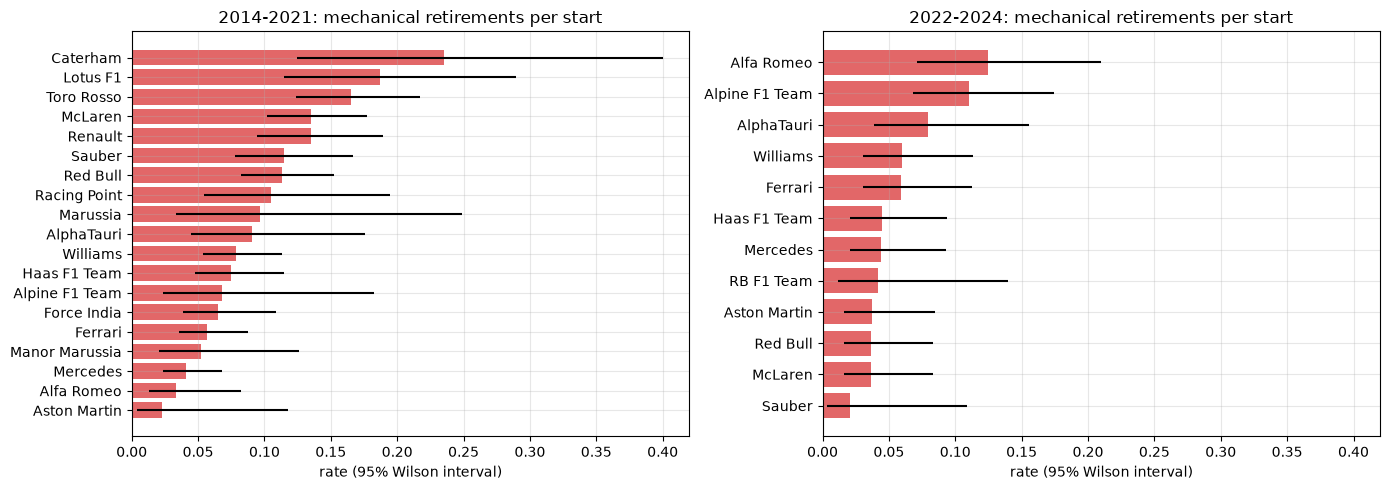

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (period, g) in zip(axes, q3_rates.groupby('period')):
    g = g.sort_values('rate')
    ax.barh(g['constructor'], g['rate'], xerr=[g['rate'] - g['ci_low'], g['ci_high'] - g['rate']], color='tab:red', alpha=0.7)
    ax.set_title(f'{period}: mechanical retirements per start')
    ax.set_xlabel('rate (95% Wilson interval)')
plt.tight_layout()
save_fig('q3_mechanical_rate')
plt.show()

**Sensitivity.** Counting the *unclear* statuses as mechanical:

In [38]:
q3_unclear = mechanical_rates(q3_rows, count_unclear=True)
pd.DataFrame({
    period: {'top 3 (main)': ', '.join(q3_rates.loc[q3_rates['period'] == period, 'constructor'].head(3)),
             'top 3 (unclear counted)': ', '.join(q3_unclear.loc[q3_unclear['period'] == period, 'constructor'].head(3))}
    for period in ['2014-2021', '2022-2024']}).T

,top 3 (main),top 3 (unclear counted)
2014-2021,"Caterham, Lotus F1, Toro Rosso","Caterham, Lotus F1, Toro Rosso"
2022-2024,"Alfa Romeo, Alpine F1 Team, AlphaTauri","Alfa Romeo, Alpine F1 Team, RB F1 Team"


**Answer Q3.**

- **2014–2021:** Caterham has the highest rate, 23.5% of starts ending in a mechanical retirement (8 of 34, its only season in this period), then Lotus F1 18.7% (14/75) and Toro Rosso 16.5% (40/242); McLaren and Renault follow with 13.5%. The intervals of the top three overlap (Caterham 12–40%, Lotus F1 12–29%, Toro Rosso 12–22%), so they cannot be strictly ordered; Toro Rosso's rate is the most certain (242 starts). Of the teams that raced all eight seasons, Mercedes was the most reliable (4.1%).
- **2022–2024:** Alfa Romeo 12.5% (11/88), Alpine 11.0% (15/136), AlphaTauri 8.0% (7/88). Most teams are between 2% and 6%.
- **Mechanical retirements became rarer overall** (9.5% of starts in 2014–2021, 5.8% in 2022–2024). McLaren (13.5% → 3.7%) and Red Bull (11.3% → 3.7%) improved the most.
- **Sensitivity:** counting the unclear statuses as mechanical, the leaders stay the same: Caterham, Lotus F1 and Toro Rosso in 2014–2021; Alfa Romeo and Alpine, then RB instead of AlphaTauri, in 2022–2024.
- **Caveats:** the intervals are wide (about ±4–5 points with ~130 starts, ±14 with Caterham's 34), so teams in the middle cannot be ranked against each other. Renamed teams count separately: Alfa Romeo (2022–23) and Sauber (2024) are the same team, 12 of 136 starts (8.8%) together.

## 6. Feature engineering

### 6.1 Leakage screen

A column can be a feature only if its value is known after qualifying and before the start.

| Table | Columns | Known before the start? | Use |
| --- | --- | --- | --- |
| `results` | `grid` | yes, the starting grid | feature |
| `results` | `positionOrder`, `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId` | no, race outcome | target only (`positionOrder`); from *earlier* races through form, circuit-history and reliability features |
| `qualifying` | `position`, `q1`, `q2`, `q3` | yes | features (including the gap to the team-mate) |
| `driver_standings`, `constructor_standings` | `position`, `points`, `wins` | only the standings after the *previous* round | shifted by one round |
| `constructor_results` | `points` | no for the current race | not used (the standings already hold it) |
| `lap_times`, `pit_stops` | all | no, recorded during the race | not used |
| `sprint_results` | all | yes (sprint runs before the race) | not used, see 6.4 |
| `races`, `drivers`, `circuits` | date, round, circuit, date of birth, nationality, country | yes | ordering, circuit history, age, home race |

### 6.2 Features

Each feature belongs to a group; the groups are reused by the ablation in section 14.

| Group | Feature | Meaning |
| --- | --- | --- |
| grid | `grid_pos` | starting position; pit-lane start = back of the field |
| grid | `pit_lane_start` | 1 if the driver starts from the pit lane |
| qualifying | `quali_pos` | qualifying position |
| qualifying | `q1_gap_pct` | % slower than the fastest Q1 time of the race (the only session every driver runs) |
| qualifying | `best_gap_pct` | % slower than pole, using each driver's best time in any session (alternative to `q1_gap_pct`, compared in 8.3) |
| qualifying | `grid_minus_quali` | places lost (+) or gained (−) between qualifying and the grid |
| standings | `drv_standing`, `con_standing` | championship position after the previous round |
| standings | `drv_points_share`, `con_points_share` | points after the previous round ÷ the most points among this race's starters, normally the leader (scale-free across points systems) |
| standings | `drv_points`, `con_points`, `drv_wins` | raw values, kept only for the comparison in 8.3 |
| driver form | `drv_podium_last` | podium rate over the driver's last *n* starts |
| driver form | `drv_finish_last` | average finishing percentile over the last *n* starts (finishing position ÷ starters: 1/n = won, 1 = last) |
| driver form | `drv_career_podium` | podium rate over all earlier starts |
| constructor form | `con_podium_last` | share of the team's last *n* races with a car on the podium |
| constructor form | `con_finish_last` | average best finishing percentile of the team over its last *n* races |
| teammate | `grid_vs_teammate` | grid position minus the team-mate's (negative = ahead of the other car of the same team) |
| teammate | `q1_gap_vs_teammate` | `q1_gap_pct` minus the team-mate's: the driver's pace in the same car |
| circuit history | `drv_circuit_podium`, `con_circuit_podium` | podium rate of the driver / the team in earlier races at this circuit |
| reliability | `drv_dnf_last` | share of the driver's last 10 starts that did not reach the finish (any cause) |
| reliability | `con_mech_last` | share of the team's car starts in its last 10 races that ended in a mechanical failure (groups from question 3) |
| experience | `drv_starts`, `driver_age` | earlier starts; age on race day |
| context | `field_size`, `home` | starters in the race; circuit in the driver's country |

Form, circuit-history and reliability features only look backwards: for each driver (or team, or driver at a circuit) the rows are ordered by race date, shifted by one race, and then averaged, so the current race is never included. We start with a form window of the last 5 races; section 8.3 compares 3, 5, 10 and 20 and rebuilds the table with the chosen window. The reliability window is fixed at 10 races: retirements are rare (about 1 start in 10 ends in a mechanical failure in 2014–2021, question 3), so over 3 races almost every value would be 0.

The teammate, circuit-history and reliability groups are candidates added on purpose: car performance dominates most eras (F1 introduction), so comparing a driver with the team-mate in the same car isolates the driver; some drivers and teams are consistently strong at particular circuits; and a podium requires reaching the finish, which question 3 shows differs strongly between teams. Section 8 decides whether they add anything.

In [39]:
def past_mean(rows, by, col, n=None):
    # mean of `col` over the previous n rows of the same group (a driver, a team, a driver at one circuit, ...);
    # all previous rows if n is None. `rows` must be sorted by date.
    group = rows.groupby(by).ngroup()
    window = rows[col].groupby(group).shift(1).groupby(group)
    if n is None:
        return window.transform(lambda s: s.expanding().mean())
    return window.transform(lambda s: s.rolling(n, min_periods=1).mean())


def standings_before(rows):
    # standings after the previous round of the same season (round 1 has none)
    prev = clean['races'][['raceId', 'year', 'round']].assign(round=lambda r: r['round'] + 1).rename(columns={'raceId': 'prev_raceId'})
    rows = rows.merge(prev, on=['year', 'round'], how='left', validate='m:1')
    ds = clean['driver_standings'].rename(columns={'raceId': 'prev_raceId', 'position': 'drv_standing', 'points': 'drv_points', 'wins': 'drv_wins'})
    cs = clean['constructor_standings'].rename(columns={'raceId': 'prev_raceId', 'position': 'con_standing', 'points': 'con_points'})
    rows = rows.merge(ds[['prev_raceId', 'driverId', 'drv_standing', 'drv_points', 'drv_wins']], on=['prev_raceId', 'driverId'], how='left', validate='m:1')
    rows = rows.merge(cs[['prev_raceId', 'constructorId', 'con_standing', 'con_points']], on=['prev_raceId', 'constructorId'], how='left', validate='m:1')
    rows['drv_points_share'] = rows['drv_points'] / rows.groupby('prev_raceId')['drv_points'].transform('max').replace(0, np.nan)
    rows['con_points_share'] = rows['con_points'] / rows.groupby('prev_raceId')['con_points'].transform('max').replace(0, np.nan)
    return rows.drop(columns='prev_raceId')


def build_features(rows, n_form, history=None):
    # rows: one row per driver-race; history: past results used for form (default: rows itself)
    X = rows[KEY + ['constructorId', 'circuitId', 'year', 'round', 'date', 'grid', 'podium']].copy()

    # grid
    X['field_size'] = X.groupby('raceId')['raceId'].transform('size')
    X['pit_lane_start'] = (X['grid'] == 0).astype(int)
    X['grid_pos'] = X['grid'].where(X['grid'] > 0, X['field_size'])

    # qualifying
    q = clean['qualifying'][KEY + ['position', 'q1', 'q2', 'q3']].rename(columns={'position': 'quali_pos'})
    q['q1_gap_pct'] = 100 * (q['q1'] / q.groupby('raceId')['q1'].transform('min') - 1)
    q['best_time'] = q[['q1', 'q2', 'q3']].min(axis=1)
    q['best_gap_pct'] = 100 * (q['best_time'] / q.groupby('raceId')['best_time'].transform('min') - 1)
    X = X.merge(q[KEY + ['quali_pos', 'q1_gap_pct', 'best_gap_pct']], on=KEY, how='left', validate='1:1')
    X['grid_minus_quali'] = X['grid_pos'] - X['quali_pos']

    # teammate: the driver against the other car(s) of the same team in the same race
    team_cars = X.groupby(['raceId', 'constructorId'])
    other_cars = (team_cars['grid_pos'].transform('size') - 1).replace(0, np.nan)
    X['grid_vs_teammate'] = X['grid_pos'] - (team_cars['grid_pos'].transform('sum') - X['grid_pos']) / other_cars
    others_with_q1 = (team_cars['q1_gap_pct'].transform('count') - X['q1_gap_pct'].notna()).replace(0, np.nan)
    others_q1_sum = team_cars['q1_gap_pct'].transform('sum') - X['q1_gap_pct'].fillna(0)
    X['q1_gap_vs_teammate'] = X['q1_gap_pct'] - others_q1_sum / others_with_q1

    # standings before the race
    X = standings_before(X)

    # driver form, from earlier starts only
    past = (rows if history is None else history)[KEY + ['constructorId', 'circuitId', 'date', 'positionOrder', 'podium', 'statusId']]
    past = past.sort_values(['date', 'raceId']).copy()
    past['finish_pct'] = past.groupby('raceId')['positionOrder'].rank(pct=True)
    past['drv_podium_last'] = past_mean(past, 'driverId', 'podium', n_form)
    past['drv_finish_last'] = past_mean(past, 'driverId', 'finish_pct', n_form)
    past['drv_career_podium'] = past_mean(past, 'driverId', 'podium')
    past['drv_starts'] = past.groupby('driverId').cumcount()
    past['drv_circuit_podium'] = past_mean(past, ['driverId', 'circuitId'], 'podium')
    past['dnf'] = (past['statusId'].map(status_group) != 'finished').astype(int)
    past['mechanical'] = (past['statusId'].map(status_group) == 'mechanical').astype(int)
    past['drv_dnf_last'] = past_mean(past, 'driverId', 'dnf', RELIABILITY_WINDOW)
    X = X.merge(past[KEY + ['drv_podium_last', 'drv_finish_last', 'drv_career_podium', 'drv_starts', 'drv_circuit_podium', 'drv_dnf_last']],
                on=KEY, how='left', validate='1:1')

    # constructor: one row per team per race, then the same backward windows
    team = past.groupby(['constructorId', 'raceId']).agg(date=('date', 'first'), circuitId=('circuitId', 'first'),
                                                         podium=('podium', 'max'), finish_pct=('finish_pct', 'min'),
                                                         mechanical=('mechanical', 'mean')).reset_index()
    team = team.sort_values(['date', 'raceId'])
    team['con_podium_last'] = past_mean(team, 'constructorId', 'podium', n_form)
    team['con_finish_last'] = past_mean(team, 'constructorId', 'finish_pct', n_form)
    team['con_circuit_podium'] = past_mean(team, ['constructorId', 'circuitId'], 'podium')
    team['con_mech_last'] = past_mean(team, 'constructorId', 'mechanical', RELIABILITY_WINDOW)
    X = X.merge(team[['constructorId', 'raceId', 'con_podium_last', 'con_finish_last', 'con_circuit_podium', 'con_mech_last']],
                on=['constructorId', 'raceId'], how='left', validate='m:1')

    # experience and context
    X['driver_age'] = (X['date'] - X['driverId'].map(clean['drivers'].set_index('driverId')['dob'])).dt.days / 365.25
    X = add_home(X)
    return X


RELIABILITY_WINDOW = 10
ALL_FEATURES = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct', 'best_gap_pct', 'grid_minus_quali',
                'drv_standing', 'con_standing', 'drv_points_share', 'con_points_share', 'drv_points', 'con_points', 'drv_wins',
                'drv_podium_last', 'drv_finish_last', 'drv_career_podium', 'con_podium_last', 'con_finish_last',
                'grid_vs_teammate', 'q1_gap_vs_teammate', 'drv_circuit_podium', 'con_circuit_podium', 'drv_dnf_last', 'con_mech_last',
                'drv_starts', 'driver_age', 'field_size', 'home']
features = build_features(starters, n_form=5)
print(features.shape)
features[ALL_FEATURES].describe().T.round(2)

(24724, 37)


,count,mean,std,min,25%,50%,75%,max
grid_pos,24724.0,11.81,6.75,1.00,6.00,12.00,17.00,34.00
pit_lane_start,24724.0,0.00,0.05,0.00,0.00,0.00,0.00,1.00
quali_pos,10478.0,11.19,6.25,1.00,6.00,11.00,16.00,26.00
q1_gap_pct,10322.0,1.85,1.93,0.00,0.71,1.34,2.36,44.78
best_gap_pct,10322.0,2.40,2.57,0.00,0.91,1.84,3.07,45.60
grid_minus_quali,10478.0,0.01,1.52,-9.00,0.00,0.00,0.00,23.00
drv_standing,21798.0,12.86,8.95,1.00,6.00,12.00,18.00,102.00
con_standing,21795.0,6.10,3.63,1.00,3.00,6.00,9.00,20.00
drv_points_share,21798.0,0.22,0.29,0.00,0.00,0.08,0.33,1.00
con_points_share,21795.0,0.30,0.34,0.00,0.02,0.14,0.50,1.00


### 6.3 Leakage checks

Automatic checks that no feature uses the race it describes:

In [40]:
def check_no_leakage(X, rows, n_form):
    # X: the feature table built from `rows` (sorted by date)
    first_start = X.sort_values(['date', 'raceId']).groupby('driverId').head(1)
    assert first_start[['drv_podium_last', 'drv_finish_last', 'drv_career_podium']].isna().all().all()
    assert (first_start['drv_starts'] == 0).all()
    assert X.loc[X['round'] == 1, ['drv_standing', 'con_standing']].isna().all().all()
    first_visit = X.sort_values(['date', 'raceId']).groupby(['driverId', 'circuitId']).head(1)
    assert first_visit['drv_circuit_podium'].isna().all()
    first_team_race = X.sort_values(['date', 'raceId']).groupby('constructorId').head(1)
    assert first_team_race[['con_podium_last', 'con_mech_last']].isna().all().all()
    for _, row in X.sample(300, random_state=SEED).iterrows():
        past = rows[(rows['driverId'] == row['driverId']) & (rows['date'] < row['date'])].tail(n_form)
        expected = past['podium'].mean() if len(past) else np.nan
        assert np.isclose(expected, row['drv_podium_last'], equal_nan=True)
    print(f'Leakage checks passed (form window = {n_form} races)')


check_no_leakage(features, starters, n_form=5)

Leakage checks passed (form window = 5 races)


1. A driver's first start has no form and `drv_starts = 0`.
2. Round 1 of every season has no standings (nothing has been raced yet).
3. A driver's first race at a circuit has no circuit history, and a team's first race has no team form or reliability.
4. For 300 random rows, the driver's podium rate over the last *n* starts is recomputed by hand from strictly earlier races and matches.

The checks run again on the final features in 8.3.

### 6.4 Sprint results: a leakage judgement

The sprint (2021–2024) is run before the Sunday race, so its result is known at our cutoff: **using it would not be leakage.** Two related points:

- In 2021–2022 the sprint result *set* the Sunday grid, so its information is already inside `grid_pos`.
- The sprint's points enter the championship standings of that weekend's round. We never use those: the standings are taken after the *previous* round (6.2), so they contain no information from the current weekend at all.

We still leave the sprint result out as a feature:

In [41]:
sprint_races = clean['sprint_results']['raceId'].unique()
print(features.assign(has_sprint=features['raceId'].isin(sprint_races))
      .groupby(pd.cut(features['year'], [1949, 2019, 2021, 2024], labels=['train (<=2019)', 'val (2020-21)', 'test (2022-24)']), observed=True)
      ['has_sprint'].agg(['sum', 'mean']).rename(columns={'sum': 'rows with a sprint', 'mean': 'share'}))

                rows with a sprint     share
year                                        
train (<=2019)                   0  0.000000
val (2020-21)                   59  0.075738
test (2022-24)                 299  0.220501


Sprints start in 2021, so no training row has one: a sprint feature would be missing for 100% of the training data and the model could not learn what it means. In 2021–2022 the sprint result also *set* the Sunday grid, so its information is already in `grid_pos`.

## 7. Data split

We split by season, as suggested in the F1 introduction: **train ≤ 2019, validation 2020–2021, test 2022–2024.**

- The model is used to predict future races from past ones, so it must never train on seasons after the ones it is evaluated on.
- A race always stays in one split. The three podium places of a race depend on each other, so splitting a race's drivers would leak information.
- Section 4.2 showed that the grid-to-podium relationship drifts across eras. A time split measures how well the model handles that drift. The test set is the new 2022 ground-effect era, an honest but harder test.

In [42]:
def split_of(year):
    return np.select([year <= 2019, year <= 2021], ['train', 'val'], 'test')


features['split'] = split_of(features['year'])
assert features.groupby('raceId')['split'].nunique().max() == 1
split_summary = features.groupby('split').agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'),
                                              rows=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'))
split_summary.loc[['train', 'val', 'test']].round(3)

,seasons,races,rows,podiums,podium_rate
split,,,,,
train,1950-2019,1007,22589,3038,0.134
val,2020-2021,39,779,117,0.150
test,2022-2024,68,1356,204,0.150


The podium rate is 13% in train and 15% in validation and test: the training seasons include the larger fields of the past (section 4.1). ROC-AUC does not depend on the podium rate, but PR-AUC does (a random ranking scores the podium rate), so PR-AUCs are only compared on the same validation rows, never across splits. An F1 threshold must be chosen on validation, not train.

**Known issues with these boundaries, and how we handle them.**

| Issue | Evidence | Handling |
| --- | --- | --- |
| The validation split is small: 39 races, 117 podiums, and 2020 was a shortened 17-race season | table above | data decisions use three validation windows and a measured noise level (7.1); the official split is used for model selection only |
| Training covers 70 seasons of very different racing | the grid's importance and reliability changed by era (4.2, 4.4) | the training window is tested in 8.3: every shorter window scores lower (from 1994 on, beyond the noise level) |
| The test seasons are a new regulation era (2022 ground-effect cars) | the grid–podium relationship shifts between eras (4.2) | kept on purpose: it measures how the model handles a rule change, the situation it would face in use; the test score may be lower than validation |
| Qualifying coverage differs: 37% of train rows, almost every validation and test row (at most 1.2% missing) | 4.3 | missing-value indicators (9.1) |
| Base rate differs: 13.4% train, 15.0% validation and test | table above | threshold chosen on validation |

### 7.1 How data decisions are evaluated

Every decision in sections 8 and 9 is tested with the same small experiment, which never touches the test seasons:

- **Model:** logistic regression with median imputation, missing-value indicators and standard scaling (the preprocessing is compared with alternatives in 9.1). For the decisions that could depend on the model, we also run a gradient-boosted tree model (`HistGradientBoostingClassifier`). Both use fixed, untuned settings: they are instruments for comparing data choices, not the final models, and tuning them on these windows would mix two decisions. Tuning is part of section 11.
- **Validation windows:** the official validation split is only 39 races (779 rows, 117 podiums), so one window is noisy. We repeat the experiment on three consecutive two-season windows: train on all seasons before 2016 → score 2016–17, before 2018 → 2018–19, before 2020 → 2020–21 (the official validation split).
- **Metric:** PR-AUC (average precision), because podiums are the rare class (13–15%) and PR-AUC focuses on ranking the podium finishers above everyone else. ROC-AUC is reported next to it.
- **Decision rule:** an option replaces the reference only if its mean PR-AUC is higher by more than the noise level (measured below) *and* it is better in at least 2 of the 3 windows. Otherwise the options are tied, and we keep the simpler one or decide on domain grounds, and say so.

In [43]:
WINDOWS = [(2016, 2017), (2018, 2019), (2020, 2021)]
WINDOW_COLS = [f'{lo}-{hi}' for lo, hi in WINDOWS]


def make_lr():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000))


def make_hgb():
    # fixed number of trees: no internal random validation split, so the result does not depend on a seed
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, early_stopping=False, random_state=SEED)


def score_windows(data, feature_list, model=make_lr, start=1950, eval_data=None):
    # train on the seasons before each window (from `data`), score the window's rows (from `eval_data`, default `data`)
    eval_data = data if eval_data is None else eval_data
    scores, aucs = {}, []
    for lo, hi in WINDOWS:
        train = data[data['year'].between(start, lo - 1)]
        valid = eval_data[eval_data['year'].between(lo, hi)]
        proba = model().fit(train[feature_list], train['podium']).predict_proba(valid[feature_list])[:, 1]
        scores[f'{lo}-{hi}'] = average_precision_score(valid['podium'], proba)
        aucs.append(roc_auc_score(valid['podium'], proba))
    scores['mean PR-AUC'] = np.mean(list(scores.values()))
    scores['mean ROC-AUC'] = np.mean(aucs)
    return pd.Series(scores)


def windows_won(new, ref):
    # in how many validation windows `new` has a higher PR-AUC than `ref`
    return int((new[WINDOW_COLS] > ref[WINDOW_COLS]).sum())


def compare(scores):
    # one row per option; every option is compared with the first row (the reference)
    t = pd.DataFrame(scores).T.round(4)
    t['change in mean PR-AUC'] = t['mean PR-AUC'] - t['mean PR-AUC'].iloc[0]
    t['better windows'] = ['reference'] + [f'{windows_won(row, t.iloc[0])}/3' for _, row in t.iloc[1:].iterrows()]
    return t


def passes(new, ref, noise):
    return new['mean PR-AUC'] - ref['mean PR-AUC'] > noise and windows_won(new, ref) >= 2


# the features used by the trials until the selection in 8.3 (obvious duplicates already left out, see 8.2)
CANDIDATES = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct', 'drv_standing', 'con_standing',
              'drv_podium_last', 'drv_finish_last', 'con_podium_last', 'con_finish_last', 'drv_starts', 'driver_age', 'field_size']

**How large is a difference that means nothing?** We drop a random 1% of the rows of the seasons up to 2019 (the training rows; for the two earlier windows, which lie inside those seasons, this also drops about 1% of the scored rows), score again with the trial features (`CANDIDATES`, form over 5 races), and repeat five times. Nothing meaningful changed, so the spread of these scores is the noise level. A difference must be larger than twice its standard deviation to count.

In [44]:
NOISE, noise_runs = {}, {}
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    runs = []
    for seed in range(5):
        dropped = features[features['year'] <= 2019].sample(frac=0.01, random_state=seed).index
        runs.append(score_windows(features.drop(dropped), CANDIDATES, model)['mean PR-AUC'])
    noise_runs[label] = runs
    NOISE[label] = 2 * np.std(runs)
noise_table = pd.DataFrame(noise_runs, index=[f'run {i}' for i in range(5)]).T
noise_table['noise level (2 x std)'] = pd.Series(NOISE)
noise_table.round(4)

,run 0,run 1,run 2,run 3,run 4,noise level (2 x std)
LR,0.7223,0.7199,0.7177,0.719,0.7251,0.0052
HGB,0.7135,0.7226,0.7076,0.709,0.7135,0.0105


Dropping 1% of the training rows moves the LR mean PR-AUC between 0.718 and 0.725 (noise level 0.005) and the tree model between 0.708 and 0.723 (noise level 0.011). These are the thresholds of the decision rule. They also say how to read every table below: a difference in the third decimal is not evidence.

The tree model's scores also depend slightly on the scikit-learn version. We ran this notebook with scikit-learn 1.9 (the numbers quoted in the text) and 1.5: the tree model's mean PR-AUCs moved by up to 0.013 (single windows by up to 0.035) and its noise level was 0.005 instead of 0.011; logistic regression stayed within 0.001. Every final decision in sections 8 and 9 came out the same. One intermediate result differs: in the forward selection, constructor form (tried before driver form) passes for the tree model with 1.9 but not with 1.5, so with 1.5 the forward selection keeps driver form directly. That is the tie the head-to-head and the order-free check in 8.3 settle, and both point to driver form with either version.

**Would a random split give different numbers?** We scored the same validation rows (a random half of 2020–21) with a model trained on seasons ≤ 2019 (time split) and with a model trained on the same number of rows drawn at random from every season, including 2022–24 and the other half of 2020–21 (random split).

In [45]:
val_rows = features[features['year'].between(2020, 2021)]
train_time = features[features['year'] <= 2019]
random_vs_time = []
for seed in range(3):
    held_out = val_rows.sample(frac=0.5, random_state=seed)
    pool = features.drop(held_out.index)
    train_random = pool.sample(n=len(train_time), random_state=seed)
    scores = {}
    for name, train in [('time split', train_time), ('random split', train_random)]:
        proba = make_lr().fit(train[CANDIDATES], train['podium']).predict_proba(held_out[CANDIDATES])[:, 1]
        scores[name] = average_precision_score(held_out['podium'], proba)
    random_vs_time.append({'seed': seed, **scores})
pd.DataFrame(random_vs_time).set_index('seed').round(4)

,time split,random split
seed,,
0,0.6750,0.6776
1,0.7275,0.7257
2,0.7818,0.7805


The two splits give almost the same PR-AUC on the same rows, and neither wins every time. A random split would not inflate the score much here, because the features describe the situation (grid, standings, form) rather than who the driver is. The time split is chosen because it is the only valid setup for predicting future races, not because it scores differently.

## 8. Feature selection

Evidence is computed on the **training split only** (≤ 2019), so validation and test stay untouched.

### 8.1 How each feature relates to the podium

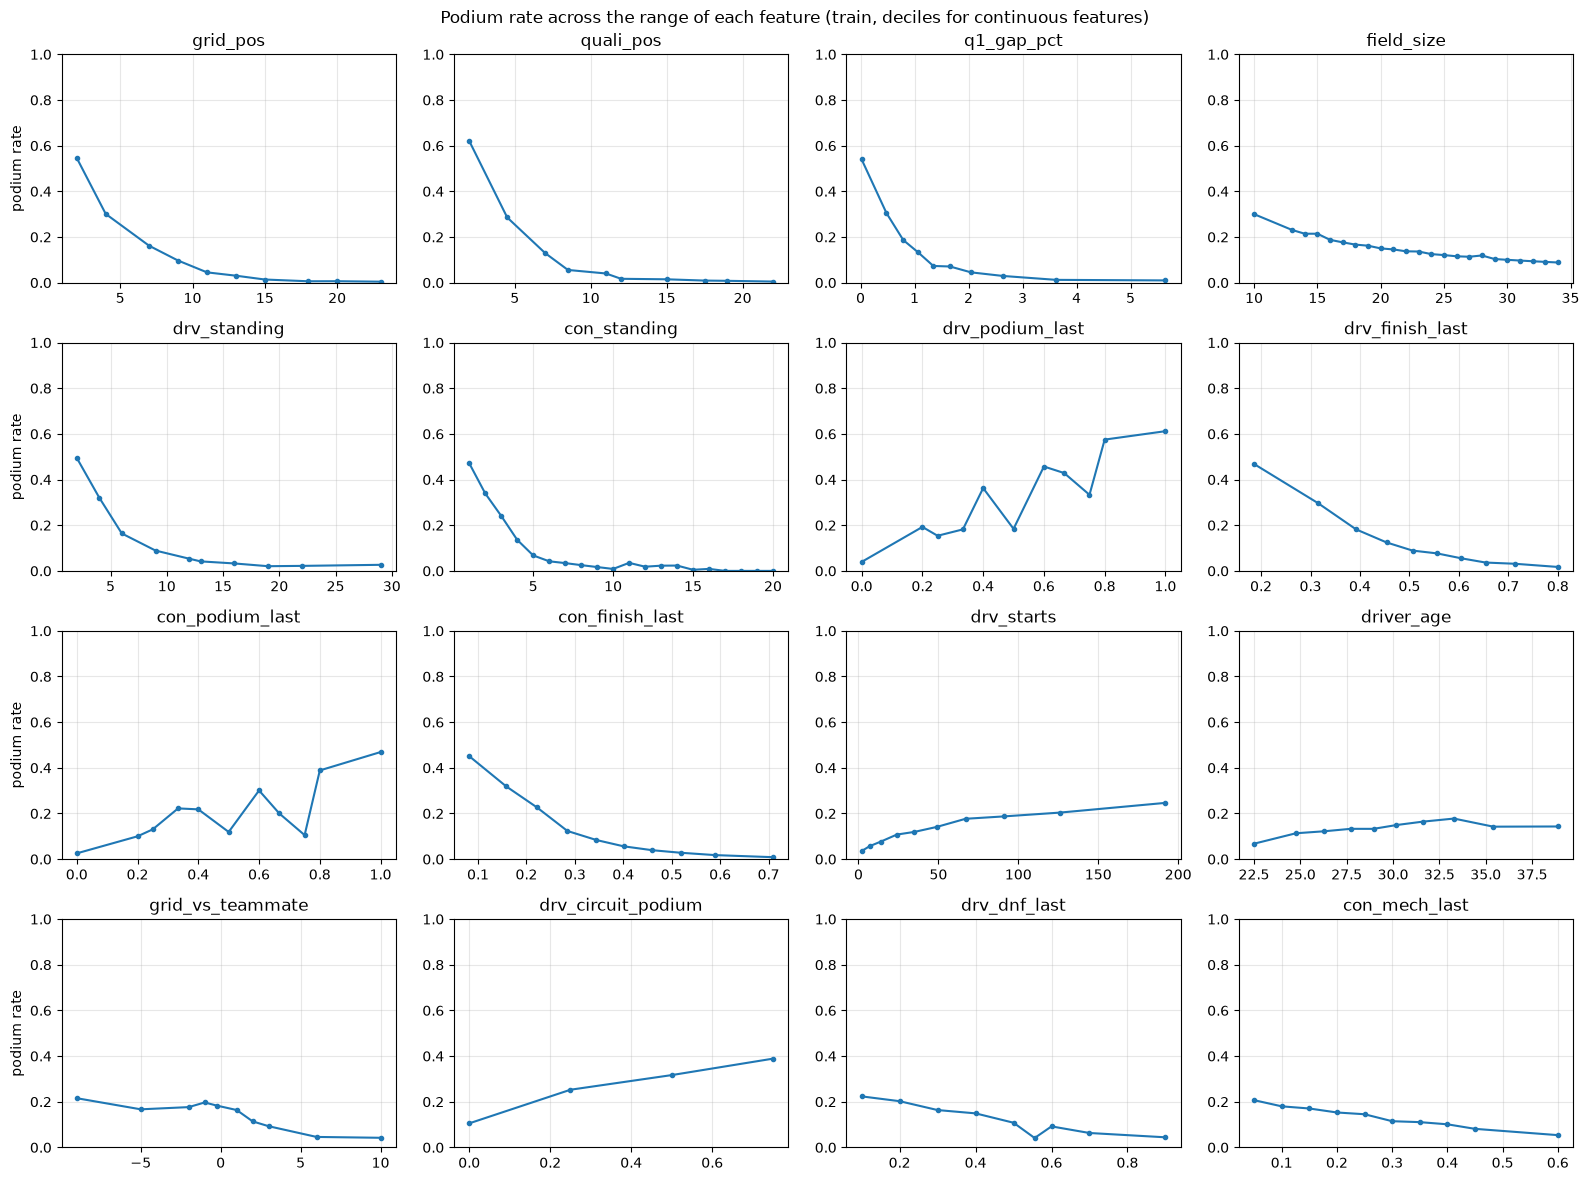

In [46]:
train_rows = features[features['split'] == 'train']
SHOW = ['grid_pos', 'quali_pos', 'q1_gap_pct', 'field_size', 'drv_standing', 'con_standing',
        'drv_podium_last', 'drv_finish_last', 'con_podium_last', 'con_finish_last', 'drv_starts', 'driver_age',
        'grid_vs_teammate', 'drv_circuit_podium', 'drv_dnf_last', 'con_mech_last']
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), SHOW):
    d = train_rows[[col, 'podium']].dropna()
    if d[col].nunique() > 25:
        decile = pd.qcut(d[col], 10, labels=False, duplicates='drop')
        rate = d.groupby(decile)['podium'].mean()
        x = d.groupby(decile)[col].median()
    else:
        rate = d.groupby(col)['podium'].mean()
        x = rate.index.to_series()
    ax.plot(x, rate.to_numpy(), marker='o', ms=3)
    ax.set_title(col)
    ax.set_ylim(0, 1)
for ax in axes[:, 0]:
    ax.set_ylabel('podium rate')
plt.suptitle('Podium rate across the range of each feature (train, deciles for continuous features)')
plt.tight_layout()
save_fig('feature_effects')
plt.show()

In [47]:
def univariate_auc(rows, col):
    d = rows[[col, 'podium']].dropna()
    auc = roc_auc_score(d['podium'], d[col])
    return max(auc, 1 - auc), ('higher = more podiums' if auc >= 0.5 else 'lower = more podiums')


evidence = []
for c in ALL_FEATURES:
    auc, direction = univariate_auc(train_rows, c)
    evidence.append({'feature': c, 'ROC-AUC alone': auc, 'direction': direction, 'coverage (train)': train_rows[c].notna().mean()})
pd.DataFrame(evidence).set_index('feature').sort_values('ROC-AUC alone', ascending=False).round(3)

,ROC-AUC alone,direction,coverage (train)
feature,,,
quali_pos,0.906,lower = more podiums,0.369
best_gap_pct,0.887,lower = more podiums,0.363
grid_pos,0.884,lower = more podiums,1.000
drv_standing,0.837,lower = more podiums,0.875
con_points_share,0.837,higher = more podiums,0.875
drv_points_share,0.831,higher = more podiums,0.875
q1_gap_pct,0.830,lower = more podiums,0.363
con_standing,0.829,lower = more podiums,0.875
con_podium_last,0.818,higher = more podiums,0.988


`ROC-AUC alone` ranks the training rows by one feature at a time (0.5 = no signal, 1 = perfect). Qualifying position, the best-session qualifying gap and grid position are the strongest single signals (0.91, 0.89 and 0.88), then standings, the Q1 gap and team form (0.82–0.84), then driver form (0.79–0.81). The three added groups are weak on their own: circuit history 0.67–0.71, reliability 0.62–0.64, teammate 0.57–0.63. `drv_starts` is weak (0.66), and `driver_age`, `field_size`, `grid_minus_quali`, `home` and `pit_lane_start` carry almost no signal on their own (≤ 0.56). The plots show why `driver_age` is weak: the podium rate rises until the early thirties and then falls, so higher or lower age alone does not rank drivers. Note that the qualifying features are only observed for 37% of the training rows (section 4.3).

### 8.2 Redundancy

Pairs of features that carry almost the same information (Spearman |ρ| ≥ 0.9 on train):

In [48]:
rho = train_rows[ALL_FEATURES].corr(method='spearman').abs()
pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
pairs[pairs >= 0.9].sort_values(ascending=False).round(3).rename('|spearman|').to_frame()

,,|spearman|
grid_pos,quali_pos,0.976
drv_points_share,drv_points,0.933
con_standing,con_points_share,0.924
drv_standing,drv_points_share,0.921


- `grid_pos` / `quali_pos` (0.98): we keep both on purpose. They differ exactly when a penalty moves a driver (section 4.3, question 1), and that difference is information.
- `drv_standing` / `drv_points_share` / `drv_points` and the constructor equivalents: the same quantity in different units. 8.3 chooses one.
- `grid_minus_quali` is `grid_pos − quali_pos` by construction, so with both of those kept it adds nothing new. We drop it.

### 8.3 Trials

**Qualifying pace: which time?** `q1_gap_pct` uses Q1, the only session every driver runs. Since 2006 the front-runners set their fastest laps in Q3, so the gap to the best time of any session (`best_gap_pct`) could measure pace at the front more precisely; but times from different sessions are set on a track that keeps getting faster, so they are not strictly comparable. Base features for this trial: the grid group and `quali_pos`.

In [49]:
GRID_AND_QUALI = ['grid_pos', 'pit_lane_start', 'quali_pos']
compare({
    'q1 gap (every driver, same session)': score_windows(features, GRID_AND_QUALI + ['q1_gap_pct']),
    'best-session gap': score_windows(features, GRID_AND_QUALI + ['best_gap_pct']),
    'both': score_windows(features, GRID_AND_QUALI + ['q1_gap_pct', 'best_gap_pct']),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"q1 gap (every driver, same session)",0.7354,0.7307,0.6810,0.7157,0.9287,0.0000,reference
best-session gap,0.7352,0.7237,0.6632,0.7074,0.9295,-0.0083,0/3
both,0.7312,0.7260,0.6475,0.7016,0.9297,-0.0141,0/3


The Q1 gap is better: the best-session gap scores 0.008 lower (worse in all three windows, beyond the noise level), and using both is worse still (−0.014). On its own the best-session gap is the stronger feature (ROC-AUC 0.887 against 0.830, 8.1), but it mostly repeats the qualifying order that `quali_pos` already gives; the Q1 gap adds how *far* behind a driver was, measured in one session for everyone. **Decision: `q1_gap_pct`.**

**Standings: which representation?** The points system changed several times (a win was worth 8–10 points before 2010 and 25 after), so raw points are not comparable across seasons. Base features for this trial: grid + qualifying.

In [50]:
BASE = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct']
compare({
    'standing position': score_windows(features, BASE + ['drv_standing', 'con_standing']),
    'raw points': score_windows(features, BASE + ['drv_points', 'con_points']),
    'points share': score_windows(features, BASE + ['drv_points_share', 'con_points_share']),
    'position + share + wins': score_windows(features, BASE + ['drv_standing', 'con_standing', 'drv_points_share', 'con_points_share', 'drv_wins']),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
standing position,0.7512,0.7164,0.7118,0.7265,0.9356,0.0000,reference
raw points,0.7129,0.6822,0.7080,0.7010,0.9293,-0.0255,0/3
points share,0.7469,0.7094,0.7177,0.7246,0.9356,-0.0019,1/3
position + share + wins,0.7489,0.7132,0.7286,0.7302,0.9364,0.0037,1/3


Raw points are worse in every window (−0.026, far beyond the noise), which confirms the scale problem. Points share alone and position + share + wins are within the noise of the position (−0.002 and +0.004, better in 1 of 3 windows), so they are ties. **Decision: standing position** (`drv_standing`, `con_standing`), the simplest scale-free option.

**What if the standings were not shifted?** Using the standings *after* the race (the leak 6.1 warns about):

In [51]:
drv_after_race = clean['driver_standings'][KEY + ['position']].rename(columns={'position': 'drv_standing'})
con_after_race = clean['constructor_standings'][['raceId', 'constructorId', 'position']].rename(columns={'position': 'con_standing'})
leaky = (features.drop(columns=['drv_standing', 'con_standing'])
         .merge(drv_after_race, on=KEY, how='left')
         .merge(con_after_race, on=['raceId', 'constructorId'], how='left'))
compare({
    'standings before the race (correct)': score_windows(features, BASE + ['drv_standing', 'con_standing']),
    'standings after the race (leak)': score_windows(leaky, BASE + ['drv_standing', 'con_standing']),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
standings before the race (correct),0.7512,0.7164,0.7118,0.7265,0.9356,0.0000,reference
standings after the race (leak),0.7816,0.7721,0.7713,0.7750,0.9519,0.0485,3/3


The leaky version scores higher in every window (+0.048 mean PR-AUC). A leak looks like an improvement, which is why leakage is ruled out by the screen in 6.1 and the checks in 6.3 and never by the score.

**Form window.** How many past races should the form features average? The same candidate feature set, with `n` changed:

In [52]:
form_tables = {n: build_features(starters, n_form=n) for n in [3, 5, 10, 20]}
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    display(compare({f'{label}, last {n} races': score_windows(table, CANDIDATES, model) for n, table in form_tables.items()}))

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, last 3 races",0.7472,0.7164,0.7153,0.7263,0.9369,0.0000,reference
"LR, last 5 races",0.7389,0.6977,0.7224,0.7197,0.9375,-0.0066,1/3
"LR, last 10 races",0.7250,0.7129,0.7251,0.7210,0.9394,-0.0053,1/3
"LR, last 20 races",0.7270,0.7150,0.7396,0.7272,0.9403,0.0009,1/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, last 3 races",0.7435,0.7420,0.6743,0.7199,0.9327,0.0000,reference
"HGB, last 5 races",0.7367,0.7264,0.6898,0.7177,0.9345,-0.0022,1/3
"HGB, last 10 races",0.7610,0.7258,0.6918,0.7262,0.9379,0.0063,2/3
"HGB, last 20 races",0.7083,0.7115,0.7275,0.7157,0.9350,-0.0042,1/3


No window length beats the last 3 races by more than the noise level: the best alternatives are 20 races for LR (+0.001) and 10 races for the tree model (+0.006, below its noise level of 0.011). The last 3 races do beat the last 5 for LR (+0.007 in 2 of 3 windows). Apart from that the window length is a **tie**.

How much each window length overlaps with the season-to-date standings and the career podium rate (Spearman |ρ| on train):

In [53]:
overlap = {}
for n, form_table in form_tables.items():
    tr = form_table[form_table['year'] <= 2019]
    overlap[f'last {n} races'] = {
        'drv_podium_last vs drv_career_podium': tr['drv_podium_last'].corr(tr['drv_career_podium'], method='spearman'),
        'drv_podium_last vs drv_standing': abs(tr['drv_podium_last'].corr(tr['drv_standing'], method='spearman')),
        'con_podium_last vs con_standing': abs(tr['con_podium_last'].corr(tr['con_standing'], method='spearman')),
    }
pd.DataFrame(overlap).round(3)

,last 3 races,last 5 races,last 10 races,last 20 races
drv_podium_last vs drv_career_podium,0.618,0.693,0.783,0.863
drv_podium_last vs drv_standing,0.686,0.730,0.746,0.726
con_podium_last vs con_standing,0.764,0.798,0.811,0.788


The longer the window, the more `drv_podium_last` repeats what the career podium rate and the standings already say (|ρ| with the career rate 0.62 for 3 races, 0.86 for 20). **Decision: the last 3 races.** It is never beaten, and it adds the most information the other features do not already have (recent changes such as an upgrade or a new car).

**Feature groups, added one at a time (forward selection).** We start from the grid group and try the next group on top of the groups kept so far. A group is kept if it passes the decision rule (7.1, including the noise level) for at least one of the two models: the models in sections 11–12 are of both kinds, and a group that only helps a non-linear model is still useful there. The order is computed, not chosen: groups are tried from the strongest to the weakest best single feature (ROC-AUC alone on the training rows, as in 8.1, with the final 3-race form window).

In [54]:
N_FORM_FINAL = 3
features = build_features(starters, n_form=N_FORM_FINAL)
features['split'] = split_of(features['year'])
check_no_leakage(features, starters, n_form=N_FORM_FINAL)
CANDIDATE_GROUPS = {
    'grid': ['grid_pos', 'pit_lane_start'],
    'qualifying': ['quali_pos', 'q1_gap_pct'],
    'standings': ['drv_standing', 'con_standing'],
    'driver form': ['drv_podium_last', 'drv_finish_last', 'drv_career_podium'],
    'constructor form': ['con_podium_last', 'con_finish_last'],
    'teammate': ['grid_vs_teammate', 'q1_gap_vs_teammate'],
    'circuit history': ['drv_circuit_podium', 'con_circuit_podium'],
    'reliability': ['drv_dnf_last', 'con_mech_last'],
    'experience': ['drv_starts', 'driver_age'],
    'context': ['field_size'],
    'home': ['home'],
}
final_train = features[features['split'] == 'train']
group_strength = pd.Series({g: max(univariate_auc(final_train, c)[0] for c in cols)
                            for g, cols in CANDIDATE_GROUPS.items() if g != 'grid'}).sort_values(ascending=False)
GROUP_ORDER = {'grid': CANDIDATE_GROUPS['grid']} | {g: CANDIDATE_GROUPS[g] for g in group_strength.index}
print('Order tried (best single-feature ROC-AUC on train):', group_strength.round(3).to_dict())
MODELS = {'LR': make_lr, 'HGB': make_hgb}
kept = ['grid']
current = {label: score_windows(features, GROUP_ORDER['grid'], model) for label, model in MODELS.items()}
selection = []
for group, cols in list(GROUP_ORDER.items())[1:]:
    base_cols = [c for g in kept for c in GROUP_ORDER[g]]
    new = {label: score_windows(features, base_cols + cols, model) for label, model in MODELS.items()}
    keep_group = any(passes(new[label], current[label], NOISE[label]) for label in MODELS)
    selection.append({
        'group tried': group,
        'LR before': current['LR']['mean PR-AUC'], 'LR with group': new['LR']['mean PR-AUC'],
        'LR better windows': f"{windows_won(new['LR'], current['LR'])}/3",
        'HGB before': current['HGB']['mean PR-AUC'], 'HGB with group': new['HGB']['mean PR-AUC'],
        'HGB better windows': f"{windows_won(new['HGB'], current['HGB'])}/3",
        'kept': keep_group,
    })
    if keep_group:
        kept.append(group)
        current = new
pd.DataFrame(selection).set_index('group tried').round(4)

Leakage checks passed (form window = 3 races)
Order tried (best single-feature ROC-AUC on train): {'qualifying': 0.906, 'standings': 0.837, 'constructor form': 0.808, 'driver form': 0.808, 'circuit history': 0.714, 'experience': 0.661, 'reliability': 0.64, 'teammate': 0.626, 'context': 0.544, 'home': 0.507}


,LR before,LR with group,LR better windows,HGB before,HGB with group,HGB better windows,kept
group tried,,,,,,,
qualifying,0.6782,0.7157,3/3,0.6783,0.6666,1/3,True
standings,0.7157,0.7265,2/3,0.6666,0.7151,3/3,True
constructor form,0.7265,0.7301,2/3,0.7151,0.7281,2/3,True
driver form,0.7301,0.7305,1/3,0.7281,0.7335,2/3,False
circuit history,0.7301,0.7273,2/3,0.7281,0.7195,1/3,False
experience,0.7301,0.7296,1/3,0.7281,0.6937,0/3,False
reliability,0.7301,0.7273,0/3,0.7281,0.7243,2/3,False
teammate,0.7301,0.7200,0/3,0.7281,0.7181,0/3,False
context,0.7301,0.7320,3/3,0.7281,0.7307,2/3,False


- The computed order tries constructor form before driver form (both 0.808 when rounded). Kept: **grid, qualifying, standings, constructor form**; once constructor form is in, driver form adds +0.0004 (LR) and +0.005 (tree model), below the noise level. (With scikit-learn 1.5 the forward selection keeps driver form here instead, see 7.1: the two groups are interchangeable at this step.)
- The three new groups are not kept, and each makes both models slightly worse: circuit history (LR −0.003, tree model −0.009), reliability (−0.003, −0.004), teammate (−0.010, −0.010). Experience (tree model −0.034), context and home also fail.
- The tree model gets *worse* when qualifying is added (−0.012): qualifying is missing for 63% of the training rows, so the tree partly learns which rows have qualifying data. The group is kept because it passes clearly for LR (+0.038 in all three windows), and the later groups lift the tree model above its grid-only score.

**Driver form or constructor form?** The two groups tie in the single-feature evidence (best ROC-AUC 0.808 each), so the order in which the forward selection tried them was decided by the third decimal, and the one tried first was kept while the other then added too little. We compare them head to head on top of grid, qualifying and standings:

In [55]:
def group_cols(groups):
    return [c for g in groups for c in GROUP_ORDER[g]]


FORM_OPTIONS = {'driver form': ['driver form'], 'constructor form': ['constructor form'], 'both': ['driver form', 'constructor form']}
for label, model in MODELS.items():
    display(compare({f'{label}, + {name}': score_windows(features, group_cols(['grid', 'qualifying', 'standings'] + groups), model)
                     for name, groups in FORM_OPTIONS.items()}))

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, + driver form",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"LR, + constructor form",0.7553,0.7260,0.7090,0.7301,0.9369,0.0006,2/3
"LR, + both",0.7428,0.7173,0.7313,0.7305,0.9380,0.0010,2/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, + driver form",0.7657,0.7402,0.7047,0.7369,0.9385,0.0000,reference
"HGB, + constructor form",0.7701,0.7225,0.6916,0.7281,0.9397,-0.0088,1/3
"HGB, + both",0.7579,0.7357,0.7068,0.7335,0.9408,-0.0034,1/3


For LR the three options are within 0.001 of each other. For the tree model driver form is best: constructor form instead is 0.009 lower and both together 0.003 lower, but both differences are below its noise level (0.011). The head-to-head is a tie, so the order-free check below decides.

**Does the order matter?** Forward selection depends on the order in which groups are tried, and the F1 introduction expects constructor form to matter (car performance dominates most eras). So we also check the other way round: start from all the candidate groups and remove one at a time. A group whose removal costs less than the noise level for both models adds nothing that the other groups do not already carry.

In [56]:
for label, model in MODELS.items():
    all_groups = list(GROUP_ORDER)
    display(compare({f'{label}, all groups': score_windows(features, group_cols(all_groups), model)} |
                    {f'{label}, all groups without {g}': score_windows(features, group_cols([a for a in all_groups if a != g]), model)
                     for g in all_groups}))

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, all groups",0.7257,0.7099,0.7302,0.7219,0.9390,0.0000,reference
"LR, all groups without grid",0.7185,0.6944,0.6998,0.7042,0.9356,-0.0177,0/3
"LR, all groups without qualifying",0.7358,0.7032,0.7253,0.7214,0.9376,-0.0005,1/3
"LR, all groups without standings",0.7324,0.7100,0.7293,0.7239,0.9386,0.0020,2/3
"LR, all groups without constructor form",0.7341,0.7086,0.7346,0.7258,0.9388,0.0039,2/3
"LR, all groups without driver form",0.7498,0.7002,0.7216,0.7239,0.9383,0.0020,1/3
"LR, all groups without circuit history",0.7382,0.7096,0.7351,0.7277,0.9387,0.0058,2/3
"LR, all groups without experience",0.7259,0.7109,0.7293,0.7220,0.9387,0.0001,2/3
"LR, all groups without reliability",0.7248,0.7097,0.7312,0.7219,0.9387,0.0000,1/3
"LR, all groups without teammate",0.7348,0.7159,0.7314,0.7274,0.9386,0.0055,3/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, all groups",0.7417,0.7270,0.6934,0.7207,0.9340,0.0000,reference
"HGB, all groups without grid",0.7169,0.7010,0.7004,0.7061,0.9340,-0.0146,1/3
"HGB, all groups without qualifying",0.7344,0.7159,0.7009,0.7171,0.9329,-0.0036,1/3
"HGB, all groups without standings",0.7492,0.7244,0.6834,0.7190,0.9335,-0.0017,1/3
"HGB, all groups without constructor form",0.7441,0.7082,0.7147,0.7223,0.9329,0.0016,2/3
"HGB, all groups without driver form",0.7125,0.7074,0.6997,0.7066,0.9335,-0.0141,1/3
"HGB, all groups without circuit history",0.7334,0.7397,0.7045,0.7259,0.9343,0.0052,2/3
"HGB, all groups without experience",0.7393,0.7378,0.7062,0.7278,0.9396,0.0071,2/3
"HGB, all groups without reliability",0.7440,0.7455,0.7091,0.7329,0.9342,0.0122,3/3
"HGB, all groups without teammate",0.7455,0.7341,0.6976,0.7257,0.9353,0.0050,3/3


- **All eleven groups together score lower than the four selected groups** (LR 0.722 and tree model 0.721, against 0.730 and 0.737 below): the extra groups add noise, not information.
- **Driver form carries information no other group has:** removing it costs the tree model 0.014, beyond its noise level. **Constructor form does not:** removing it changes the score by +0.004 (LR) and +0.002 (tree model); the team's strength reaches the model through `con_standing`. This breaks the tie above: **driver form is kept, constructor form is not.**
- The grid is needed (LR −0.018, tree model −0.015 without it). Removing circuit history, reliability, teammate, experience or home *improves* the tree model by 0.005–0.012, and removing circuit history or teammate improves LR by 0.006, beyond its noise level: these groups hurt, consistent with dropping them.
- Qualifying, standings and driver form overlap: all three describe how fast the driver and the car currently are, so removing one of them costs little while the others are present.

**Decision: grid, qualifying, standings, driver form.** The check below removes one group at a time from this final set.

In [57]:
kept = ['grid', 'qualifying', 'standings', 'driver form']    # the decision above
for label, model in MODELS.items():
    display(compare({f'{label}, selected groups': score_windows(features, group_cols(kept), model)} |
                    {f'{label}, selected without {g}': score_windows(features, group_cols([k for k in kept if k != g]), model)
                     for g in kept}))

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, selected groups",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"LR, selected without grid",0.7103,0.6866,0.7214,0.7061,0.9356,-0.0234,0/3
"LR, selected without qualifying",0.7406,0.7091,0.7279,0.7258,0.9358,-0.0037,1/3
"LR, selected without standings",0.7414,0.7175,0.7265,0.7285,0.9357,-0.0010,2/3
"LR, selected without driver form",0.7512,0.7164,0.7118,0.7265,0.9356,-0.0030,2/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, selected groups",0.7657,0.7402,0.7047,0.7369,0.9385,0.0000,reference
"HGB, selected without grid",0.7345,0.7170,0.7151,0.7222,0.9356,-0.0147,1/3
"HGB, selected without qualifying",0.7696,0.7325,0.7186,0.7403,0.9380,0.0034,2/3
"HGB, selected without standings",0.7468,0.7537,0.7016,0.7340,0.9375,-0.0029,1/3
"HGB, selected without driver form",0.7379,0.6979,0.7096,0.7151,0.9364,-0.0218,1/3


In the selected set the grid matters most (LR −0.023, tree model −0.015 without it) and the tree model needs driver form (−0.022). Qualifying is the weakest: without it LR loses 0.004 (below its noise level) and the tree model gains 0.003, because once standings and form are in, qualifying adds little to these two trial models (added to the grid alone it gave the largest gain, +0.038). We keep it: the brief asks for leakage-safe qualifying features in the modeling table, it is the only feature measuring pace in the race weekend itself (standings and form describe earlier races), and the ablation in section 14 measures it again with the final, tuned models. This is recorded as an open point for section 14.

**Training window.** Qualifying data only exist from 1994 and are complete from 2003. Should the model learn only from seasons where the qualifying features are observed, or from all seasons with those features imputed?

In [58]:
FEATURE_GROUPS = {g: GROUP_ORDER[g] for g in kept}
SELECTED = [c for cols in FEATURE_GROUPS.values() for c in cols]
FORM_FINAL = [c for g in ['driver form', 'constructor form'] for c in FEATURE_GROUPS.get(g, [])]
print('Selected groups:', kept)
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    display(compare({f'{label}, from {start} ({features["year"].between(start, 2019).sum():,} train rows)':
                     score_windows(features, SELECTED, model, start=start) for start in [1950, 1981, 1994, 2003, 2010]}))

Selected groups: ['grid', 'qualifying', 'standings', 'driver form']


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, from 1950 (22,589 train rows)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"LR, from 1981 (15,415 train rows)",0.7360,0.7088,0.7329,0.7259,0.9378,-0.0036,0/3
"LR, from 1994 (10,165 train rows)",0.7340,0.7047,0.7267,0.7218,0.9379,-0.0077,0/3
"LR, from 2003 (6,821 train rows)",0.7266,0.7031,0.7339,0.7212,0.9391,-0.0083,1/3
"LR, from 2010 (4,288 train rows)",0.7292,0.7052,0.7212,0.7185,0.9388,-0.0110,0/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, from 1950 (22,589 train rows)",0.7657,0.7402,0.7047,0.7369,0.9385,0.0000,reference
"HGB, from 1981 (15,415 train rows)",0.7494,0.7254,0.7137,0.7295,0.9365,-0.0074,1/3
"HGB, from 1994 (10,165 train rows)",0.7334,0.6975,0.7009,0.7106,0.9346,-0.0263,0/3
"HGB, from 2003 (6,821 train rows)",0.6787,0.7118,0.6907,0.6937,0.9308,-0.0432,0/3
"HGB, from 2010 (4,288 train rows)",0.6366,0.5912,0.7129,0.6469,0.9229,-0.0900,1/3


Every shorter window scores lower for both models, and starting from 1994 or later is worse by more than the noise level (LR −0.008 to −0.011, tree model −0.026 to −0.090). The old seasons still teach how grid, standings and form relate to the podium, and the missing-value indicators let the model treat the imputed qualifying values separately. **Decision: train on all seasons, 1950–2019.**

**Which entries to remove: model check of 3.4.** Section 3.4 removed every entry with no grid slot and no completed lap (1,563 rows: 1,346 `F`, 202 `W`, 15 `E`/`D`/`R`). Of these status letters only `F` (failed to qualify) is decided before the race; the others are recorded with the result. We compare three populations. Each table is built from scratch (features included) and the model is trained on it; the first comparison scores every option on the same validation rows (the starters), the second shows what each option would report on its own rows.

In [59]:
POPULATIONS = {
    'no grid slot and no lap removed (chosen)': entries[started & ~is_indy],
    'only F removed': entries[(entries['positionText'] != 'F') & ~is_indy],
    'nothing removed': entries[~is_indy],
}
population_tables = {name: build_features(rows.sort_values(['date', 'raceId', 'positionOrder']), n_form=N_FORM_FINAL)
                     for name, rows in POPULATIONS.items()}
starter_keys = starters.set_index(KEY).index
for label, model in MODELS.items():
    display(compare({f'{label}, trained on: {name}': score_windows(t, SELECTED, model, eval_data=t[t.set_index(KEY).index.isin(starter_keys)])
                     for name, t in population_tables.items()}))
own_rows = {name: score_windows(t, SELECTED) for name, t in population_tables.items()}
pd.DataFrame({name: {'rows': len(t), 'podium share': t['podium'].mean(), 'rows with pit_lane_start = 1': t['pit_lane_start'].sum(),
                     'LR mean PR-AUC': own_rows[name]['mean PR-AUC'], 'LR mean ROC-AUC': own_rows[name]['mean ROC-AUC']}
              for name, t in population_tables.items()}).T.round(4)

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, trained on: no grid slot and no lap removed (chosen)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"LR, trained on: only F removed",0.7383,0.7153,0.7342,0.7292,0.9376,-0.0003,1/3
"LR, trained on: nothing removed",0.7395,0.7171,0.7325,0.7297,0.9376,0.0002,2/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, trained on: no grid slot and no lap removed (chosen)",0.7657,0.7402,0.7047,0.7369,0.9385,0.0000,reference
"HGB, trained on: only F removed",0.7524,0.7265,0.7202,0.7330,0.9394,-0.0039,1/3
"HGB, trained on: nothing removed",0.7284,0.7278,0.7075,0.7212,0.9365,-0.0157,1/3


,rows,podium share,rows with pit_lane_start = 1,LR mean PR-AUC,LR mean ROC-AUC
no grid slot and no lap removed (chosen),24724.0,0.1359,72.0,0.7295,0.9377
only F removed,24921.0,0.1348,289.0,0.7292,0.9377
nothing removed,26287.0,0.1278,1635.0,0.7297,0.9376


- **On the same validation rows**, removing only `F` ties with our rule for both models (LR −0.0003, tree model −0.004, both below the noise level). Removing nothing ties for LR (+0.0002) and is worse for the tree model (−0.016, beyond its noise level of 0.011).
- **On their own rows** the three options report almost the same score (LR 0.7292–0.7297): the validation seasons 2016–21 contain very few non-starters, so keeping them would not inflate these numbers either.
- **What differs is the data.** An entry with no grid slot has `grid = 0`, exactly like a pit-lane start. With only `F` removed, the 217 `W`/`E`/`D`/`R` entries that never started stay in and are flagged `pit_lane_start = 1` together with the 72 real pit-lane starts (table above), so most rows carrying that flag would be drivers who never raced.

**Decision: keep the rule from 3.4.** It scores at least as well as both alternatives on the same rows and keeps `pit_lane_start` meaning what it says. It uses no status letter, only the fact that the driver did not take the start, which is known before the lights go out: 1,553 of the removed entries never had a grid slot, and 10 qualified and then did not start (3.4).

### 8.4 Selected features

| Group | Feature | Evidence | Known before the start because |
| --- | --- | --- | --- |
| grid | `grid_pos` | strongest signal in every era (4.2); ROC-AUC alone 0.88 | the starting grid is fixed before the start |
| grid | `pit_lane_start` | needed to encode `grid = 0` (9.1) | pit-lane starts are on the starting list |
| qualifying | `quali_pos` | ROC-AUC alone 0.91; with `q1_gap_pct` +0.038 PR-AUC on top of the grid (LR) | qualifying ends before the race |
| qualifying | `q1_gap_pct` | ROC-AUC alone 0.83; measures pace, not only order | same |
| standings | `drv_standing`, `con_standing` | 0.84 / 0.83 alone; +0.011 (LR), +0.049 (tree model) | standings after the previous round (6.3 checks round 1 is empty) |
| driver form | `drv_podium_last`, `drv_finish_last`, `drv_career_podium` | 0.79–0.81 alone; +0.022 (tree model) | earlier races only (6.3 recomputes 300 rows by hand) |

Not used: `grid_minus_quali` (8.2), `best_gap_pct` and points share / raw points / wins (8.3), the constructor form, teammate, circuit-history, reliability, experience, `field_size` and `home` groups (8.3), sprint results (6.4).

## 9. Preprocessing

### 9.1 Trials

**Where the selected features are missing.** Per season, the share of starters with a missing value in each selected feature (the two grid features are complete). The shaded areas are the validation and test seasons. `q1_gap_pct` is dashed because it lies on top of `quali_pos` almost everywhere: the two differ only for drivers with a qualifying row but no `q1` time.

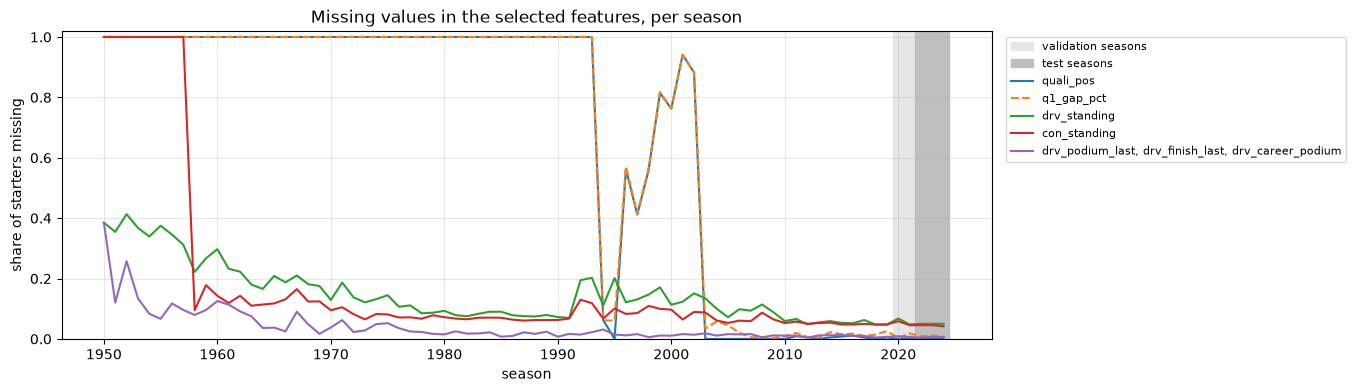

split,train,val,test
quali_pos,0.631,0.001,0.000
q1_gap_pct,0.637,0.012,0.010
drv_standing,0.125,0.056,0.050
con_standing,0.125,0.051,0.044
drv_podium_last,0.030,0.008,0.006
drv_finish_last,0.030,0.008,0.006
drv_career_podium,0.030,0.008,0.006


In [60]:
train_rows = features[features['split'] == 'train']
with_missing = [c for c in SELECTED if features[c].isna().any()]
missing_by_season = features.groupby('year')[with_missing].agg(lambda s: s.isna().mean())
same_pattern = {}    # features with an identical missing pattern share one line
for col in with_missing:
    twin = next((c for c in same_pattern if missing_by_season[c].equals(missing_by_season[col])), None)
    same_pattern.setdefault(twin or col, []).append(col)
fig, ax = plt.subplots(figsize=(12, 4))
ax.axvspan(2019.5, 2021.5, color='0.9', label='validation seasons')
ax.axvspan(2021.5, 2024.5, color='0.75', label='test seasons')
for col, cols in same_pattern.items():
    ax.plot(missing_by_season.index, missing_by_season[col], ls='--' if col == 'q1_gap_pct' else '-', label=', '.join(cols))
ax.set_ylim(0, 1.02)
ax.set_xlabel('season')
ax.set_ylabel('share of starters missing')
ax.set_title('Missing values in the selected features, per season')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
save_fig('feature_missingness')
plt.show()
features.groupby('split')[with_missing].agg(lambda s: s.isna().mean()).T[['train', 'val', 'test']].round(3)

- **Qualifying (`quali_pos`, `q1_gap_pct`):** missing for every starter before 1994 and for 41–94% of starters in 1996–2002 (the qualifying table is incomplete there, 4.3). From 2003 on it is complete, apart from drivers who set no `q1` time (at most 6% in a season). Validation and test: complete for `quali_pos`, 1% for `q1_gap_pct`.
- **`con_standing`:** missing for every starter in 1950–1957, because the Constructors' Championship only began in 1958. After that only at round 1 and in a team's first race of a season (4–18% per season).
- **`drv_standing`:** missing at round 1 and in a driver's first race of a season: 31–41% per season in 1950–1957 (many one-off entrants), 5–30% afterwards.
- **Driver form (three features):** missing only for a driver's first start (up to 39% of starters in a 1950s season, at most 3% since 1994).

**What we do:** no row and no feature is dropped. Every missing value is filled inside the model pipeline, fitted on the training rows only, and a 0/1 indicator column records which values were filled. In validation and test almost nothing is missing (table above), so the imputation mainly decides how the model learns from the old seasons.

The trials below decide *how* to fill these values. Every option is fitted on the training rows of each window only.

In [61]:
def make_lr_with(imputer=None, scaler=None):
    # the trial logistic regression with another imputer and/or scaler ('passthrough' = no scaling)
    imputer = SimpleImputer(strategy='median', add_indicator=True) if imputer is None else imputer
    scaler = StandardScaler() if scaler is None else scaler
    return lambda: make_pipeline(imputer, scaler, LogisticRegression(max_iter=2000))


domain = features.copy()
domain['quali_pos'] = domain['quali_pos'].fillna(domain['grid_pos'])   # no qualifying row: use the grid slot
complete_rows = features.dropna(subset=SELECTED)
print(f'Training rows (<= 2019) with no missing feature: {complete_rows["year"].le(2019).sum():,} of {features["year"].le(2019).sum():,}')
compare({
    'median + missing indicators': score_windows(features, SELECTED, make_lr),
    'mean + missing indicators': score_windows(features, SELECTED, make_lr_with(SimpleImputer(strategy='mean', add_indicator=True))),
    'median only': score_windows(features, SELECTED, make_lr_with(SimpleImputer(strategy='median'))),
    'mean only': score_windows(features, SELECTED, make_lr_with(SimpleImputer(strategy='mean'))),
    'model-based (iterative) + missing indicators': score_windows(
        features, SELECTED, make_lr_with(IterativeImputer(add_indicator=True, max_iter=30, random_state=SEED))),
    'quali_pos <- grid, then median + indicators': score_windows(domain, SELECTED, make_lr),
    'drop training rows with a missing value': score_windows(complete_rows, SELECTED, eval_data=features),
})

Training rows (<= 2019) with no missing feature: 7,384 of 22,589


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
median + missing indicators,0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
mean + missing indicators,0.7390,0.7155,0.7338,0.7294,0.9377,-0.0001,1/3
median only,0.7364,0.7066,0.7260,0.7230,0.9352,-0.0065,0/3
mean only,0.7368,0.7105,0.7264,0.7246,0.9350,-0.0049,0/3
model-based (iterative) + missing indicators,0.7390,0.7186,0.7295,0.7290,0.9376,-0.0005,1/3
"quali_pos <- grid, then median + indicators",0.7331,0.7089,0.7210,0.7210,0.9360,-0.0085,0/3
drop training rows with a missing value,0.7248,0.6961,0.7265,0.7158,0.9350,-0.0137,0/3


- **Imputation method.** The missing indicators matter: without them (median only) the mean PR-AUC drops by 0.007, beyond the noise level and in all three windows. Median or mean does not: with indicators the mean scores −0.0001 (better in 1 of 3 windows), and without indicators it is 0.002 ahead of the median, both within the noise level. We keep the median because the long tails (`drv_standing` up to 102, `q1_gap_pct` up to 33%) do not pull it. The model-based (iterative) imputer, which predicts each missing value from the other features, also ties (−0.0005, better in 1 of 3 windows), so we keep the simpler median. Filling `quali_pos` with the grid slot is worse (−0.009, all three windows): it makes 63% of the training rows look as if qualifying matched the grid exactly, and hides that there was no qualifying data.
- **Dropping instead of imputing** is clearly worse (−0.014, worse in all three windows). Only 7,384 of the 22,589 training rows have no missing value, so dropping throws away two thirds of the training data, including every season before 1994, and rows with missing values still have to be handled at prediction time. Dropping the incomplete *columns* instead would remove the qualifying, standings and driver-form groups, each of which was selected in 8.3.

**Decision: median + missing indicators.**

**Outliers in `q1_gap_pct`.** After removing the impossible time (3.1), the gap still has a long right tail (a few drivers with problems in qualifying):

In [62]:
print(train_rows['q1_gap_pct'].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_dict())
cap = train_rows['q1_gap_pct'].quantile(0.99)
clipped = features.assign(q1_gap_pct=features['q1_gap_pct'].clip(upper=cap))
logged = features.assign(q1_gap_pct=np.log1p(features['q1_gap_pct']))
compare({
    'no change': score_windows(features, SELECTED),
    f'clip at the train 99th percentile ({cap:.1f}%)': score_windows(clipped, SELECTED),
    'log(1 + gap)': score_windows(logged, SELECTED),
})

{'count': 8209.0, 'mean': 2.02, 'std': 2.0, 'min': 0.0, '50%': 1.5, '90%': 4.4, '99%': 8.99, 'max': 33.29}


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
no change,0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
clip at the train 99th percentile (9.0%),0.7407,0.7158,0.7317,0.7294,0.9378,-0.0001,2/3
log(1 + gap),0.7429,0.7138,0.7246,0.7271,0.9377,-0.0024,1/3


Neither clipping nor the log transform changes the score by more than the noise (−0.0001 and −0.002). After the one impossible time was removed, the tail is genuine (slow cars, problems in qualifying). It is a tie, so **no transformation**: one step fewer to explain and to apply at inference.

**Pit-lane starts.** `grid = 0` cannot stay 0: it would put the driver ahead of pole position.

In [63]:
compare({
    'back of the field + flag (chosen)': score_windows(features, SELECTED),
    'grid 0 kept as 0 + flag': score_windows(features.assign(grid_pos=features['grid']), SELECTED),
    'missing (imputed) + flag': score_windows(features.assign(grid_pos=features['grid'].where(features['grid'] > 0)), SELECTED),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
back of the field + flag (chosen),0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
grid 0 kept as 0 + flag,0.7389,0.7156,0.7334,0.7293,0.9377,-0.0002,0/3
missing (imputed) + flag,0.7393,0.7157,0.7337,0.7296,0.9377,0.0001,1/3


The three encodings give the same score: there are only 72 pit-lane starts (0.3% of rows) and the flag carries the information. It is a tie, so we keep the encoding that matches what happens on track: a pit-lane starter starts behind everyone.

**Scaling.** Logistic regression (and the neural network in section 12) fit one weight per feature, and the features have very different ranges (`grid_pos` up to 34, the form rates between 0 and 1, `drv_standing` up to 102). Standard scaling (mean 0, standard deviation 1) is compared with min-max scaling (range 0–1), robust scaling (median and interquartile range, less sensitive to the long tails) and no scaling. Tree models split on one feature at a time and are not affected by any of these.

In [64]:
compare({
    'standard (chosen)': score_windows(features, SELECTED),
    'min-max': score_windows(features, SELECTED, make_lr_with(scaler=MinMaxScaler())),
    'robust': score_windows(features, SELECTED, make_lr_with(scaler=RobustScaler())),
    'none': score_windows(features, SELECTED, make_lr_with(scaler='passthrough')),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
standard (chosen),0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
min-max,0.7401,0.7142,0.7323,0.7289,0.9369,-0.0006,1/3
robust,0.7387,0.7153,0.7327,0.7289,0.9371,-0.0006,0/3
none,0.7389,0.7158,0.7329,0.7292,0.9371,-0.0003,1/3


All four options are within 0.0006 of each other: logistic regression with this solver copes with unscaled inputs, so scaling does not change its score here. It is a tie, so we keep standard scaling for reasons this score does not show: it puts every feature on the same scale for the regularization penalty of logistic regression, and the neural network in section 12 trains by gradient descent, which works best on inputs centred at 0 with comparable spread. **Decision: standard scaling.**

### 9.2 The preprocessing pipeline and its effect on the data

1. **Median imputation**, with a 0/1 indicator column for every feature that has missing values in train.
2. **Standard scaling** (subtract the train mean, divide by the train standard deviation). Logistic regression and neural networks need features on comparable scales; tree models are unaffected.

Both steps are fitted on the training rows only and then applied unchanged to validation and test.

In [65]:
def make_preprocessor():
    prep = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler())
    prep.set_output(transform='pandas')   # keep column names, e.g. missingindicator_quali_pos
    return prep


def transform_to_frame(prep, X):
    # output of a fitted preprocessor as a table, with its column names and the rows' index
    return pd.DataFrame(prep.transform(X), columns=prep.get_feature_names_out(), index=X.index)


prep = make_preprocessor().fit(train_rows[SELECTED])
Z_train = transform_to_frame(prep, train_rows[SELECTED])
print('Columns after preprocessing:', len(Z_train.columns), '| indicator columns:', [c for c in Z_train.columns if c.startswith('missingindicator')])

before_after = pd.DataFrame({
    'missing before': train_rows[SELECTED].isna().mean(),
    'min before': train_rows[SELECTED].min(), 'max before': train_rows[SELECTED].max(),
    'mean before': train_rows[SELECTED].mean(), 'std before': train_rows[SELECTED].std(),
    'missing after': Z_train[SELECTED].isna().mean(),
    'mean after': Z_train[SELECTED].mean(), 'std after': Z_train[SELECTED].std(),
})
before_after.round(2)

Columns after preprocessing: 16 | indicator columns: ['missingindicator_quali_pos', 'missingindicator_q1_gap_pct', 'missingindicator_drv_standing', 'missingindicator_con_standing', 'missingindicator_drv_podium_last', 'missingindicator_drv_finish_last', 'missingindicator_drv_career_podium']


,missing before,min before,max before,mean before,std before,missing after,mean after,std after
grid_pos,0.00,1.00,34.00,11.93,6.82,0.0,0.0,1.0
pit_lane_start,0.00,0.00,1.00,0.00,0.03,0.0,-0.0,1.0
quali_pos,0.63,1.00,26.00,11.37,6.36,0.0,-0.0,1.0
q1_gap_pct,0.64,0.00,33.29,2.02,2.00,0.0,0.0,1.0
drv_standing,0.12,1.00,102.00,13.08,9.17,0.0,-0.0,1.0
con_standing,0.13,1.00,20.00,6.17,3.70,0.0,-0.0,1.0
drv_podium_last,0.03,0.00,1.00,0.14,0.26,0.0,0.0,1.0
drv_finish_last,0.03,0.04,1.00,0.52,0.21,0.0,-0.0,1.0
drv_career_podium,0.03,0.00,1.00,0.12,0.16,0.0,0.0,1.0


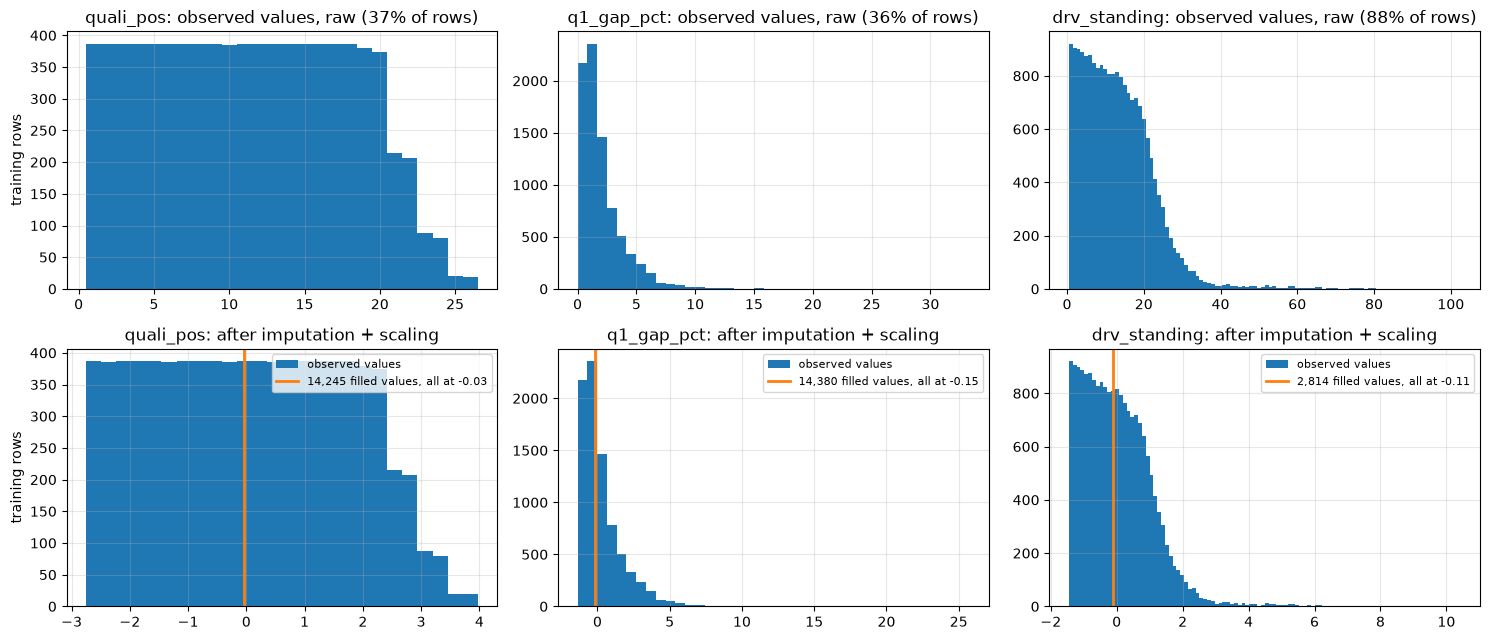

In [66]:
SHOW_PREP = ['quali_pos', 'q1_gap_pct', 'drv_standing']
scaler = prep.named_steps['standardscaler']
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for i, col in enumerate(SHOW_PREP):
    observed = train_rows[col].notna()
    values = train_rows.loc[observed, col]
    if (values % 1 == 0).all():    # whole numbers: one bin per value (equal-width bins would leave gaps)
        edges = np.arange(values.min() - 0.5, values.max() + 1.5)
    else:
        edges = np.linspace(values.min(), values.max(), 41)
    k = list(Z_train.columns).index(col)
    scaled_edges = (edges - scaler.mean_[k]) / scaler.scale_[k]    # the same bins, moved by the scaling
    filled_at = Z_train.loc[~observed, col].iloc[0]                 # every filled row has the same value

    axes[0, i].hist(values, bins=edges)
    axes[0, i].set_title(f'{col}: observed values, raw ({observed.mean():.0%} of rows)')
    axes[1, i].hist(Z_train.loc[observed, col], bins=scaled_edges, label='observed values')
    axes[1, i].axvline(filled_at, color='tab:orange', lw=2, label=f'{(~observed).sum():,} filled values, all at {filled_at:.2f}')
    axes[1, i].set_title(f'{col}: after imputation + scaling')
    axes[1, i].legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel('training rows')
plt.tight_layout()
save_fig('preprocessing_effect')
plt.show()

After preprocessing every feature has mean 0 and standard deviation 1, and no value is missing. Both rows of the figure use the same bins (one per whole number for `quali_pos` and `drv_standing`), moved by the scaling, so the blue shapes are identical: scaling is linear and does not change the shape of the observed values. Every filled row gets one and the same value, the training median after scaling (the orange line; the legend gives how many rows: 63% of training rows for `quali_pos` and `q1_gap_pct`, 12% for `drv_standing`). It is close to 0 but not exactly 0, because the scaler's mean is computed after the filling. The 7 indicator columns record which rows were filled, so a model can tell a real median value from a filled one.

### 9.3 Preprocessing-order experiments

Each experiment changes only the order (or scope) of one step and keeps everything else fixed: same rows, same features, same model, same validation windows.

**E1. Fit the imputer and scaler before or after splitting?** In the leaky order, the medians, means and standard deviations are computed on every row (train, validation and test) before splitting.

In [67]:
leaky_prep = make_preprocessor().fit(features[SELECTED])
leaky_table = pd.concat([features[['year', 'podium']], transform_to_frame(leaky_prep, features[SELECTED])], axis=1)
leaky_cols = [c for c in leaky_table.columns if c not in ('year', 'podium')]
compare({
    'split, then fit on train rows (correct)': score_windows(features, SELECTED),
    'fit on all rows, then split (leaky)': score_windows(leaky_table, leaky_cols, lambda: LogisticRegression(max_iter=2000)),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"split, then fit on train rows (correct)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"fit on all rows, then split (leaky)",0.7392,0.7162,0.7339,0.7298,0.9377,0.0003,3/3


The leaky order scores higher in all three windows, but by only +0.0003, a twentieth of the noise level. The training rows (22,589) outnumber the validation and test rows (2,135), so adding them barely moves a median or a standard deviation. The order still matters: the leaky version uses statistics from the seasons it is evaluated on, and with a smaller training set or drifting features the gain would be larger and fake. **Decision: split first, fit on train only.**

**E2. Impute then scale, or scale then impute?**

In [68]:
def make_lr_scale_first():
    return make_pipeline(StandardScaler(), SimpleImputer(strategy='median', add_indicator=True), LogisticRegression(max_iter=2000))


scale_first = make_pipeline(StandardScaler(), SimpleImputer(strategy='median', add_indicator=True)).fit(train_rows[SELECTED])
Z_scale_first = transform_to_frame(scale_first, train_rows[SELECTED])
display(pd.DataFrame({
    'impute -> scale: mean': Z_train[SELECTED].mean(), 'impute -> scale: std': Z_train[SELECTED].std(),
    'scale -> impute: mean': Z_scale_first[SELECTED].mean(), 'scale -> impute: std': Z_scale_first[SELECTED].std(),
}).loc[lambda t: t['impute -> scale: std'].round(3) != t['scale -> impute: std'].round(3)].round(3))
compare({
    'impute -> scale (chosen)': score_windows(features, SELECTED),
    'scale -> impute': score_windows(features, SELECTED, make_lr_scale_first),
})

,impute -> scale: mean,impute -> scale: std,scale -> impute: mean,scale -> impute: std
quali_pos,-0.0,1.0,-0.036,0.608
q1_gap_pct,0.0,1.0,-0.167,0.616
drv_standing,-0.0,1.0,-0.015,0.936
con_standing,-0.0,1.0,-0.006,0.935
drv_podium_last,0.0,1.0,-0.016,0.989
drv_finish_last,-0.0,1.0,0.002,0.985
drv_career_podium,0.0,1.0,-0.014,0.988


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
impute -> scale (chosen),0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
scale -> impute,0.7389,0.7155,0.7329,0.7291,0.9366,-0.0004,0/3


The scores are tied (−0.0004, slightly lower ROC-AUC for scale → impute). The order does change the data: scaling first computes the mean and standard deviation on the observed values only, and the imputed rows are then all placed at the scaled median, so `quali_pos` ends with standard deviation 0.61 instead of 1 and a mean that is not 0. **Decision: impute, then scale**, so every model input is exactly standardised.

**E3. Build the form features before or after removing the non-starters?** In section 3.4 the non-starters were removed *before* the features were built, so form only counts races the driver actually started. The other order builds form from every entry, so a failed qualification counts as a race without a podium and with a last-place finish.

In [69]:
all_entries = entries[~is_indy]
features_before_filter = build_features(starters, n_form=N_FORM_FINAL, history=all_entries)
changed = (features_before_filter[FORM_FINAL].round(6) != features[FORM_FINAL].round(6)) & features[FORM_FINAL].notna()
print('Share of rows whose form values change:', changed.any(axis=1).mean().round(3),
      '| before 1995:', changed.any(axis=1)[features['year'] < 1995].mean().round(3),
      '| 2016-2021:', changed.any(axis=1)[features['year'].between(2016, 2021)].mean().round(3))
compare({
    'filter, then build features (chosen)': score_windows(features, SELECTED),
    'build features, then filter': score_windows(features_before_filter, SELECTED),
})

Share of rows whose form values change: 0.554 | before 1995: 0.836 | 2016-2021: 0.188


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"filter, then build features (chosen)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"build features, then filter",0.7396,0.7172,0.7320,0.7296,0.9378,0.0001,2/3


The order changes the form values of 55% of the rows (84% before 1995, when many entries failed to qualify; 19% in 2016–21, because a non-starter also shifts the finishing percentile of everyone in that race), but the score does not move (+0.0001). It is a tie, decided by meaning: with the filter first, the form features describe races the driver actually started, which is what their names say. **Decision: filter, then build features.**

## 10. Hand-off to modeling

Everything sections 11–16 need is defined here. Those sections only read these names and never reassign them, so each section can be written and rerun on its own once Run All has reached this point. The modeling table is also written to `outputs/` (one row per driver–race, with the split and the selected features).

In [70]:
model_table = features[KEY + ['constructorId', 'circuitId', 'year', 'round', 'date', 'split', 'podium'] + SELECTED].copy()
model_table.to_csv(OUT_DIR / 'model_table.csv', index=False)
spec = {
    'target': 'podium',
    'features': SELECTED,
    'feature_groups': FEATURE_GROUPS,
    'form_window': N_FORM_FINAL,
    'split': {'train': '1950-2019', 'val': '2020-2021', 'test': '2022-2024'},
    'primary_metric': 'PR-AUC',
    'secondary_metric': 'ROC-AUC',
}
(OUT_DIR / 'feature_spec.json').write_text(json.dumps(spec, indent=2))

train = model_table[model_table['split'] == 'train']
val = model_table[model_table['split'] == 'val']
test = model_table[model_table['split'] == 'test']
X_train, y_train = train[SELECTED], train['podium']
X_val, y_val = val[SELECTED], val['podium']
X_test, y_test = test[SELECTED], test['podium']
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)
print('Feature groups:', FEATURE_GROUPS)

X_train (22589, 9) | X_val (779, 9) | X_test (1356, 9)
Feature groups: {'grid': ['grid_pos', 'pit_lane_start'], 'qualifying': ['quali_pos', 'q1_gap_pct'], 'standings': ['drv_standing', 'con_standing'], 'driver form': ['drv_podium_last', 'drv_finish_last', 'drv_career_podium']}


In [71]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'F1': f1_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred)}


def best_threshold(y_true, proba):
    # threshold with the highest F1; call it on validation rows only
    thresholds = np.arange(0.05, 0.951, 0.01)
    scores = [f1_score(y_true, (proba >= t).astype(int)) for t in thresholds]
    return round(float(thresholds[int(np.argmax(scores))]), 2)


models_to_compare = {}   # name -> fitted model; sections 11-12 add their final models, section 13 compares them

**Contract for sections 11–16**

| Name | What it is |
| --- | --- |
| `model_table` | one row per driver–race (starters, no Indianapolis 500), ids, `split`, target `podium`, selected features |
| `SELECTED`, `FEATURE_GROUPS` | the 9 selected features and their 4 groups (groups are the units of the ablation) |
| `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test` | raw feature values (with `NaN`), split by season |
| `make_preprocessor()` | median imputation + missing indicators + standard scaling; put it in a `Pipeline` with the model so it is fitted on train only and the inference function can take raw values |
| `evaluate(y, proba, threshold)` | ROC-AUC, PR-AUC, F1, precision, recall |
| `best_threshold(y_val, proba_val)` | F1-optimal threshold, chosen on validation |
| `make_lr()` | the logistic regression used for every data decision; a natural baseline |
| `models_to_compare` | each modeling section adds its final model (anything with `predict_proba` on the raw `X_*`); section 13 scores all of them the same way |

Rules: fit on train; choose hyperparameters and the threshold on validation; score the test set once, at the end (section 13). The brief asks for "all five metrics": its table lists ROC-AUC, PR-AUC and F1, and we add precision and recall, which explain the F1. Tree models do not need the scaler and can take `NaN` directly; keep the same rows and features so the scores stay comparable.

## 11. Baseline and statistical models

*To do.* A baseline, at least two statistical models (e.g. logistic regression, random forest, gradient boosting), hyperparameter tuning on validation, how each model works and its limitations, and performance on train and validation. At least three distinct modeling attempts in the notebook in total.

### 11.1 Logistic regression baseline

**How it works.** Logistic regression gives every input a weight and turns the weighted sum into a probability with the sigmoid, $P(\text{podium}) = 1 / (1 + e^{-(b + w \cdot x)})$. The weights are fitted by maximising the likelihood of the training labels, with a penalty on large weights (strength $1/C$; L2 shrinks all weights, L1 can set some to exactly zero). The inputs are the 9 selected features plus the 7 missing-value indicators from `make_preprocessor()` (median imputation and standard scaling, fitted on the training rows only).

**Limitations.**
- **Linear in each input.** One feature can only push the log-odds up or down by a fixed amount per unit. The jump in podium chances between grid 3 and grid 4 is bigger than between grid 13 and 14, and a straight line cannot show that.
- **No interactions.** The effect of the grid is the same whatever the standings or the form, unless such combinations are built by hand.
- **One set of weights for all eras.** The model is fitted on 1950–2019, but the link between grid and podium changed over the decades (section 4.2). The weights average over all those eras, and the 2022 ground-effect cars in the test set are a new one.

**Attempt 1: `make_lr()` as it is.** This is the model used for every data decision in sections 8–9 (C = 1, L2, no class weights). It is the baseline every other attempt is compared with. The threshold is the F1-optimal one on validation (`best_threshold`).

In [72]:
modeling_attempts = {}   # attempt -> validation metrics at its own validation threshold (collected in section 13)

lr_baseline = make_lr().fit(X_train, y_train)
proba_lr_base_val = lr_baseline.predict_proba(X_val)[:, 1]
lr_base_threshold = best_threshold(y_val, proba_lr_base_val)
modeling_attempts['1. LR, make_lr() as is'] = evaluate(y_val, proba_lr_base_val, lr_base_threshold) | {'threshold': lr_base_threshold}
print('Validation threshold (F1-optimal):', lr_base_threshold)
pd.DataFrame({'train': evaluate(y_train, lr_baseline.predict_proba(X_train)[:, 1], lr_base_threshold) | {'threshold': lr_base_threshold},
              'validation': modeling_attempts['1. LR, make_lr() as is']}).T.round(4)

Validation threshold (F1-optimal): 0.26


,ROC-AUC,PR-AUC,F1,precision,recall,threshold
train,0.8995,0.5681,0.5881,0.4935,0.7275,0.26
validation,0.9295,0.7337,0.7094,0.6351,0.8034,0.26


**Result.** The baseline ranks the validation podiums well: PR-AUC 0.734 against a base rate of 0.150, and ROC-AUC 0.930. At its F1-optimal threshold of 0.26 it finds 80% of the podiums (recall 0.80) with precision 0.64, for F1 0.709. The train scores are lower (PR-AUC 0.568). That is not underfitting: the training seasons include the 1950s–1990s, when podiums were much harder to predict (section 7).

**Attempt 2: tune the penalty.** The baseline uses scikit-learn's default regularization. We try a small grid on the same rows and features:
- **C** (0.001, 0.01, 0.1, 1, 10): smaller C means stronger regularization.
- **Penalty** L1 or L2: L1 can switch off redundant inputs, and qualifying, standings and form overlap (8.2).
- **Class weight** none or `balanced`: `balanced` up-weights the 13% podium rows during fitting.

All 20 options are fitted on train and ranked by validation PR-AUC. ROC-AUC breaks ties.

In [73]:
def lr_penalty(penalty):
    # scikit-learn >= 1.8 sets L1 / L2 through l1_ratio ('penalty' is deprecated there); older versions need penalty=
    if tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8):
        return {'l1_ratio': 1.0 if penalty == 'l1' else 0.0}
    return {'penalty': penalty}


def make_lr_tuned(C=1.0, penalty='l2', class_weight=None):
    # L1 needs the liblinear solver; L2 keeps lbfgs, the solver of make_lr()
    solver = 'liblinear' if penalty == 'l1' else 'lbfgs'
    return make_pipeline(make_preprocessor(), LogisticRegression(C=C, class_weight=class_weight, solver=solver, max_iter=2000,
                                                                 random_state=SEED, **lr_penalty(penalty)))


LR_GRID = [{'C': C, 'penalty': p, 'class_weight': w} for C in [0.001, 0.01, 0.1, 1, 10] for p in ['l1', 'l2'] for w in [None, 'balanced']]
lr_trials = []
for params in LR_GRID:
    proba = make_lr_tuned(**params).fit(X_train, y_train).predict_proba(X_val)[:, 1]
    lr_trials.append(params | {'val PR-AUC': average_precision_score(y_val, proba), 'val ROC-AUC': roc_auc_score(y_val, proba)})
lr_grid = (pd.DataFrame(lr_trials).assign(class_weight=lambda t: t['class_weight'].fillna('none'))
           .sort_values(['val PR-AUC', 'val ROC-AUC'], ascending=False).reset_index(drop=True))
lr_grid.round(4)

,C,penalty,class_weight,val PR-AUC,val ROC-AUC
0,10.000,l1,none,0.7341,0.9298
1,10.000,l2,none,0.7341,0.9298
2,1.000,l2,none,0.7337,0.9295
3,1.000,l1,none,0.7335,0.9293
4,0.100,l2,none,0.7328,0.9284
5,0.100,l1,none,0.7317,0.9275
6,10.000,l1,balanced,0.7302,0.9302
7,10.000,l2,balanced,0.7301,0.9302
8,1.000,l1,balanced,0.7299,0.9300
9,1.000,l2,balanced,0.7299,0.9299


In [74]:
best_lr_params = {k: lr_grid.loc[0, k] for k in ['C', 'penalty', 'class_weight']}
best_lr_params['C'] = float(best_lr_params['C'])
best_lr_params['class_weight'] = None if best_lr_params['class_weight'] == 'none' else best_lr_params['class_weight']
print('Selected on validation PR-AUC:', best_lr_params)

lr_model = make_lr_tuned(**best_lr_params).fit(X_train, y_train)
proba_lr_val = lr_model.predict_proba(X_val)[:, 1]
lr_threshold = best_threshold(y_val, proba_lr_val)
modeling_attempts['2. LR, tuned C / penalty / class weight'] = evaluate(y_val, proba_lr_val, lr_threshold) | {'threshold': lr_threshold}
models_to_compare['logistic regression'] = lr_model

lr_before_after = pd.DataFrame({'attempt 1 (before)': modeling_attempts['1. LR, make_lr() as is'],
                                'attempt 2 (after)': modeling_attempts['2. LR, tuned C / penalty / class weight']}).T
lr_before_after.loc['change'] = lr_before_after.iloc[1] - lr_before_after.iloc[0]
print('Validation threshold (F1-optimal):', lr_threshold)
lr_before_after.round(4)

Selected on validation PR-AUC: {'C': 10.0, 'penalty': 'l1', 'class_weight': None}


Validation threshold (F1-optimal): 0.26


,ROC-AUC,PR-AUC,F1,precision,recall,threshold
attempt 1 (before),0.9295,0.7337,0.7094,0.6351,0.8034,0.26
attempt 2 (after),0.9298,0.7341,0.7094,0.6351,0.8034,0.26
change,0.0002,0.0004,0.0000,0.0000,0.0000,0.00


In [75]:
# weights of the selected model on the standardized inputs: the change in log-odds for +1 standard deviation
lr_coefs = pd.Series(lr_model[-1].coef_[0], index=lr_model[-1].feature_names_in_, name='weight')
lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).index).round(3).to_frame()

,weight
grid_pos,-1.497
missingindicator_q1_gap_pct,1.022
missingindicator_quali_pos,-0.695
con_standing,-0.437
quali_pos,-0.392
drv_career_podium,0.220
drv_podium_last,0.133
pit_lane_start,-0.102
missingindicator_con_standing,0.097
drv_finish_last,-0.083


**Result of attempt 2.** The best option is C = 10 with L1 and no class weights, so *weaker* regularization than the baseline. It gains +0.0004 validation PR-AUC, with the same threshold, F1, precision and recall. That is far below the noise level of 0.005 measured in 7.1, so tuning changes nothing in practice.

The grid shows why:
- With 22,589 training rows and only 16 inputs, a penalty has little to prevent.
- Strong penalties hurt (C = 0.001 costs up to −0.046).
- L1 and L2 tie for C ≥ 1.
- `balanced` class weights cost about 0.004. They rescale the probabilities, which the validation threshold already handles, without improving the ranking.

Following the rule (choose on validation PR-AUC), attempt 2 is registered as `models_to_compare['logistic regression']`. In practice it is the same model as the baseline.

**Weights.** On standardized inputs, `grid_pos` has by far the largest weight (−1.50 per standard deviation, about 7 grid places). Constructor standing, qualifying position and the driver's career podium rate follow. The two qualifying missing-indicators have large weights of opposite sign (+1.02 and −0.70). They are almost the same column, so their weights partly cancel; together they shift the seasons without qualifying data. Qualifying, standings and form overlap (8.2), so correlated features share the signal: a small weight does not mean a feature is useless.

## 12. Shallow neural network

A feed-forward network with one or two hidden layers (PyTorch), on the same rows, features and preprocessing as the logistic regression in 11.1. Attempts 3 and 4: architecture, training curves with early stopping on validation, and a small hyperparameter grid chosen on validation PR-AUC.

### 12.1 The network and how it is trained

**Architecture.** A feed-forward network in PyTorch with one or two hidden layers (ReLU) and one output unit, whose sigmoid is the podium probability. Each hidden unit combines all inputs and is passed through a non-linearity. This lets the network learn curved effects, like the steep drop in podium chances over the first grid places, and interactions such as "front of the grid *and* leading the championship". Logistic regression can do neither (11.1).

**Inputs.** The same 16 columns as the logistic regression: `make_preprocessor()` (median imputation, missing indicators, standard scaling), fitted inside `fit` on the training rows only. Gradient descent needs standardized inputs (9.1).

**Training.** Binary cross-entropy loss, the Adam optimizer, mini-batches of 256 shuffled training rows. After every epoch (one pass over the training rows) we compute the loss on the validation rows. **Early stopping:** training stops when the validation loss has not improved for 15 epochs, and the weights from the best epoch are kept. Validation decides when to stop; the test rows are never used. `torch.manual_seed(SEED)` fixes the initial weights and the batch order, so every run gives the same network.

`ShallowNN` has `fit` / `predict_proba` on the raw `X_*` tables like a scikit-learn model, so it goes into `models_to_compare` unchanged.

In [76]:
import copy

import torch
from sklearn.base import BaseEstimator, ClassifierMixin
from torch import nn

np.random.seed(SEED)
torch.manual_seed(SEED)


class ShallowNN(ClassifierMixin, BaseEstimator):
    # feed-forward network on make_preprocessor() inputs, with fit / predict_proba on the raw X_* tables

    def __init__(self, hidden=(32,), dropout=0.0, lr=1e-3, weight_decay=0.0, pos_weight=None,
                 batch_size=256, max_epochs=300, patience=15, seed=SEED):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.pos_weight = pos_weight
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.seed = seed

    def _network(self, n_inputs):
        layers, width = [], n_inputs
        for units in self.hidden:
            layers += [nn.Linear(width, units), nn.ReLU()] + ([nn.Dropout(self.dropout)] if self.dropout else [])
            width = units
        return nn.Sequential(*layers, nn.Linear(width, 1))   # one logit; the sigmoid is inside the loss

    def _inputs(self, X):
        return torch.tensor(self.prep_.transform(X).to_numpy(dtype=np.float32))

    def fit(self, X, y, X_val, y_val):
        # preprocessing fitted on the training rows only; X_val / y_val only decide when to stop
        torch.manual_seed(self.seed)
        self.prep_ = make_preprocessor().fit(X)
        Z, Z_val = self._inputs(X), self._inputs(X_val)
        t, t_val = torch.tensor(np.asarray(y, dtype=np.float32)), torch.tensor(np.asarray(y_val, dtype=np.float32))
        self.net_ = self._network(Z.shape[1])
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=None if self.pos_weight is None else torch.tensor(float(self.pos_weight)))
        optimizer = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        batches = torch.Generator().manual_seed(self.seed)
        best_loss, wait, history = np.inf, 0, []
        for epoch in range(1, self.max_epochs + 1):
            self.net_.train()
            for idx in torch.randperm(len(Z), generator=batches).split(self.batch_size):
                optimizer.zero_grad()
                loss_fn(self.net_(Z[idx]).squeeze(1), t[idx]).backward()
                optimizer.step()
            self.net_.eval()
            with torch.no_grad():
                train_loss = loss_fn(self.net_(Z).squeeze(1), t).item()
                val_logits = self.net_(Z_val).squeeze(1)
                val_loss = loss_fn(val_logits, t_val).item()
            history.append({'epoch': epoch, 'train loss': train_loss, 'validation loss': val_loss,
                            'validation PR-AUC': average_precision_score(y_val, torch.sigmoid(val_logits).numpy())})
            if val_loss < best_loss - 1e-5:
                best_loss, best_state, wait, self.best_epoch_ = val_loss, copy.deepcopy(self.net_.state_dict()), 0, epoch
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net_.load_state_dict(best_state)
        self.history_ = pd.DataFrame(history).set_index('epoch')
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        self.net_.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net_(self._inputs(X)).squeeze(1)).numpy().astype(float)
        return np.column_stack([1 - p, p])


def plot_nn_history(model, title, name):
    # training curves: losses on the left, validation PR-AUC on the right; dotted line = epoch kept by early stopping
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    model.history_[['train loss', 'validation loss']].plot(ax=axes[0], title=f'{title}: loss per epoch')
    model.history_['validation PR-AUC'].plot(ax=axes[1], color='C2', title=f'{title}: validation PR-AUC per epoch')
    for ax in axes:
        ax.axvline(model.best_epoch_, color='0.4', ls=':', label=f'kept: epoch {model.best_epoch_}')
        ax.set_xlabel('epoch')
        ax.legend()
    axes[0].set_ylabel('binary cross-entropy')
    axes[1].set_ylabel('PR-AUC')
    plt.tight_layout()
    save_fig(name)
    plt.show()

### 12.2 Attempt 3: one hidden layer of 32 units

The smallest reasonable network: 16 inputs → 32 ReLU units → 1 output, Adam with learning rate 0.001, no dropout, no weight decay. It tests whether a non-linear model gains anything over the tuned logistic regression (attempt 2) on the same rows and features.

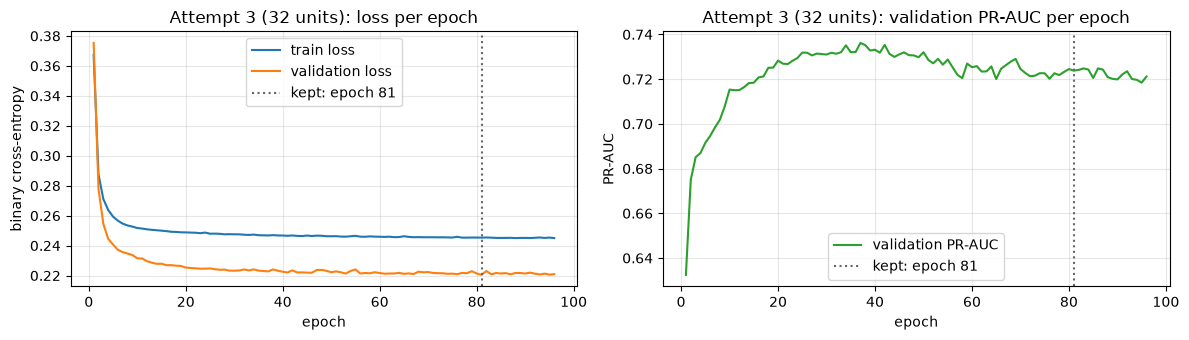

Stopped after 96 epochs, kept epoch 81; validation threshold 0.51


,ROC-AUC,PR-AUC,F1,precision,recall,threshold
attempt 2: tuned LR (before),0.9298,0.7341,0.7094,0.6351,0.8034,0.26
attempt 3: NN 32 (after),0.9319,0.7238,0.7059,0.7500,0.6667,0.51
change,0.0021,-0.0103,-0.0036,0.1149,-0.1368,0.25


In [77]:
nn_small = ShallowNN(hidden=(32,)).fit(X_train, y_train, X_val, y_val)
plot_nn_history(nn_small, 'Attempt 3 (32 units)', 'nn_attempt3_curves')
proba_nn_small_val = nn_small.predict_proba(X_val)[:, 1]
nn_small_threshold = best_threshold(y_val, proba_nn_small_val)
modeling_attempts['3. NN, 1 hidden layer (32)'] = evaluate(y_val, proba_nn_small_val, nn_small_threshold) | {'threshold': nn_small_threshold}

nn3_before_after = pd.DataFrame({'attempt 2: tuned LR (before)': modeling_attempts['2. LR, tuned C / penalty / class weight'],
                                 'attempt 3: NN 32 (after)': modeling_attempts['3. NN, 1 hidden layer (32)']}).T
nn3_before_after.loc['change'] = nn3_before_after.iloc[1] - nn3_before_after.iloc[0]
print(f'Stopped after {len(nn_small.history_)} epochs, kept epoch {nn_small.best_epoch_}; validation threshold {nn_small_threshold}')
nn3_before_after.round(4)

**Result of attempt 3.** Early stopping ran 96 epochs and kept epoch 81. Train and validation loss fall together and flatten, with no sign of the validation loss turning up. It stays *below* the train loss throughout because the training rows include the hard early seasons, the same effect as the train scores in 11.1.

The validation PR-AUC tells a different story. It peaked around epoch 35–40 (about 0.736) and then slipped to 0.724 while the loss kept improving. The later epochs improve the probabilities' calibration (the loss), not the ranking (PR-AUC), so stopping on the loss does not stop at the best ranking.

Against the tuned logistic regression:
- ROC-AUC is slightly higher (+0.002), but PR-AUC is lower (−0.010, about twice the noise level).
- At its own threshold (0.51) it trades recall for precision: recall 0.67 vs 0.80, precision 0.75 vs 0.64. F1 is about the same.

A small network without regularization does not beat the linear model.

### 12.3 Attempt 4: two hidden layers, dropout and weight decay

A bigger network gives more room for non-linear effects and interactions: 16 → 64 → 32 → 1. Two regularizers stop it from memorizing the training seasons:
- **Dropout 0.2:** during training, 20% of the hidden units are switched off at random in each batch, so the network cannot rely on single units.
- **Weight decay 1e-4:** Adam's L2 penalty on the weights.

We try a tiny grid, each option chosen by validation PR-AUC:
- **Learning rate** 0.001 or 0.003.
- **`pos_weight`** none or 6.4 (non-podium ÷ podium rows in train). With 6.4, every podium row counts 6.4 times in the loss, the network's version of `class_weight='balanced'`.

Early stopping on the validation loss as before.

In [78]:
NEG_POS_RATIO = float((y_train == 0).sum() / (y_train == 1).sum())
NN_GRID = [{'lr': lr, 'pos_weight': pw} for lr in [1e-3, 3e-3] for pw in [None, NEG_POS_RATIO]]
nn_candidates, nn_trials = {}, []
for params in NN_GRID:
    candidate = ShallowNN(hidden=(64, 32), dropout=0.2, weight_decay=1e-4, **params).fit(X_train, y_train, X_val, y_val)
    proba = candidate.predict_proba(X_val)[:, 1]
    key = (params['lr'], params['pos_weight'])
    nn_candidates[key] = candidate
    nn_trials.append({'learning rate': params['lr'], 'pos_weight': 'none' if params['pos_weight'] is None else round(params['pos_weight'], 2),
                      'epochs run': len(candidate.history_), 'epoch kept': candidate.best_epoch_,
                      'val PR-AUC': average_precision_score(y_val, proba), 'val ROC-AUC': roc_auc_score(y_val, proba), 'key': key})
nn_grid = pd.DataFrame(nn_trials).sort_values(['val PR-AUC', 'val ROC-AUC'], ascending=False).reset_index(drop=True)
nn_grid.drop(columns='key').round(4)

,learning rate,pos_weight,epochs run,epoch kept,val PR-AUC,val ROC-AUC
0,0.001,6.44,45,30,0.7335,0.9304
1,0.001,none,45,30,0.7331,0.9311
2,0.003,none,55,40,0.7271,0.9303
3,0.003,6.44,33,18,0.7267,0.9298


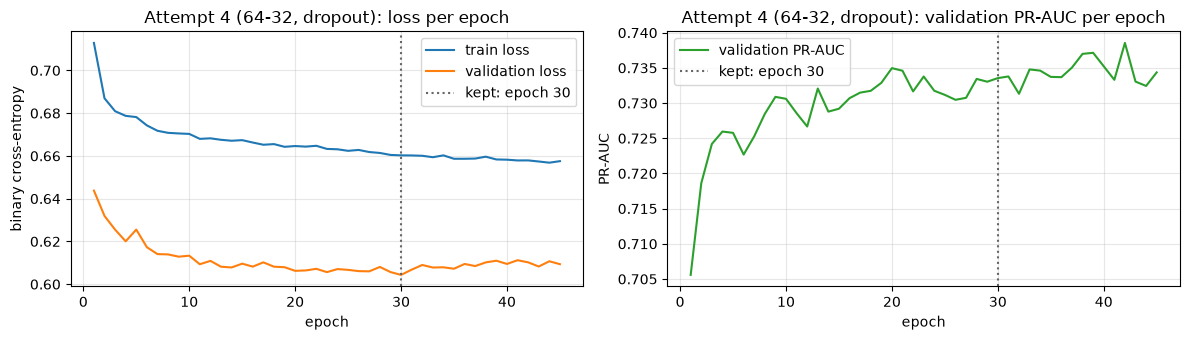

Selected: {'learning rate': 0.001, 'pos_weight': 6.435483870967742} | kept epoch 30 | validation threshold 0.66


,ROC-AUC,PR-AUC,F1,precision,recall,threshold
attempt 3: NN 32 (before),0.9319,0.7238,0.7059,0.750,0.6667,0.51
attempt 4: NN 64-32 (after),0.9304,0.7335,0.7063,0.625,0.8120,0.66
change,-0.0015,0.0097,0.0004,-0.125,0.1453,0.15


In [79]:
nn_large = nn_candidates[nn_grid.loc[0, 'key']]
plot_nn_history(nn_large, 'Attempt 4 (64-32, dropout)', 'nn_attempt4_curves')
proba_nn_large_val = nn_large.predict_proba(X_val)[:, 1]
nn_large_threshold = best_threshold(y_val, proba_nn_large_val)
modeling_attempts['4. NN, 2 hidden layers (64-32) + dropout'] = evaluate(y_val, proba_nn_large_val, nn_large_threshold) | {'threshold': nn_large_threshold}

nn4_before_after = pd.DataFrame({'attempt 3: NN 32 (before)': modeling_attempts['3. NN, 1 hidden layer (32)'],
                                 'attempt 4: NN 64-32 (after)': modeling_attempts['4. NN, 2 hidden layers (64-32) + dropout']}).T
nn4_before_after.loc['change'] = nn4_before_after.iloc[1] - nn4_before_after.iloc[0]
print('Selected:', {'learning rate': nn_large.lr, 'pos_weight': nn_large.pos_weight}, f'| kept epoch {nn_large.best_epoch_} | validation threshold {nn_large_threshold}')
nn4_before_after.round(4)

In [80]:
# final network: the better of attempts 3 and 4 on validation PR-AUC
nn_choice = max([('3. NN, 1 hidden layer (32)', nn_small), ('4. NN, 2 hidden layers (64-32) + dropout', nn_large)],
                key=lambda item: modeling_attempts[item[0]]['PR-AUC'])
nn_model = nn_choice[1]
models_to_compare['shallow NN'] = nn_model
print('Registered as the shallow NN:', nn_choice[0])

Registered as the shallow NN: 4. NN, 2 hidden layers (64-32) + dropout


**Result of attempt 4.**
- **Learning rate:** 0.001 is ahead of 0.003 by about 0.006 PR-AUC (around the noise level). With 0.003 the curves are noisier.
- **`pos_weight`:** none and 6.4 tie (0.7331 vs 0.7335); 6.4 is selected.
- **Overall:** the selected network recovers what attempt 3 lost (+0.010 PR-AUC), and ends level with the logistic regression (0.7335 vs 0.7341). Early stopping kept epoch 30 of 45.

With `pos_weight` = 6.4 every podium row counts 6.4 times in the loss, so the network's probabilities are inflated. That is why its F1-optimal threshold is 0.66 and not about 0.3. Ranking metrics are unaffected. The inference function (section 16) must use this threshold, and 0.66 is not a calibrated probability.

The better of attempts 3 and 4 on validation PR-AUC is attempt 4. It is registered as `models_to_compare['shallow NN']`.

**Why the network is not clearly better than the baseline.**
- The 9 inputs are strong, already-engineered summaries (grid, qualifying, standings, form), and their relation to the podium is close to monotonic: a better grid slot or standing means more podiums. A linear model on the log-odds scale already captures most of that.
- The groups overlap (8.2), so there is little left for interactions to add.
- The validation set is small (39 races, 117 podiums), so differences below about 0.01 PR-AUC cannot be told apart.

**Limitations.**
- **No readable weights.** Explaining the network needs SHAP or permutation importance (section 15).
- **More settings chosen on validation.** Layers, dropout, learning rate, `pos_weight` and the stopping epoch are all chosen on the same small validation set, so its validation score is more optimistic than the logistic regression's.
- **One model for every era,** like the logistic regression.

## 13. Model comparison

Every model in `models_to_compare` is scored the same way: one threshold per model, chosen on validation, then ROC-AUC, PR-AUC, F1, precision and recall on train, validation and, once, test.

### 13.1 Metrics

**Primary metric: PR-AUC** (average precision). Podiums are the rare class (15% of validation and test rows), and PR-AUC measures how well a model ranks the actual podium finishers above everyone else. A random ranking scores about the podium rate, so we report the base rate next to it. Data decisions in sections 7–9 used it too.

**Secondary metric: ROC-AUC.** It does not depend on the base rate, so it can be compared across splits and eras. With so many easy negatives (the back of the grid) it is high for every reasonable model (about 0.93), so it separates models less well than PR-AUC.

**F1 at a fixed threshold.** F1 needs a yes/no prediction, so it depends on the threshold. Each model's threshold is chosen on validation with `best_threshold` (the F1-optimal one), then applied unchanged to train and test. Precision and recall explain the F1. The brief asks for "all five metrics" but its table lists three; we report ROC-AUC, PR-AUC, F1, precision and recall.

Every model in `models_to_compare` is scored the same way, on the same rows and the same 9 features. **The test set is scored once, in 13.4, after every model and threshold has been fixed.**

### 13.2 Split check

Before scoring, we re-check that the split is still the one from section 7 and that the matrices match the modeling table:

In [81]:
split_years = model_table.groupby('split')['year'].agg(['min', 'max'])
assert split_years.loc['train', 'max'] <= 2019 and split_years.loc['val', 'min'] == 2020
assert split_years.loc['val', 'max'] == 2021 and split_years.loc['test', 'min'] == 2022
assert model_table.groupby('raceId')['split'].nunique().max() == 1, 'a race is split across sets'
assert not model_table.duplicated(KEY).any(), '(raceId, driverId) is not unique'
for X, y, name in [(X_train, y_train, 'train'), (X_val, y_val, 'val'), (X_test, y_test, 'test')]:
    assert list(X.columns) == SELECTED, f'X_{name} does not hold exactly the selected features'
    assert X.index.equals(model_table.index[model_table['split'] == name]) and y.index.equals(X.index)
EXPECTED_SPLIT = {'train': (22589, 0.134), 'val': (779, 0.150), 'test': (1356, 0.150)}
split_check = pd.DataFrame({name: {'rows': len(y), 'podium rate': round(y.mean(), 3), 'seasons': f"{split_years.loc[name, 'min']}-{split_years.loc[name, 'max']}"}
                            for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]}).T
for name, (rows, rate) in EXPECTED_SPLIT.items():
    assert split_check.loc[name, 'rows'] == rows and split_check.loc[name, 'podium rate'] == rate, f'{name} split changed'
print('Split checks passed')
split_check

Split checks passed


,rows,podium rate,seasons
train,22589,0.134,1950-2019
val,779,0.15,2020-2021
test,1356,0.15,2022-2024


### 13.3 All attempts, and the final models on train and validation

Every attempt from sections 11–12 on the validation rows, each at its own validation threshold:

In [82]:
attempts_table = pd.DataFrame(modeling_attempts).T
attempts_table.insert(2, 'base rate', y_val.mean())
attempts_table.round(4)

,ROC-AUC,PR-AUC,base rate,F1,precision,recall,threshold
"1. LR, make_lr() as is",0.9295,0.7337,0.1502,0.7094,0.6351,0.8034,0.26
"2. LR, tuned C / penalty / class weight",0.9298,0.7341,0.1502,0.7094,0.6351,0.8034,0.26
"3. NN, 1 hidden layer (32)",0.9319,0.7238,0.1502,0.7059,0.7500,0.6667,0.51
"4. NN, 2 hidden layers (64-32) + dropout",0.9304,0.7335,0.1502,0.7063,0.6250,0.8120,0.66


In [83]:
compare_proba = {name: {'train': model.predict_proba(X_train)[:, 1], 'validation': model.predict_proba(X_val)[:, 1]}
                 for name, model in models_to_compare.items()}
compare_threshold = {name: best_threshold(y_val, p['validation']) for name, p in compare_proba.items()}
fit_rows = []
for name, p in compare_proba.items():
    for split, y in [('train', y_train), ('validation', y_val)]:
        fit_rows.append({'model': name, 'split': split, 'threshold': compare_threshold[name],
                         **evaluate(y, p[split], compare_threshold[name]), 'base rate': y.mean()})
comparison_train_val = pd.DataFrame(fit_rows).set_index(['model', 'split'])
comparison_train_val = comparison_train_val[['threshold', 'ROC-AUC', 'PR-AUC', 'base rate', 'F1', 'precision', 'recall']]
comparison_train_val.round(4)

threshold  ROC-AUC  PR-AUC  base rate      F1  precision  recall
model               split                                                                       
logistic regression train            0.26   0.8995  0.5680     0.1345  0.5881     0.4937  0.7271
                    validation       0.26   0.9298  0.7341     0.1502  0.7094     0.6351  0.8034
shallow NN          train            0.66   0.9059  0.5825     0.1345  0.5856     0.4684  0.7811
                    validation       0.66   0.9304  0.7335     0.1502  0.7063     0.6250  0.8120

**Overfitting check.** The training rows cover 1950–2019, when podiums were much harder to predict (bigger fields, poor reliability), so train scores are *lower* than validation scores for every model (section 7). A negative train − validation gap is therefore expected, not a sign of a good fit. To compare like with like we also score the most recent training seasons, 2014–2019 (the hybrid era, closest to validation). If a model had memorized its training rows, these would score far above validation.

In [84]:
recent = model_table.index[(model_table['split'] == 'train') & (model_table['year'] >= 2014)]
overfit_rows = []
for name, model in models_to_compare.items():
    p_train, p_val = compare_proba[name]['train'], compare_proba[name]['validation']
    p_recent = model.predict_proba(X_train.loc[recent])[:, 1]
    overfit_rows.append({'model': name,
                         'train PR-AUC': average_precision_score(y_train, p_train),
                         'train 2014-19 PR-AUC': average_precision_score(y_train.loc[recent], p_recent),
                         'validation PR-AUC': average_precision_score(y_val, p_val),
                         'gap (train 2014-19 - val)': average_precision_score(y_train.loc[recent], p_recent) - average_precision_score(y_val, p_val),
                         'train ROC-AUC': roc_auc_score(y_train, p_train),
                         'train 2014-19 ROC-AUC': roc_auc_score(y_train.loc[recent], p_recent),
                         'validation ROC-AUC': roc_auc_score(y_val, p_val)})
pd.DataFrame(overfit_rows).set_index('model').round(4)

,train PR-AUC,train 2014-19 PR-AUC,validation PR-AUC,gap (train 2014-19 - val),train ROC-AUC,train 2014-19 ROC-AUC,validation ROC-AUC
model,,,,,,,
logistic regression,0.5680,0.7340,0.7341,-0.0001,0.8995,0.9436,0.9298
shallow NN,0.5825,0.7471,0.7335,0.0135,0.9059,0.9519,0.9304


**Reading the tables.**
- **Validation:** the two final models are tied. PR-AUC is 0.7341 (LR) vs 0.7335 (NN), ROC-AUC 0.930 for both, F1 0.709 vs 0.706, all far above the 0.150 base rate.
- **Full training set:** both score lower (PR-AUC 0.57–0.58), the era effect described above.
- **Overfitting:**
  - On the 2014–2019 training rows the logistic regression scores exactly as on validation (0.734 vs 0.734), so it does not overfit.
  - The network scores 0.013 higher on its own recent training rows than on validation. This small gap shows it fits the training data more closely; early stopping and dropout keep it small.

**Choice on validation.** The two models tie within the noise level. By the rule used throughout (7.1: a tie goes to the simpler option), the **logistic regression** is the main model. It is simpler, its weights can be read directly, and fewer of its settings were fitted to the validation set.

### 13.4 Test set (scored once)

The models, their hyperparameters and their thresholds are now fixed. The test seasons 2022–2024 (the new ground-effect era) are scored once:

In [85]:
for name, model in models_to_compare.items():
    compare_proba[name]['test'] = model.predict_proba(X_test)[:, 1]
comparison_test = pd.DataFrame({name: {'threshold': compare_threshold[name], **evaluate(y_test, p['test'], compare_threshold[name]),
                                       'base rate': y_test.mean()}
                                for name, p in compare_proba.items()}).T
comparison_test.index.name = 'model'
comparison_test = comparison_test[['threshold', 'ROC-AUC', 'PR-AUC', 'base rate', 'F1', 'precision', 'recall']]
comparison_test.round(4)

,threshold,ROC-AUC,PR-AUC,base rate,F1,precision,recall
model,,,,,,,
logistic regression,0.26,0.9349,0.7058,0.1504,0.6747,0.569,0.8284
shallow NN,0.66,0.9409,0.7176,0.1504,0.6807,0.558,0.8725


**How certain are the test scores?** The test set has only 68 races, so we resample it: 1,000 times we draw 68 races with replacement (whole races, because the three podium places of a race belong together) and recompute every model's PR-AUC on the same resampled rows. This reuses the predictions above; nothing is refitted or re-chosen. The last columns compare each model with the logistic regression on the same resamples.

In [86]:
test_race = model_table.loc[X_test.index, 'raceId'].to_numpy()
race_rows = [np.flatnonzero(test_race == r) for r in np.unique(test_race)]
y_test_values = y_test.to_numpy()
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    idx = np.concatenate([race_rows[i] for i in rng.integers(0, len(race_rows), len(race_rows))])
    boot.append({name: average_precision_score(y_test_values[idx], p['test'][idx]) for name, p in compare_proba.items()})
boot = pd.DataFrame(boot)
reference = 'logistic regression' if 'logistic regression' in boot else boot.columns[0]
boot_table = pd.DataFrame({'test PR-AUC': comparison_test['PR-AUC'],
                           '95% interval: low': boot.quantile(0.025), '95% interval: high': boot.quantile(0.975),
                           f'minus {reference}: low': boot.sub(boot[reference], axis=0).quantile(0.025),
                           f'minus {reference}: high': boot.sub(boot[reference], axis=0).quantile(0.975),
                           f'share of resamples above {reference}': boot.gt(boot[reference], axis=0).mean()})
boot_table.round(4)

,test PR-AUC,95% interval: low,95% interval: high,minus logistic regression: low,minus logistic regression: high,share of resamples above logistic regression
logistic regression,0.7058,0.6469,0.7721,0.000,0.0000,0.000
shallow NN,0.7176,0.6587,0.7803,-0.008,0.0276,0.849


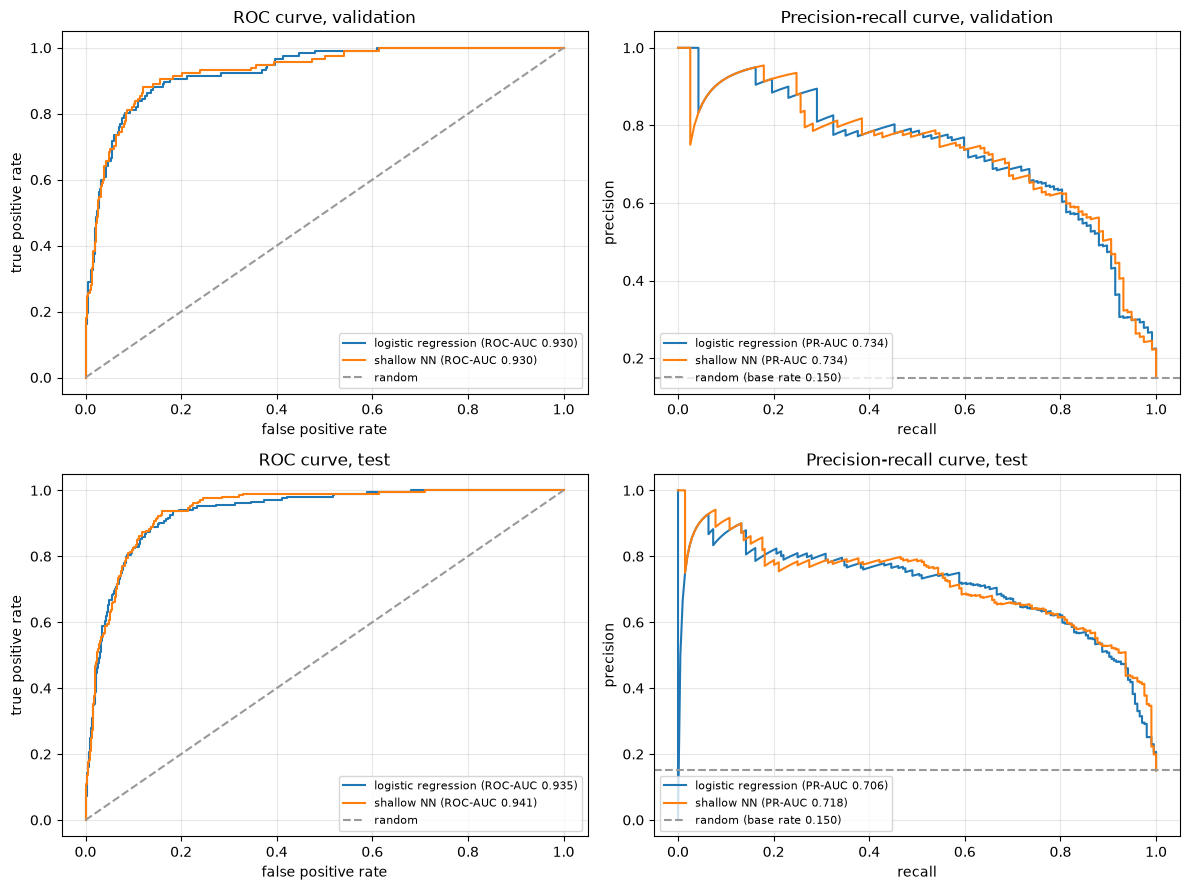

In [87]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (split, y) in enumerate([('validation', y_val), ('test', y_test)]):
    ax_roc, ax_pr = axes[row]
    for i, (name, p) in enumerate(compare_proba.items()):
        fpr, tpr, _ = roc_curve(y, p[split])
        ax_roc.plot(fpr, tpr, color=f'C{i}', label=f'{name} (ROC-AUC {roc_auc_score(y, p[split]):.3f})')
        precision, recall, _ = precision_recall_curve(y, p[split])
        ax_pr.plot(recall, precision, color=f'C{i}', label=f'{name} (PR-AUC {average_precision_score(y, p[split]):.3f})')
    ax_roc.plot([0, 1], [0, 1], color='0.6', ls='--', label='random')
    ax_pr.axhline(y.mean(), color='0.6', ls='--', label=f'random (base rate {y.mean():.3f})')
    ax_roc.set(title=f'ROC curve, {split}', xlabel='false positive rate', ylabel='true positive rate')
    ax_pr.set(title=f'Precision-recall curve, {split}', xlabel='recall', ylabel='precision')
    ax_roc.legend(loc='lower right', fontsize=8)
    ax_pr.legend(loc='lower left', fontsize=8)
plt.tight_layout()
save_fig('comparison_roc_pr_curves')
plt.show()

**Test result (2022–2024, the new ground-effect era).**

*Ranking.* Both models hold up:
- PR-AUC is 0.706 (LR) and 0.718 (NN), against a base rate of 0.150.
- ROC-AUC is 0.935 and 0.941, slightly *higher* than on validation.
- PR-AUC is 0.016–0.028 lower than on validation.

*Threshold.* At the thresholds fixed on validation:
- Recall stays high (0.83 LR, 0.87 NN), but precision drops (0.57 and 0.56, vs 0.64 and 0.63 on validation).
- So F1 falls from about 0.71 to 0.67–0.68.

The thresholds chosen on 2020–21 are a little too low for 2022–24, which shows how sensitive a fixed threshold is to drift between eras.

**Network vs logistic regression on test.** The network is ahead by +0.012 PR-AUC and +0.006 ROC-AUC. The race-level bootstrap puts the PR-AUC difference between −0.008 and +0.028 (95% interval), with the network ahead in 85% of the resamples. The difference is not established, and it is consistent with the tie on validation. Each model's own test PR-AUC is uncertain by about ±0.06 (LR: 0.647–0.772).

**Conclusion.**
- Both models were chosen on validation, where they tie, and the test score does not change that choice: switching now would mean choosing on test.
- The **logistic regression is the main model**: the simplest, interpretable, no sign of overfitting, test PR-AUC 0.706 (95% interval 0.647–0.772) against a base rate of 0.150.
- The **shallow network** reaches the same level (test PR-AUC 0.718) but does not clearly improve on it.

The predictive signal is in the engineered features, not in the model's flexibility. The forward selection in 8.3 points the same way: logistic regression and a tree model were also close there.

## 14. Feature-group ablation

*To do.* Retrain the chosen model once per group in `FEATURE_GROUPS`, each time without that group, and report the drop in validation PR-AUC / ROC-AUC / F1. Section 8.3 already shows the forward version made before training; the ablation is the after-training measurement the brief asks for.

## 15. Explainability (XAI)

*To do.* Global: permutation importance and SHAP. Local: one prediction explained with LIME and/or a SHAP waterfall. State explicitly that importance means the model relies on a feature, not that the feature causes podiums.

## 16. Inference function

*To do.* A function that takes one driver–race record (the values of `SELECTED`) and returns the podium probability and the 0/1 prediction at the chosen threshold. Demonstrate it on a complete record and on a record with missing values (for example no qualifying data); the imputer in `make_preprocessor()` handles the missing values.

## 17. Assumptions and limitations

**Assumptions** made in the data sections, each tested or justified where it is made:

| Assumption | Evidence | Section |
| --- | --- | --- |
| A `q1` time above 150% of the race's fastest `q1` is a data-entry error | one such time (1023%); the next slowest is 145% | 3.1 |
| The car a driver started in is the one nobody else drove, otherwise the first listed row | 88 of the 91 rows not kept are cars another driver started | 3.3 |
| A driver credited with a podium in a shared car has `podium = 1` | official classification (rule D) | 3.3 |
| A driver with a grid slot or at least one completed lap is on the starting list at the cutoff | entries with neither have no podium; whether a driver starts is known before the lights go out (10 of them qualified and then did not start); removing only `F` or nothing scores the same or worse on the same rows | 3.4, 8.3 |
| Who drove which car in a shared drive may be used to pick the row | used only to recover the driver's own car and grid slot, never as a feature | 3.3 |
| `grid = 0` with laps is a pit-lane start, placed behind the last car | 72 rows, all 2015–2024; the three encodings score the same | 3.4, 9.1 |
| The Indianapolis 500 is a separate population | 96% of its drivers never raced another championship race | 3.4 |
| Known at the cutoff: the grid, the qualifying result, the standings after the previous round | the cutoff is after qualifying; checked automatically for round 1 and for form | 6.1, 6.3 |
| Nationality → country: dual nationalities take the first, `East German` → Germany | hand-made map, printed in full | Q2 |
| Tyre failures, punctures, fire and safety belt are mechanical, refuelling is not | course staff's clarification of the definition | Q3 |
| Ambiguous statuses (bare `Retired`, wing, wheel, damage, ...) are not mechanical | counting them as mechanical keeps the same leaders | Q3 |
| One `constructorId` / `circuitId` is one team / circuit (renamed teams and changed layouts are not merged) | the dataset has no lineage table; stated next to the answers | Q1, Q3 |
| A score difference below 2 × the spread from dropping 1% of training rows is noise | measured: 0.005 (LR), 0.011 (tree model) | 7.1 |
| "After the 2014 hybrid era" in question 1 means from 2014 on | the hybrid era began in 2014; using 2014–2021 only gives the same answer | Q1 |
| Missing feature values can be filled (median of the training rows plus an indicator) | dropping incomplete rows or columns is worse; other fills tie or are worse | 9.1 |

**Limitations** on the data and feature side (to be completed with the modeling limitations):

- **Qualifying coverage drift.** No qualifying data before 1994 and only 6–59% coverage in 1996–2002, so 63% of the training rows have imputed qualifying features. The missing indicators let a model treat those rows differently, but the qualifying signal itself is learned from 37% of the training rows.
- **Era sensitivity.** The grid-to-podium relationship and reliability changed a lot (pole to podium 53% in 1950–69, 81% since 2014; about half of the starters finished before 2000, 86% in the 2020s). Training on every season mixes these eras; the test seasons are a new regulation era.
- **Renamed teams.** A renamed team gets a new `constructorId` (Renault → Alpine, Toro Rosso → AlphaTauri → RB). The constructor standings restart every season anyway (round 1 has none, checked in 6.3), so a rename between seasons costs the selected features nothing; only cross-season team history would be lost, which only the team candidates used (constructor form, team circuit history, team reliability; none selected, 8.3). In question 3 a renamed team counts as a separate constructor, and the combined rate is given for Alfa Romeo + Sauber.
- **Manual mappings.** The status groups (question 3) and the nationality → country map (question 2) are judgement calls, documented in the tables above; question 3 includes a sensitivity check.
- **Overlapping feature groups.** Qualifying, standings and driver form all measure current pace, so removing one of them costs little while the others are present (8.3). The ablation in section 14 will show small drops for each and should be read with this in mind; for qualifying the gain was within the noise level once the other groups were in.
- **Small validation windows.** Each two-season window is about 40 races, so differences below about 0.01 PR-AUC are within noise. Several of our choices were ties and were decided on domain grounds; this is stated next to each one.
- **Not used.** Sprint results (not leakage, but no training rows have one; 6.4), pit stops and lap times (in-race), and seven candidate groups whose gain was within the noise level or negative (constructor form, teammate, circuit history, reliability, experience, field size, home; 8.3).